
# CredResolve: Recovery Performance Investigation

## 1. Objective

This notebook investigates the claim that recovery improved by 11% month-on-month. The analysis examines payment trends, data quality, entity relationships, portfolio composition, campaign-targeting associations, and statistical uncertainty.

The goal is to determine what the available data supports, identify limitations that could distort recovery reporting, and recommend a defensible next step for investment decisions.

## 2. Data and methodology

The analysis uses the supplied CSV datasets, including payments, accounts, borrowers, calls, targeting, campaign metadata, agent records, communication events, promises to pay, field visits, complaints, and account-status history.

The original files in `data/raw/` are preserved. Cleaning and reconciliation outputs are saved separately under `data/staging/` and `data/golden/`. Quality flags are used to expose unresolved issues rather than silently inventing missing values or relationships.

## 3. Key measurement definitions

- **Gross successful payment amount:** Sum of amounts recorded with payment status `SUCCESS`. Currency semantics are unconfirmed.
- **Payment success share:** Number of `SUCCESS` payment records divided by all payment records in the relevant month.
- **Account-level success share:** Accounts with at least one `SUCCESS` payment divided by accounts with payment activity in that month.
- **Targeting-to-payment association:** Share of targeting events followed by a `SUCCESS` payment within a defined window. This is not a causal effect.
- **Verified net recovery:** Not reliably calculable from the current data until currency, transaction linkage, and reversal treatment are confirmed.

## 4. Data-quality principles

1. Preserve raw source files.
2. Deduplicate only where a defensible key and reconciliation rule exist.
3. Retain conflicting borrower and agent records for review.
4. Do not infer reversal linkage from payment reference alone.
5. Do not assume timezone or currency semantics that are not documented.
6. Separate facts, statistical evidence, correlations, and hypotheses.

## 5. Notebook navigation

The notebook first profiles the supplied datasets, then investigates payment and entity integrity, timestamps, communication and targeting data, and portfolio composition. Later sections quantify monthly changes, perform statistical comparisons, examine targeting attribution risks, and produce supporting reports.

## 6. Executive conclusion

The observed gross successful payment amount increased by 11.03% from February to March 2026, but payment success share decreased. The preliminary payment-level and account-level tests do not show statistically significant success-share improvement. The available evidence therefore does not establish a sustained 11% improvement in underlying recovery.

August is a partial month. Borrower mappings conflict extensively, reversal linkage remains unresolved, and currency and timezone semantics are not fully established. Investment decisions should be based on validated recovery metrics and a controlled experiment rather than observational attribution alone.


## 1. Environment Setup and Data Inventory

This section verifies the Python environment and inventories the supplied source files before analysis begins. The original raw datasets are preserved.

In [109]:
import sys
import pandas as pd
import numpy as np

print("Python version:", sys.version)
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)


Python version: 3.14.2 (tags/v3.14.2:df79316, Dec  5 2025, 17:18:21) [MSC v.1944 64 bit (AMD64)]
Pandas version: 3.1.0
NumPy version: 2.5.4


In [110]:
from pathlib import Path

DATA_DIR = Path("../data/raw")

print("Current working directory:", Path.cwd())
print("Data folder exists:", DATA_DIR.exists())

csv_files = sorted(DATA_DIR.glob("*.csv"))

print("Number of CSV files:", len(csv_files))

for file in csv_files:
    print(file.name)

Current working directory: c:\Users\Mateti\OneDrive\Desktop\CredResolve_Assignment\notebooks
Data folder exists: True
Number of CSV files: 19
account_status_history.csv
accounts.csv
agent_sessions.csv
agents.csv
borrowers.csv
call_attempts.csv
call_dispositions.csv
calls.csv
campaigns.csv
complaints.csv
daily_targeting.csv
data_dictionary.csv
field_visits.csv
golden_payments_candidate.csv
payments.csv
promises_to_pay.csv
sms_events.csv
vendor_telephony.csv
whatsapp_events.csv


In [111]:
import pandas as pd

inventory = []
for file in csv_files:
    df = pd.read_csv(file, low_memory=False)

    inventory.append({
        "file_name": file.name,
        "row_count": len(df),
        "column_count": len(df.columns),
        "duplicate_full_rows": int(df.duplicated().sum()),
        "columns": ", ".join(df.columns)
    })

inventory_df = pd.DataFrame(inventory)

display(inventory_df)

,file_name,row_count,column_count,duplicate_full_rows,columns
0,account_status_history.csv,60000,8,0,"history_id, account_id, borrower_id, event_at,..."
1,accounts.csv,30000,11,0,"account_id, borrower_id, loan_type, principal_..."
2,agent_sessions.csv,15000,7,0,"session_id, agent_id, login_at, channel, devic..."
3,agents.csv,30000,8,0,"agent_id, employee_code, agent_name, vendor_id..."
4,borrowers.csv,30600,8,600,"borrower_id, name, phone, email, city, created..."
5,call_attempts.csv,120000,9,0,"attempt_id, account_id, borrower_id, event_at,..."
6,call_dispositions.csv,35000,8,0,"disposition_id, account_id, borrower_id, event..."
7,calls.csv,91350,11,1271,"call_id, account_id, borrower_id, event_at, ag..."
8,campaigns.csv,120,7,0,"campaign_id, campaign_name, channel, strategy_..."
9,complaints.csv,8000,9,0,"complaint_id, account_id, borrower_id, event_a..."


In [112]:
REPORT_DIR = Path("../reports")
REPORT_DIR.mkdir(parents=True, exist_ok=True)

inventory_df.to_csv(REPORT_DIR / "data_inventory.csv", index=False)

print("Inventory report saved successfully. ")

Inventory report saved successfully. 


In [113]:
quality_reports = []

for file in csv_files:
    df= pd.read_csv(file, low_memory=False)

    #Skip the data dictionary for operational data profiling
    if file.name == "data_dictionary.csv":
        continue

    quality_reports.append({
        "file_name": file.name,
        "total_rows": len(df),
        "total_columns": len(df.columns),
        "duplicate_full_rows": int(df.duplicated().sum()),
        "total_missing_cells": int(df.isna().sum().sum()),
        "columns_with_missing_values": int(df.isna().any().sum()),
        "missing_value_percentage": round(df.isna().sum().sum() / (df.shape[0] * df.shape[1]) * 100, 2)
        if df.size else 0
    })

quality_df = pd.DataFrame(quality_reports)

display(
    quality_df.sort_values(
        by="missing_value_percentage", ascending=False
    )
)



,file_name,total_rows,total_columns,duplicate_full_rows,total_missing_cells,columns_with_missing_values,missing_value_percentage
4,borrowers.csv,30600,8,600,1509,2,0.62
5,call_attempts.csv,120000,9,0,2400,1,0.22
7,calls.csv,91350,11,1271,1827,1,0.18
13,payments.csv,25500,9,486,382,1,0.17
12,golden_payments_candidate.csv,25000,9,0,368,1,0.16
1,accounts.csv,30000,11,0,455,1,0.14
11,field_visits.csv,25000,10,0,250,1,0.10
0,account_status_history.csv,60000,8,0,0,0,0.00
2,agent_sessions.csv,15000,7,0,0,0,0.00
3,agents.csv,30000,8,0,0,0,0.00


In [114]:
print(quality_df.columns.tolist())

['file_name', 'total_rows', 'total_columns', 'duplicate_full_rows', 'total_missing_cells', 'columns_with_missing_values', 'missing_value_percentage']


In [115]:
quality_df.to_csv(
    REPORT_DIR / "data_quality_initial.csv",
    index=False
)

print("Initial data quality report saved.")

Initial data quality report saved.


In [116]:

display(
    quality_df[
        [
            "file_name",
            "total_rows",
            "duplicate_full_rows",
            "total_missing_cells",
            "columns_with_missing_values",
            "missing_value_percentage"
        ]
    ].sort_values(
        by="missing_value_percentage",
        ascending=False
    ).to_string(index=False)
)


'                    file_name  total_rows  duplicate_full_rows  total_missing_cells  columns_with_missing_values  missing_value_percentage\n                borrowers.csv       30600                  600                 1509                            2                      0.62\n            call_attempts.csv      120000                    0                 2400                            1                      0.22\n                    calls.csv       91350                 1271                 1827                            1                      0.18\n                 payments.csv       25500                  486                  382                            1                      0.17\ngolden_payments_candidate.csv       25000                    0                  368                            1                      0.16\n                 accounts.csv       30000                    0                  455                            1                      0.14\n             field_

In [117]:

payments = pd.read_csv(
    DATA_DIR / "payments.csv",
    low_memory=False
)

print("Payment columns:")
print(payments.columns.tolist())

display(payments.head(10))


Payment columns:
['payment_id', 'account_id', 'borrower_id', 'event_at', 'payment_reference', 'amount', 'payment_status', 'payment_method', 'provider_id']


,payment_id,account_id,borrower_id,event_at,payment_reference,amount,payment_status,payment_method,provider_id
0,PAYMENT0000001,ACC0015539,BRW0011363,2026-02-27 01:28:12,TXN0000007457,22433.23,FAILED,CARD,VND0000001
1,PAYMENT0000002,ACC0004445,BRW0011306,2026-07-23 20:25:20,TXN0000030016,23295.11,FAILED,UPI,VND0000004
2,PAYMENT0000003,ACC0003853,BRW0002549,2026-01-11 21:27:46,TXN0000010466,118814.97,FAILED,NACH,VND0000013
3,PAYMENT0000004,ACC0017531,BRW0006618,2026-06-16 02:35:21,TXN0000031781,145082.17,REVERSED,CASH,VND0000013
4,PAYMENT0000005,ACC0001770,BRW0011492,2026-03-03 06:08:23,TXN0000059257,115148.46,SUCCESS,NETBANKING,VND0000013
5,PAYMENT0000006,ACC0002408,BRW0009136,2026-05-25 10:59:51,TXN0000052202,142468.84,SUCCESS,CARD,VND0000012
6,PAYMENT0000007,ACC0017147,BRW0004710,2026-05-08 11:45:34,TXN0000050767,79641.72,SUCCESS,NETBANKING,VND0000008
7,PAYMENT0000008,ACC0027360,BRW0008644,2026-01-16 08:37:42,TXN0000061682,80638.15,SUCCESS,CARD,VND0000009
8,PAYMENT0000009,ACC0005092,BRW0003019,2026-03-31 08:11:38,TXN0000046720,75028.44,SUCCESS,CASH,VND0000003
9,PAYMENT0000010,ACC0011343,BRW0010947,2026-07-20 20:51:33,TXN0000031163,80004.84,SUCCESS,UPI,VND0000005


In [118]:

# 1. Load the raw payment data
payments = pd.read_csv(
    DATA_DIR / "payments.csv",
    low_memory=False
)

# 2. Check basic information
print("Total payment rows:", len(payments))
print("Unique payment IDs:", payments["payment_id"].nunique())
print("Unique payment references:", payments["payment_reference"].nunique())
print("Exact duplicate rows:", payments.duplicated().sum())

# 3. Count records by payment status
print("\nPayment status counts:")
display(
    payments["payment_status"]
    .value_counts(dropna=False)
    .rename_axis("payment_status")
    .reset_index(name="record_count")
)

# 4. Compare payment IDs and references
print("\nPayment IDs appearing more than once:")
display(
    payments[payments.duplicated("payment_id", keep=False)]
    .sort_values("payment_id")
    .head(20)
)

print("\nPayment references appearing more than once:")
display(
    payments[
        payments.duplicated("payment_reference", keep=False)
    ]
    .sort_values("payment_reference")
    .head(20)
)


Total payment rows: 25500
Unique payment IDs: 25000
Unique payment references: 20821
Exact duplicate rows: 486

Payment status counts:


,payment_status,record_count
0,SUCCESS,17880
1,FAILED,3744
2,PENDING,2592
3,REVERSED,1284



Payment IDs appearing more than once:


,payment_id,account_id,borrower_id,event_at,payment_reference,amount,payment_status,payment_method,provider_id
55,PAYMENT0000056,ACC0019495,BRW0009716,2026-02-24 09:33:29,TXN0000008612,77982.73,PENDING,NETBANKING,VND0000007
25035,PAYMENT0000056,ACC0019495,BRW0009716,2026-02-24 09:33:29,TXN0000008612,77982.73,PENDING,NETBANKING,VND0000007
75,PAYMENT0000076,ACC0027928,BRW0010869,2026-02-05 17:14:30,TXN0000006417,43712.91,PENDING,UPI,VND0000014
25408,PAYMENT0000076,ACC0027928,BRW0010869,2026-02-05 17:14:30,TXN0000006417,43712.91,PENDING,UPI,VND0000014
107,PAYMENT0000108,ACC0017047,BRW0009175,2026-06-09 08:17:45,TXN0000041404,102830.42,SUCCESS,NACH,VND0000003
25481,PAYMENT0000108,ACC0017047,BRW0009175,2026-06-09 08:17:45,TXN0000041404,102830.42,SUCCESS,NACH,VND0000003
148,PAYMENT0000149,ACC0018444,BRW0005741,2026-07-25 03:04:14,TXN0000066565,96766.12,SUCCESS,CASH,VND0000013
25099,PAYMENT0000149,ACC0018444,BRW0005741,2026-07-25 03:04:14,TXN0000066565,96766.12,SUCCESS,CASH,VND0000013
198,PAYMENT0000199,ACC0000056,BRW0001872,2026-05-12 22:49:22,TXN0000069967,81814.00,SUCCESS,NETBANKING,VND0000012
25330,PAYMENT0000199,ACC0000056,BRW0001872,2026-05-12 22:49:22,TXN0000069967,81814.00,SUCCESS,NETBANKING,VND0000012



Payment references appearing more than once:


,payment_id,account_id,borrower_id,event_at,payment_reference,amount,payment_status,payment_method,provider_id
25010,PAYMENT0000552,ACC0021942,BRW0011343,2026-08-06 18:56:06,TXN0000000009,11792.14,SUCCESS,UPI,VND0000012
551,PAYMENT0000552,ACC0021942,BRW0011343,2026-08-06 18:56:06,TXN0000000009,11792.14,SUCCESS,UPI,VND0000012
1387,PAYMENT0001388,ACC0019483,BRW0003324,2026-01-31 05:00:49,TXN0000000027,53610.92,FAILED,CARD,VND0000005
3477,PAYMENT0003478,ACC0022277,BRW0011422,2026-06-09 12:22:41,TXN0000000027,43010.39,SUCCESS,NACH,VND0000010
5306,PAYMENT0005307,ACC0003975,BRW0007408,2026-05-24 14:49:16,TXN0000000032,18086.24,PENDING,CARD,VND0000003
2884,PAYMENT0002885,ACC0021199,BRW0008425,2026-05-03 23:45:49,TXN0000000032,104969.97,SUCCESS,NACH,VND0000007
21182,PAYMENT0021183,ACC0011292,BRW0006242,2026-04-10 12:10:27,TXN0000000032,15714.97,SUCCESS,CASH,VND0000005
2839,PAYMENT0002840,ACC0022601,BRW0006594,2026-02-01 22:47:46,TXN0000000113,1139.66,SUCCESS,CARD,VND0000003
13292,PAYMENT0013293,ACC0019961,BRW0006917,2026-01-17 20:51:05,TXN0000000113,55554.44,REVERSED,CARD,VND0000007
18917,PAYMENT0018918,ACC0012876,BRW0010206,2026-08-03 02:17:02,TXN0000000113,101681.86,SUCCESS,CARD,VND0000010


In [119]:

# Amounts grouped by recorded payment status
status_summary = (
    payments.groupby("payment_status", dropna=False)
    .agg(
        record_count=("payment_id", "size"),
        unique_payment_ids=("payment_id", "nunique"),
        unique_references=("payment_reference", "nunique"),
        recorded_amount=("amount", "sum")
    )
    .reset_index()
)

display(status_summary)


,payment_status,record_count,unique_payment_ids,unique_references,recorded_amount
0,FAILED,3744,3677,3529,2.835063e+08
1,PENDING,2592,2535,2459,1.948680e+08
2,REVERSED,1284,1254,1224,9.739842e+07
3,SUCCESS,17880,17534,15349,1.341486e+09


In [120]:

# A. Find payment IDs with conflicting records

payment_id_check = (
    payments.groupby("payment_id", dropna=False)
    .agg(
        row_count=("payment_id", "size"),
        distinct_accounts=("account_id", "nunique"),
        distinct_references=("payment_reference", "nunique"),
        distinct_amounts=("amount", "nunique"),
        distinct_statuses=("payment_status", "nunique"),
        distinct_timestamps=("event_at", "nunique")
    )
    .reset_index()
)

repeated_ids = payment_id_check[
    payment_id_check["row_count"] > 1
]

conflicting_ids = repeated_ids[
    (repeated_ids["distinct_accounts"] > 1)
    | (repeated_ids["distinct_references"] > 1)
    | (repeated_ids["distinct_amounts"] > 1)
    | (repeated_ids["distinct_statuses"] > 1)
    | (repeated_ids["distinct_timestamps"] > 1)
]

print("Payment IDs occurring more than once:", len(repeated_ids))
print("Payment IDs with conflicting details:", len(conflicting_ids))

display(conflicting_ids.head(20))


Payment IDs occurring more than once: 500
Payment IDs with conflicting details: 0


,payment_id,row_count,distinct_accounts,distinct_references,distinct_amounts,distinct_statuses,distinct_timestamps


In [121]:

# B. Check whether repeated references have conflicting details

reference_check = (
    payments.groupby("payment_reference", dropna=False)
    .agg(
        row_count=("payment_reference", "size"),
        distinct_payment_ids=("payment_id", "nunique"),
        distinct_accounts=("account_id", "nunique"),
        distinct_borrowers=("borrower_id", "nunique"),
        distinct_amounts=("amount", "nunique"),
        distinct_statuses=("payment_status", "nunique")
    )
    .reset_index()
)

repeated_references = reference_check[
    reference_check["row_count"] > 1
]

conflicting_references = repeated_references[
    (repeated_references["distinct_payment_ids"] > 1)
    | (repeated_references["distinct_accounts"] > 1)
    | (repeated_references["distinct_amounts"] > 1)
    | (repeated_references["distinct_statuses"] > 1)
]

print("Repeated references:", len(repeated_references))
print("References with conflicting details:", len(conflicting_references))

display(conflicting_references.head(20))


Repeated references: 3746
References with conflicting details: 3408


,payment_reference,row_count,distinct_payment_ids,distinct_accounts,distinct_borrowers,distinct_amounts,distinct_statuses
5,TXN0000000027,2,2,2,2,2,2
8,TXN0000000032,3,3,3,3,3,2
28,TXN0000000113,3,3,3,3,3,2
35,TXN0000000132,2,2,2,2,2,1
36,TXN0000000134,2,2,2,2,2,1
39,TXN0000000154,2,2,2,2,2,1
50,TXN0000000186,2,2,2,2,2,1
53,TXN0000000196,2,2,2,2,2,1
58,TXN0000000212,2,2,2,2,2,1
71,TXN0000000271,2,2,2,2,2,1


In [122]:

# Get every row belonging to a repeated payment ID
repeated_payment_rows = payments[
    payments.duplicated("payment_id", keep=False)
].copy()

# Compare the complete records within each payment ID
id_reconciliation = (
    repeated_payment_rows.groupby("payment_id")
    .agg(
        row_count=("payment_id", "size"),
        distinct_complete_records=(
            "payment_id",
            lambda ids: len(
                repeated_payment_rows.loc[
                    ids.index
                ].drop_duplicates()
            )
        )
    )
    .reset_index()
)

# Find payment IDs whose records are not completely identical
id_reconciliation["has_conflicting_records"] = (
    id_reconciliation["distinct_complete_records"] > 1
)

print("Repeated payment ID groups:", len(id_reconciliation))
print(
    "Groups with differing complete records:",
    int(id_reconciliation["has_conflicting_records"].sum())
)

display(
    id_reconciliation[
        id_reconciliation["has_conflicting_records"]
    ].head(20)
)


Repeated payment ID groups: 500
Groups with differing complete records: 14


,payment_id,row_count,distinct_complete_records,has_conflicting_records
24,PAYMENT0001390,2,2,True
44,PAYMENT0002098,2,2,True
54,PAYMENT0002303,2,2,True
126,PAYMENT0005191,2,2,True
167,PAYMENT0007582,2,2,True
174,PAYMENT0007751,2,2,True
193,PAYMENT0008752,2,2,True
226,PAYMENT0010558,2,2,True
353,PAYMENT0016862,2,2,True
374,PAYMENT0018134,2,2,True


In [123]:
conflict_ids = id_reconciliation.loc[
    id_reconciliation["has_conflicting_records"],
    "payment_id"
]

display(
    payments[payments["payment_id"].isin(conflict_ids)]
    .sort_values("payment_id")
    .head(30)
)


,payment_id,account_id,borrower_id,event_at,payment_reference,amount,payment_status,payment_method,provider_id
1389,PAYMENT0001390,ACC0001624,BRW0004200,2026-05-14 07:52:59,TXN0000046535,85205.16,SUCCESS,CASH,VND0000015
25043,PAYMENT0001390,ACC0001624,BRW0004200,2026-05-14 07:52:59,NaN,85205.16,SUCCESS,CASH,VND0000015
2097,PAYMENT0002098,ACC0023839,BRW0008653,2026-07-01 09:19:16,TXN0000001302,5570.92,SUCCESS,NETBANKING,VND0000001
25055,PAYMENT0002098,ACC0023839,BRW0008653,2026-07-01 09:19:16,NaN,5570.92,SUCCESS,NETBANKING,VND0000001
2302,PAYMENT0002303,ACC0021362,BRW0001779,2026-06-15 03:09:47,TXN0000067311,59429.86,SUCCESS,CARD,VND0000011
25057,PAYMENT0002303,ACC0021362,BRW0001779,2026-06-15 03:09:47,NaN,59429.86,SUCCESS,CARD,VND0000011
25437,PAYMENT0005191,ACC0001901,BRW0001234,2026-06-28 13:50:03,TXN0000041890,107235.47,SUCCESS,NACH,VND0000002
5190,PAYMENT0005191,ACC0001901,BRW0001234,2026-06-28 13:50:03,NaN,107235.47,SUCCESS,NACH,VND0000002
25385,PAYMENT0007582,ACC0017962,BRW0008041,2026-03-26 12:49:42,TXN0000013106,119714.20,SUCCESS,NETBANKING,VND0000014
7581,PAYMENT0007582,ACC0017962,BRW0008041,2026-03-26 12:49:42,NaN,119714.20,SUCCESS,NETBANKING,VND0000014


In [124]:
id_reconciliation.to_csv(
    REPORT_DIR / "payment_id_reconciliation.csv",
    index=False
)

print("Payment ID reconciliation saved.")

Payment ID reconciliation saved.


## 2. Payment Data Quality and Reconciliation

This section examines duplicate payment IDs, missing and repeated payment references, payment statuses, and reversal-linkage limitations. A candidate dataset is created by retaining one record per payment ID, preferring records with populated payment references. Records excluded from the candidate are set aside for audit rather than silently discarded.

In [125]:

# Start from the original payment data
payments_raw = pd.read_csv(
    DATA_DIR / "payments.csv",
    low_memory=False
).copy()

# Count duplicate payment IDs before cleaning
duplicate_id_mask = payments_raw.duplicated(
    subset=["payment_id"],
    keep=False
)

duplicate_candidates = payments_raw[duplicate_id_mask].copy()

# Prefer a record with a non-missing payment reference.
# Stable sorting preserves a deterministic order for ties.
payments_sorted = payments_raw.copy()
payments_sorted["_has_reference"] = (
    payments_sorted["payment_reference"].notna().astype(int)
)

payments_sorted = payments_sorted.sort_values(
    by=["_has_reference"],
    ascending=False,
    kind="stable"
)

# Keep one record per payment ID
payments_clean_candidate = payments_sorted.drop_duplicates(
    subset=["payment_id"],
    keep="first"
).drop(columns=["_has_reference"])

# Audit: records not retained in the candidate dataset
retained_indices = set(payments_clean_candidate.index)
rejected_candidates = payments_raw.loc[
    ~payments_raw.index.isin(retained_indices)
].copy()

print("Raw rows:", len(payments_raw))
print("Clean candidate rows:", len(payments_clean_candidate))
print("Duplicate candidates set aside:", len(rejected_candidates))
print(
    "Remaining duplicate payment IDs:",
    payments_clean_candidate["payment_id"].duplicated().sum()
)


Raw rows: 25500
Clean candidate rows: 25000
Duplicate candidates set aside: 500
Remaining duplicate payment IDs: 0


In [126]:

def payment_summary(df, label):
    successful = df[df["payment_status"] == "SUCCESS"]

    return {
        "dataset": label,
        "row_count": len(df),
        "unique_payment_ids": df["payment_id"].nunique(),
        "success_records": len(successful),
        "success_amount_recorded": successful["amount"].sum(),
        "missing_references": df["payment_reference"].isna().sum()
    }

impact_df = pd.DataFrame([
    payment_summary(payments_raw, "Raw"),
    payment_summary(payments_clean_candidate, "Clean candidate")
])

display(impact_df)


,dataset,row_count,unique_payment_ids,success_records,success_amount_recorded,missing_references
0,Raw,25500,25000,17880,1.341486e+09,382
1,Clean candidate,25000,25000,17534,1.315584e+09,368


In [127]:

payments_clean_candidate.to_csv(
    DATA_DIR / "golden_payments_candidate.csv",
    index=False
)

rejected_candidates.to_csv(
    REPORT_DIR / "payment_duplicate_candidates.csv",
    index=False
)

impact_df.to_csv(
    REPORT_DIR / "payment_cleaning_impact.csv",
    index=False
)

print("Payment candidate and audit files saved.")


Payment candidate and audit files saved.


In [128]:

business_fields = [
    "account_id",
    "borrower_id",
    "event_at",
    "amount",
    "payment_status",
    "payment_method",
    "provider_id"
]

duplicate_groups = payments_raw[
    payments_raw.duplicated("payment_id", keep=False)
]

group_check = (
    duplicate_groups.groupby("payment_id")[business_fields]
    .nunique(dropna=False)
)

conflicting_business_ids = group_check[
    group_check.gt(1).any(axis=1)
]

print("Repeated payment IDs:", len(group_check))
print(
    "IDs with conflicting business fields:",
    len(conflicting_business_ids)
)

display(conflicting_business_ids.head(20))


Repeated payment IDs: 500
IDs with conflicting business fields: 0


,account_id,borrower_id,event_at,amount,payment_status,payment_method,provider_id
payment_id,,,,,,,


In [129]:

reference_audit = (
    duplicate_groups.groupby("payment_id")
    .agg(
        rows=("payment_id", "size"),
        missing_references=("payment_reference", lambda s: s.isna().sum()),
        distinct_nonmissing_references=(
            "payment_reference",
            "nunique"
        )
    )
    .reset_index()
)

display(
    reference_audit[
        (reference_audit["missing_references"] > 0)
        | (reference_audit["distinct_nonmissing_references"] > 1)
    ].head(30)
)


,payment_id,rows,missing_references,distinct_nonmissing_references
24,PAYMENT0001390,2,1,1
44,PAYMENT0002098,2,1,1
54,PAYMENT0002303,2,1,1
126,PAYMENT0005191,2,1,1
167,PAYMENT0007582,2,1,1
174,PAYMENT0007751,2,1,1
193,PAYMENT0008752,2,1,1
226,PAYMENT0010558,2,1,1
353,PAYMENT0016862,2,1,1
374,PAYMENT0018134,2,1,1


In [130]:
# Keep the original data unchanged
payments_raw = pd.read_csv(
    DATA_DIR / "payments.csv",
    low_memory=False
)

# Prioritize records with a populated payment reference
payments_candidate = payments_raw.copy()

payments_candidate["_has_reference"] = (
    payments_candidate["payment_reference"].notna().astype(int)
)

payments_candidate = payments_candidate.sort_values(
    by=["_has_reference"],
    ascending=False,
    kind="stable"
)

# Retain one record per payment_id
payments_candidate = payments_candidate.drop_duplicates(
    subset=["payment_id"],
    keep="first"
).drop(columns=["_has_reference"])

# Validate
print("Raw rows:", len(payments_raw))
print("Candidate rows:", len(payments_candidate))
print("Unique candidate payment IDs:", payments_candidate["payment_id"].nunique())
print(
    "Remaining duplicate payment IDs:",
    payments_candidate["payment_id"].duplicated().sum()
)
print(
    "Missing references in candidate:",
    payments_candidate["payment_reference"].isna().sum()
)

Raw rows: 25500
Candidate rows: 25000
Unique candidate payment IDs: 25000
Remaining duplicate payment IDs: 0
Missing references in candidate: 368


In [131]:
from pathlib import Path

GOLDEN_DIR = Path("../data/golden")
REPORT_DIR = Path("../reports")

GOLDEN_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

# Save the candidate dataset
payments_candidate.to_csv(
    GOLDEN_DIR / "payments_dedup_candidate.csv",
    index=False
)

# Save a simple audit summary
payment_dedup_audit = pd.DataFrame([
    {
        "stage": "raw",
        "row_count": len(payments_raw),
        "unique_payment_ids": payments_raw["payment_id"].nunique(),
        "missing_references": payments_raw["payment_reference"].isna().sum()
    },
    {
        "stage": "dedup_candidate",
        "row_count": len(payments_candidate),
        "unique_payment_ids": payments_candidate["payment_id"].nunique(),
        "missing_references": payments_candidate["payment_reference"].isna().sum()
    }
])

payment_dedup_audit.to_csv(
    REPORT_DIR / "payment_dedup_audit.csv",
    index=False
)

display(payment_dedup_audit)

,stage,row_count,unique_payment_ids,missing_references
0,raw,25500,25000,382
1,dedup_candidate,25000,25000,368


In [132]:
# Load the original payment data
payments = pd.read_csv(
    DATA_DIR / "payments.csv",
    low_memory=False
)

# Summarize records by payment status
status_summary = (
    payments.groupby("payment_status", dropna=False)
    .agg(
        record_count=("payment_id", "size"),
        unique_payment_ids=("payment_id", "nunique"),
        unique_accounts=("account_id", "nunique"),
        total_recorded_amount=("amount", "sum"),
        missing_amounts=("amount", lambda s: s.isna().sum()),
        missing_references=("payment_reference",
                            lambda s: s.isna().sum())
    )
    .reset_index()
)

display(status_summary)

,payment_status,record_count,unique_payment_ids,unique_accounts,total_recorded_amount,missing_amounts,missing_references
0,FAILED,3744,3677,3443,2.835063e+08,0,55
1,PENDING,2592,2535,2430,1.948680e+08,0,39
2,REVERSED,1284,1254,1230,9.739842e+07,0,23
3,SUCCESS,17880,17534,13284,1.341486e+09,0,265


In [133]:
# Select successful and reversed records
success = payments[
    payments["payment_status"] == "SUCCESS"
].copy()

reversed_payments = payments[
    payments["payment_status"] == "REVERSED"
].copy()

# Compare using payment_id
reversal_id_check = reversed_payments.merge(
    success[["payment_id", "account_id", "amount", "event_at"]],
    on="payment_id",
    how="left",
    suffixes=("_reversed", "_success"),
    indicator=True
)

print("Reversed records:", len(reversed_payments))
print(
    "Reversed records whose payment_id also appears as SUCCESS:",
    (reversal_id_check["_merge"] == "both").sum()
)
print(
    "Reversed records whose payment_id does not appear as SUCCESS:",
    (reversal_id_check["_merge"] == "left_only").sum()
)

display(reversal_id_check.head(10))

Reversed records: 1284
Reversed records whose payment_id also appears as SUCCESS: 0
Reversed records whose payment_id does not appear as SUCCESS: 1284


,payment_id,account_id_reversed,borrower_id,event_at_reversed,payment_reference,amount_reversed,payment_status,payment_method,provider_id,account_id_success,amount_success,event_at_success,_merge
0,PAYMENT0000004,ACC0017531,BRW0006618,2026-06-16 02:35:21,TXN0000031781,145082.17,REVERSED,CASH,VND0000013,NaN,NaN,NaN,left_only
1,PAYMENT0000012,ACC0008138,BRW0000540,2026-03-13 17:05:25,TXN0000046491,116971.89,REVERSED,NETBANKING,VND0000001,NaN,NaN,NaN,left_only
2,PAYMENT0000020,ACC0022251,BRW0011071,2026-01-10 19:06:03,TXN0000027006,144661.69,REVERSED,CARD,VND0000003,NaN,NaN,NaN,left_only
3,PAYMENT0000028,ACC0028651,BRW0011101,2026-05-24 23:43:17,TXN0000028567,74205.30,REVERSED,CARD,VND0000001,NaN,NaN,NaN,left_only
4,PAYMENT0000037,ACC0019433,BRW0000459,2026-03-29 07:09:14,TXN0000031615,26255.04,REVERSED,NACH,VND0000002,NaN,NaN,NaN,left_only
5,PAYMENT0000046,ACC0028983,BRW0010609,2026-04-17 06:26:52,TXN0000042379,125117.22,REVERSED,NACH,VND0000015,NaN,NaN,NaN,left_only
6,PAYMENT0000065,ACC0028084,BRW0008200,2026-07-07 15:59:57,TXN0000020314,24854.56,REVERSED,UPI,VND0000007,NaN,NaN,NaN,left_only
7,PAYMENT0000092,ACC0005651,BRW0010962,2026-03-19 19:10:23,TXN0000020456,132110.67,REVERSED,UPI,VND0000013,NaN,NaN,NaN,left_only
8,PAYMENT0000122,ACC0018554,BRW0007823,2026-06-14 05:41:54,TXN0000004794,87572.57,REVERSED,CASH,VND0000001,NaN,NaN,NaN,left_only
9,PAYMENT0000160,ACC0005979,BRW0008073,2026-05-01 22:11:32,TXN0000041970,103047.14,REVERSED,CASH,VND0000014,NaN,NaN,NaN,left_only


In [134]:
# Successful records: keep only the fields needed for comparison
success_records = payments[
    payments["payment_status"] == "SUCCESS"
][
    ["payment_id", "account_id", "payment_reference", "amount", "event_at"]
].copy()

# Reversed records
reversed_records = payments[
    payments["payment_status"] == "REVERSED"
][
    ["payment_id", "account_id", "payment_reference", "amount", "event_at"]
].copy()

# Exclude missing references because they cannot be matched by reference
success_with_ref = success_records.dropna(
    subset=["payment_reference"]
)
reversed_with_ref = reversed_records.dropna(
    subset=["payment_reference"]
)

# Find shared references
reference_matches = reversed_with_ref.merge(
    success_with_ref,
    on="payment_reference",
    how="inner",
    suffixes=("_reversed", "_success")
)

# Check whether the account and amount also match
reference_matches["same_account"] = (
    reference_matches["account_id_reversed"]
    == reference_matches["account_id_success"]
)

reference_matches["same_amount"] = np.isclose(
    reference_matches["amount_reversed"],
    reference_matches["amount_success"],
    equal_nan=False
)

print("Reversed records with references:", len(reversed_with_ref))
print("Successful records with references:", len(success_with_ref))
print("Matched reference pairs:", len(reference_matches))

print(
    "Pairs with same account:",
    reference_matches["same_account"].sum()
)
print(
    "Pairs with same account and amount:",
    (
        reference_matches["same_account"]
        & reference_matches["same_amount"]
    ).sum()
)

display(reference_matches.head(10))

Reversed records with references: 1261
Successful records with references: 17615
Matched reference pairs: 331
Pairs with same account: 0
Pairs with same account and amount: 0


,payment_id_reversed,account_id_reversed,payment_reference,amount_reversed,event_at_reversed,payment_id_success,account_id_success,amount_success,event_at_success,same_account,same_amount
0,PAYMENT0000028,ACC0028651,TXN0000028567,74205.30,2026-05-24 23:43:17,PAYMENT0017317,ACC0024484,18837.66,2026-07-16 23:48:09,False,False
1,PAYMENT0000065,ACC0028084,TXN0000020314,24854.56,2026-07-07 15:59:57,PAYMENT0010561,ACC0023151,82251.34,2026-06-11 08:17:08,False,False
2,PAYMENT0000065,ACC0028084,TXN0000020314,24854.56,2026-07-07 15:59:57,PAYMENT0015619,ACC0025201,42839.96,2026-05-04 12:55:36,False,False
3,PAYMENT0000229,ACC0019816,TXN0000018061,58599.00,2026-06-04 21:30:26,PAYMENT0004416,ACC0026622,19640.71,2026-04-07 23:05:02,False,False
4,PAYMENT0000236,ACC0018478,TXN0000024234,69254.85,2026-06-13 13:15:56,PAYMENT0011557,ACC0014335,144215.31,2026-03-03 14:56:54,False,False
5,PAYMENT0000240,ACC0009700,TXN0000039185,53018.68,2026-06-28 01:16:56,PAYMENT0005999,ACC0004585,41359.44,2026-06-17 23:21:35,False,False
6,PAYMENT0000322,ACC0001364,TXN0000064552,129440.32,2026-04-16 10:37:36,PAYMENT0001654,ACC0009785,15315.07,2026-04-24 03:55:59,False,False
7,PAYMENT0000344,ACC0001651,TXN0000021745,50825.35,2026-03-24 13:15:33,PAYMENT0005535,ACC0020542,139475.23,2026-08-04 10:04:25,False,False
8,PAYMENT0000344,ACC0001651,TXN0000021745,50825.35,2026-03-24 13:15:33,PAYMENT0015100,ACC0029279,91669.32,2026-03-28 20:08:09,False,False
9,PAYMENT0000553,ACC0026650,TXN0000001233,45817.54,2026-05-01 05:10:02,PAYMENT0000282,ACC0004349,144929.18,2026-06-12 03:33:12,False,False


In [135]:
# Load the data dictionary
dictionary = pd.read_csv(
    DATA_DIR / "data_dictionary.csv",
    low_memory=False
)

# Inspect its column names
print(dictionary.columns.tolist())

display(dictionary.head(10))

['dataset', 'column', 'dtype']


,dataset,column,dtype
0,borrowers,borrower_id,object
1,borrowers,name,object
2,borrowers,phone,object
3,borrowers,email,object
4,borrowers,city,object
5,borrowers,created_at,datetime64[ns]
6,borrowers,updated_at,datetime64[ns]
7,borrowers,state,object
8,accounts,account_id,object
9,accounts,borrower_id,object


In [136]:
# Find dictionary entries related to payments
dictionary_text = dictionary.astype(str).apply(
    lambda col: col.str.lower()
)

payment_related = dictionary[
    dictionary_text.apply(
        lambda col: col.str.contains(
            "payment|revers|reference|settle|success",
            regex=True,
            na=False
        )
    ).any(axis=1)
]

display(payment_related)

,dataset,column,dtype
111,payments,payment_id,object
112,payments,account_id,object
113,payments,borrower_id,object
114,payments,event_at,datetime64[ns]
115,payments,payment_reference,object
116,payments,amount,float64
117,payments,payment_status,object
118,payments,payment_method,object
119,payments,provider_id,object


In [137]:
# Display every column in the payments dataset
print("Payment columns:")
for col in payments.columns:
    print("-", col)

# Check whether any payment IDs or references are missing
print("\nMissing values:")
display(
    payments[
        ["payment_id", "account_id", "borrower_id",
         "event_at", "payment_reference", "amount",
         "payment_status", "payment_method", "provider_id"]
    ].isna().sum().to_frame("missing_count")
)

Payment columns:
- payment_id
- account_id
- borrower_id
- event_at
- payment_reference
- amount
- payment_status
- payment_method
- provider_id

Missing values:


,missing_count
payment_id,0
account_id,0
borrower_id,0
event_at,0
payment_reference,382
amount,0
payment_status,0
payment_method,0
provider_id,0


In [138]:
providers = pd.read_csv(
    DATA_DIR / "vendor_telephony.csv",
    low_memory=False
)

print("Provider dataset shape:", providers.shape)
print("Provider columns:", providers.columns.tolist())

display(providers.head(10))

Provider dataset shape: (15, 6)
Provider columns: ['vendor_id', 'vendor_name', 'vendor_account_id', 'timezone', 'status', 'schema_version']


,vendor_id,vendor_name,vendor_account_id,timezone,status,schema_version
0,VND0000001,Airtel,VAC342762,Asia/Kolkata,INACTIVE,v3
1,VND0000002,Exotel,VAC456766,UTC,INACTIVE,v3
2,VND0000003,Twilio,VAC074211,UTC,INACTIVE,v3
3,VND0000004,Twilio,VAC321507,UTC,ACTIVE,v1
4,VND0000005,Twilio,VAC976733,Asia/Kolkata,ACTIVE,v1
5,VND0000006,Knowlarity,VAC544470,UTC,ACTIVE,v2
6,VND0000007,TataTele,VAC997592,UTC,INACTIVE,v1
7,VND0000008,Airtel,VAC496672,Asia/Kolkata,INACTIVE,v3
8,VND0000009,Exotel,VAC382568,Asia/Kolkata,INACTIVE,v1
9,VND0000010,Airtel,VAC172916,UTC,INACTIVE,v1


In [139]:
# Check timestamp columns in key datasets
datasets_to_check = [
    "payments.csv",
    "calls.csv",
    "whatsapp_events.csv",
    "sms_events.csv",
    "account_status_history.csv",
    "promises_to_pay.csv"
]

timestamp_inventory = []

for filename in datasets_to_check:
    df = pd.read_csv(DATA_DIR / filename, low_memory=False)

    for col in df.columns:
        if any(word in col.lower() for word in
               ["timestamp", "_at", "_time", "date"]):
            timestamp_inventory.append({
                "dataset": filename,
                "column": col,
                "dtype": str(df[col].dtype),
                "sample_values": df[col].dropna().astype(str).head(3).tolist()
            })

timestamp_inventory_df = pd.DataFrame(timestamp_inventory)
display(timestamp_inventory_df)

,dataset,column,dtype,sample_values
0,payments.csv,event_at,str,"[2026-02-27 01:28:12, 2026-07-23 20:25:20, 202..."
1,calls.csv,event_at,str,"[2026-07-15 15:36:22, 2026-06-10 06:48:27, 202..."
2,whatsapp_events.csv,event_at,str,"[2026-02-27 17:49:38, 2026-02-09 11:55:18, 202..."
3,sms_events.csv,event_at,str,"[2026-04-24 20:57:06, 2026-05-24 11:28:20, 202..."
4,account_status_history.csv,event_at,str,"[2026-07-03 04:28:38, 2026-07-18 02:03:23, 202..."
5,account_status_history.csv,recorded_at,str,"[2026-07-03 00:41:54, 2026-07-18 22:42:02, 202..."
6,promises_to_pay.csv,event_at,str,"[2026-04-18 21:11:02, 2026-07-08 21:49:28, 202..."
7,promises_to_pay.csv,promised_date,str,"[2026-05-17 21:11:02, 2026-07-25 21:49:28, 202..."


In [140]:
# Inspect timestamp strings without modifying the source data

for filename in [
    "payments.csv",
    "calls.csv",
    "whatsapp_events.csv",
    "sms_events.csv",
    "account_status_history.csv",
    "promises_to_pay.csv"
]:
    df = pd.read_csv(DATA_DIR / filename, low_memory=False)

    print(f"\n{'=' * 60}")
    print("Dataset:", filename)

    for col in df.columns:
        if any(word in col.lower() for word in
               ["timestamp", "_at", "_time", "date"]):
            print(f"\nColumn: {col}")
            print("Data type:", df[col].dtype)
            print("Unique sample formats:")
            display(df[col].dropna().astype(str).drop_duplicates().head(8))


Dataset: payments.csv

Column: event_at
Data type: str
Unique sample formats:


0    2026-02-27 01:28:12
1    2026-07-23 20:25:20
2    2026-01-11 21:27:46
3    2026-06-16 02:35:21
4    2026-03-03 06:08:23
5    2026-05-25 10:59:51
6    2026-05-08 11:45:34
7    2026-01-16 08:37:42
Name: event_at, dtype: str


Dataset: calls.csv

Column: event_at
Data type: str
Unique sample formats:


0    2026-07-15 15:36:22
1    2026-06-10 06:48:27
2    2026-04-07 00:35:35
3    2026-02-12 14:16:57
4    2026-05-24 15:33:12
5    2026-02-04 11:37:08
6    2026-02-10 10:59:05
7    2026-06-14 23:37:56
Name: event_at, dtype: str


Dataset: whatsapp_events.csv

Column: event_at
Data type: str
Unique sample formats:


...

0    2026-07-03 00:41:54
1    2026-07-18 22:42:02
2    2026-04-15 19:40:51
3    2026-01-16 23:05:28
4    2026-05-22 07:08:28
5    2026-05-16 14:40:05
6    2026-04-27 01:29:33
7    2026-07-24 16:59:50
Name: recorded_at, dtype: str


Dataset: promises_to_pay.csv

Column: event_at
Data type: str
Unique sample formats:


0    2026-04-18 21:11:02
1    2026-07-08 21:49:28
2    2026-08-08 08:57:34
3    2026-01-11 06:04:20
4    2026-05-08 01:42:07
5    2026-06-14 00:43:18
6    2026-06-04 12:43:41
7    2026-05-17 14:25:29
Name: event_at, dtype: str


Column: promised_date
Data type: str
Unique sample formats:


0    2026-05-17 21:11:02
1    2026-07-25 21:49:28
2    2026-09-02 08:57:34
3    2026-01-24 06:04:20
4    2026-05-19 01:42:07
5    2026-06-19 00:43:18
6    2026-06-24 12:43:41
7    2026-05-31 14:25:29
Name: promised_date, dtype: str

In [141]:
# Inspect the data dictionary for timestamp and timezone-related columns

timestamp_dictionary = dictionary[
    dictionary["column"].str.contains(
        "time|date|timezone|offset",
        case=False,
        na=False
    )
    |
    dictionary["dataset"].str.contains(
        "payment|call|whatsapp|sms|status|promise",
        case=False,
        na=False
    )
]

display(timestamp_dictionary)

,dataset,column,dtype
6,borrowers,updated_at,datetime64[ns]
17,accounts,timezone,object
26,agents,updated_at,datetime64[ns]
32,agent_sessions,timezone,object
44,daily_targeting,target_date,datetime64[ns]
...,...,...,...
138,account_status_history,event_at,datetime64[ns]
139,account_status_history,status,object
140,account_status_history,changed_by,object
141,account_status_history,source,object


In [142]:
accounts = pd.read_csv(
    DATA_DIR / "accounts.csv",
    low_memory=False
)

print("Account columns:")
print(accounts.columns.tolist())

if "timezone" in accounts.columns:
    print("\nAccount timezone counts:")
    display(
        accounts["timezone"]
        .value_counts(dropna=False)
        .rename_axis("timezone")
        .reset_index(name="record_count")
    )
else:
    print("No timezone column found.")

Account columns:
['account_id', 'borrower_id', 'loan_type', 'principal_amount', 'outstanding_amount', 'dpd', 'risk_segment', 'status', 'opened_at', 'timezone', 'schema_version']

Account timezone counts:


,timezone,record_count
0,UTC,10096
1,Asia/Kolkata,9981
2,Asia/Dubai,9923


In [143]:
agent_sessions = pd.read_csv(
    DATA_DIR / "agent_sessions.csv",
    low_memory=False
)

print("Agent session columns:")
print(agent_sessions.columns.tolist())

if "timezone" in agent_sessions.columns:
    print("\nAgent session timezone counts:")
    display(
        agent_sessions["timezone"]
        .value_counts(dropna=False)
        .rename_axis("timezone")
        .reset_index(name="record_count")
    )
else:
    print("No timezone column found.")

Agent session columns:
['session_id', 'agent_id', 'login_at', 'channel', 'device_id', 'timezone', 'logout_at']

Agent session timezone counts:


,timezone,record_count
0,Asia/Kolkata,7506
1,UTC,7494


In [144]:
if "timezone" in accounts.columns:
    print("Total account rows:", len(accounts))
    print("Missing timezones:", accounts["timezone"].isna().sum())
    print("Distinct timezone values:")
    display(accounts["timezone"].drop_duplicates().sort_values())

Total account rows: 30000
Missing timezones: 0
Distinct timezone values:


0      Asia/Dubai
5    Asia/Kolkata
1             UTC
Name: timezone, dtype: str

In [145]:
# Join payment records to account timezone metadata
payment_timezone_check = payments.merge(
    accounts[["account_id", "timezone"]],
    on="account_id",
    how="left",
    indicator=True
)

print("Payment rows:", len(payments))
print(
    "Rows matched to accounts:",
    (payment_timezone_check["_merge"] == "both").sum()
)
print(
    "Rows without matching accounts:",
    (payment_timezone_check["_merge"] == "left_only").sum()
)

print("\nPayment records by associated account timezone:")
display(
    payment_timezone_check["timezone"]
    .value_counts(dropna=False)
    .rename_axis("account_timezone")
    .reset_index(name="record_count")
)

Payment rows: 25500
Rows matched to accounts: 25500
Rows without matching accounts: 0

Payment records by associated account timezone:


,account_timezone,record_count
0,Asia/Kolkata,8562
1,UTC,8543
2,Asia/Dubai,8395


In [146]:
display(
    payment_timezone_check[
        ["payment_id", "account_id", "event_at",
         "payment_status", "timezone"]
    ].head(15)
)

,payment_id,account_id,event_at,payment_status,timezone
0,PAYMENT0000001,ACC0015539,2026-02-27 01:28:12,FAILED,UTC
1,PAYMENT0000002,ACC0004445,2026-07-23 20:25:20,FAILED,Asia/Kolkata
2,PAYMENT0000003,ACC0003853,2026-01-11 21:27:46,FAILED,Asia/Kolkata
3,PAYMENT0000004,ACC0017531,2026-06-16 02:35:21,REVERSED,Asia/Kolkata
4,PAYMENT0000005,ACC0001770,2026-03-03 06:08:23,SUCCESS,Asia/Dubai
5,PAYMENT0000006,ACC0002408,2026-05-25 10:59:51,SUCCESS,UTC
6,PAYMENT0000007,ACC0017147,2026-05-08 11:45:34,SUCCESS,Asia/Dubai
7,PAYMENT0000008,ACC0027360,2026-01-16 08:37:42,SUCCESS,UTC
8,PAYMENT0000009,ACC0005092,2026-03-31 08:11:38,SUCCESS,Asia/Kolkata
9,PAYMENT0000010,ACC0011343,2026-07-20 20:51:33,SUCCESS,UTC


In [147]:
# Inspect timezone and source-related columns across event datasets

files_to_inspect = [
    "payments.csv",
    "calls.csv",
    "whatsapp_events.csv",
    "sms_events.csv",
    "account_status_history.csv",
    "promises_to_pay.csv",
]

for filename in files_to_inspect:
    df = pd.read_csv(DATA_DIR / filename, low_memory=False)

    relevant_cols = [
        col for col in df.columns
        if any(term in col.lower() for term in [
            "timezone", "offset", "source", "vendor",
            "provider", "schema_version"
        ])
    ]

    print(f"\n{filename}")
    print("Relevant columns:", relevant_cols)

    if relevant_cols:
        display(df[relevant_cols].head(3))


payments.csv
Relevant columns: ['provider_id']


,provider_id
0,VND0000001
1,VND0000004
2,VND0000013



calls.csv
Relevant columns: ['vendor_id', 'timezone']


,vendor_id,timezone
0,VND0000013,Asia/Dubai
1,VND0000001,Asia/Kolkata
2,VND0000008,Asia/Dubai



whatsapp_events.csv
Relevant columns: ['provider_id']


...

,provider_id
0,VND0000010
1,VND0000003
2,VND0000008



account_status_history.csv
Relevant columns: ['source']


,source
0,CALL
1,CALL
2,PAYMENT



promises_to_pay.csv
Relevant columns: ['source']


,source
0,FIELD
1,WHATSAPP
2,SMS


In [148]:
# Load provider metadata
providers = pd.read_csv(
    DATA_DIR / "vendor_telephony.csv",
    low_memory=False
)

# Check payment provider ID coverage
payment_provider_check = payments.merge(
    providers,
    left_on="provider_id",
    right_on="vendor_id",
    how="left",
    indicator=True
)

print("Payment rows:", len(payments))
print(
    "Rows with a matching provider:",
    (payment_provider_check["_merge"] == "both").sum()
)
print(
    "Rows without a matching provider:",
    (payment_provider_check["_merge"] == "left_only").sum()
)

display(
    payment_provider_check[
        ["payment_id", "provider_id", "vendor_name",
         "timezone", "schema_version", "_merge"]
    ].head(15)
)

Payment rows: 25500
Rows with a matching provider: 25500
Rows without a matching provider: 0


,payment_id,provider_id,vendor_name,timezone,schema_version,_merge
0,PAYMENT0000001,VND0000001,Airtel,Asia/Kolkata,v3,both
1,PAYMENT0000002,VND0000004,Twilio,UTC,v1,both
2,PAYMENT0000003,VND0000013,Knowlarity,Asia/Kolkata,v1,both
3,PAYMENT0000004,VND0000013,Knowlarity,Asia/Kolkata,v1,both
4,PAYMENT0000005,VND0000013,Knowlarity,Asia/Kolkata,v1,both
5,PAYMENT0000006,VND0000012,Airtel,UTC,v1,both
6,PAYMENT0000007,VND0000008,Airtel,Asia/Kolkata,v3,both
7,PAYMENT0000008,VND0000009,Exotel,Asia/Kolkata,v1,both
8,PAYMENT0000009,VND0000003,Twilio,UTC,v3,both
9,PAYMENT0000010,VND0000005,Twilio,Asia/Kolkata,v1,both


In [149]:
print(
    "Unique payment provider IDs:",
    payments["provider_id"].nunique()
)

print(
    "Unique vendor IDs:",
    providers["vendor_id"].nunique()
)

print("\nPayment provider IDs:")
display(payments["provider_id"].value_counts().sort_index())

print("\nProvider metadata:")
display(
    providers[
        ["vendor_id", "vendor_name", "timezone",
         "status", "schema_version"]
    ].sort_values("vendor_id")
)

Unique payment provider IDs: 15
Unique vendor IDs: 15

Payment provider IDs:


provider_id
VND0000001    1721
VND0000002    1731
VND0000003    1693
VND0000004    1729
VND0000005    1617
VND0000006    1697
VND0000007    1773
VND0000008    1727
VND0000009    1685
VND0000010    1636
VND0000011    1725
VND0000012    1748
VND0000013    1686
VND0000014    1686
VND0000015    1646
Name: count, dtype: int64


Provider metadata:


,vendor_id,vendor_name,timezone,status,schema_version
0,VND0000001,Airtel,Asia/Kolkata,INACTIVE,v3
1,VND0000002,Exotel,UTC,INACTIVE,v3
2,VND0000003,Twilio,UTC,INACTIVE,v3
3,VND0000004,Twilio,UTC,ACTIVE,v1
4,VND0000005,Twilio,Asia/Kolkata,ACTIVE,v1
5,VND0000006,Knowlarity,UTC,ACTIVE,v2
6,VND0000007,TataTele,UTC,INACTIVE,v1
7,VND0000008,Airtel,Asia/Kolkata,INACTIVE,v3
8,VND0000009,Exotel,Asia/Kolkata,INACTIVE,v1
9,VND0000010,Airtel,UTC,INACTIVE,v1


In [150]:
# Summarize payment records by provider metadata
provider_summary = (
    payment_provider_check
    .groupby(
        ["vendor_id", "vendor_name", "timezone",
         "status", "schema_version"],
        dropna=False
    )
    .agg(
        payment_records=("payment_id", "size"),
        unique_payment_ids=("payment_id", "nunique"),
        earliest_event=("event_at", "min"),
        latest_event=("event_at", "max")
    )
    .reset_index()
    .sort_values(["schema_version", "vendor_id"])
)

display(provider_summary)

,vendor_id,vendor_name,timezone,status,schema_version,payment_records,unique_payment_ids,earliest_event,latest_event
3,VND0000004,Twilio,UTC,ACTIVE,v1,1729,1700,2026-01-01 04:45:10,2026-08-08 19:33:11
4,VND0000005,Twilio,Asia/Kolkata,ACTIVE,v1,1617,1591,2026-01-01 00:27:39,2026-08-08 22:45:22
6,VND0000007,TataTele,UTC,INACTIVE,v1,1773,1735,2026-01-01 00:46:12,2026-08-08 21:29:19
8,VND0000009,Exotel,Asia/Kolkata,INACTIVE,v1,1685,1651,2026-01-01 00:14:40,2026-08-08 22:39:38
9,VND0000010,Airtel,UTC,INACTIVE,v1,1636,1604,2026-01-01 01:21:07,2026-08-08 22:39:35
11,VND0000012,Airtel,UTC,INACTIVE,v1,1748,1705,2026-01-01 09:40:11,2026-08-08 18:00:20
12,VND0000013,Knowlarity,Asia/Kolkata,ACTIVE,v1,1686,1641,2026-01-01 09:48:41,2026-08-08 21:16:54
5,VND0000006,Knowlarity,UTC,ACTIVE,v2,1697,1669,2026-01-01 01:21:45,2026-08-08 23:42:18
14,VND0000015,TataTele,Asia/Kolkata,ACTIVE,v2,1646,1614,2026-01-01 03:18:23,2026-08-08 21:26:42
0,VND0000001,Airtel,Asia/Kolkata,INACTIVE,v3,1721,1683,2026-01-01 04:25:40,2026-08-08 23:27:35


In [151]:
# Check for explicit timezone markers in payment timestamps
event_strings = payments["event_at"].astype(str)

timezone_marker_check = pd.Series({
    "total_rows": len(event_strings),
    "contains_Z": event_strings.str.contains(r"Z$", regex=True).sum(),
    "contains_UTC_offset": event_strings.str.contains(
        r"[+-]\d{2}:\d{2}$", regex=True
    ).sum(),
    "contains_other_textual_timezone": event_strings.str.contains(
        r"UTC|GMT|Asia/", case=False, regex=True
    ).sum()
})

display(timezone_marker_check.to_frame("count"))

,count
total_rows,25500
contains_Z,0
contains_UTC_offset,0
contains_other_textual_timezone,0


In [152]:
# Summarize payment records by schema version and provider timezone

schema_timezone_summary = (
    payment_provider_check
    .groupby(
        ["schema_version", "timezone"],
        dropna=False
    )
    .agg(
        payment_records=("payment_id", "size"),
        unique_payment_ids=("payment_id", "nunique"),
        providers=("vendor_id", "nunique"),
        missing_event_at=("event_at", lambda s: s.isna().sum())
    )
    .reset_index()
    .sort_values(["schema_version", "timezone"])
)

display(schema_timezone_summary)

,schema_version,timezone,payment_records,unique_payment_ids,providers,missing_event_at
0,v1,Asia/Kolkata,4988,4883,3,0
1,v1,UTC,6886,6744,4,0
2,v2,Asia/Kolkata,1646,1614,1,0
3,v2,UTC,1697,1669,1,0
4,v3,Asia/Kolkata,5134,5047,3,0
5,v3,UTC,5149,5043,3,0


In [153]:
calls = pd.read_csv(
    DATA_DIR / "calls.csv",
    low_memory=False
)

print("Calls dataset shape:", calls.shape)
print("Calls columns:", calls.columns.tolist())

if {"timezone", "vendor_id"}.issubset(calls.columns):
    display(
        calls.groupby(
            ["timezone", "vendor_id"],
            dropna=False
        )
        .size()
        .reset_index(name="record_count")
        .sort_values(["timezone", "vendor_id"])
    )

Calls dataset shape: (91350, 11)
Calls columns: ['call_id', 'account_id', 'borrower_id', 'event_at', 'agent_id', 'campaign_id', 'direction', 'vendor_id', 'call_status', 'duration_sec', 'timezone']


,timezone,vendor_id,record_count
0,Asia/Dubai,VND0000001,2048
1,Asia/Dubai,VND0000002,2017
2,Asia/Dubai,VND0000003,2025
3,Asia/Dubai,VND0000004,1981
4,Asia/Dubai,VND0000005,2074
5,Asia/Dubai,VND0000006,2030
6,Asia/Dubai,VND0000007,2022
7,Asia/Dubai,VND0000008,2001
8,Asia/Dubai,VND0000009,2036
9,Asia/Dubai,VND0000010,2099


## 3. Call Data Quality and Timestamp Reconciliation

This section validates call timestamps and timezone information, investigates duplicate call IDs, and reconciles call records. Conflicting records are retained for review when the available data does not support a reliable resolution.

In [154]:
# Copy calls data so the raw DataFrame remains unchanged
calls_time_check = calls.copy()

# Parse timestamp strings without assigning a timezone
calls_time_check["event_at_parsed"] = pd.to_datetime(
    calls_time_check["event_at"],
    errors="coerce"
)

print("Total call rows:", len(calls_time_check))
print(
    "Unparseable event_at values:",
    calls_time_check["event_at_parsed"].isna().sum()
)

print("\nRows by timezone:")
display(
    calls_time_check.groupby("timezone", dropna=False)
    .agg(
        total_rows=("call_id", "size"),
        missing_timezone=("timezone", lambda s: s.isna().sum()),
        unparseable_timestamps=("event_at_parsed", lambda s: s.isna().sum())
    )
    .reset_index()
)

print("\nSample parsed timestamps:")
display(
    calls_time_check[
        ["call_id", "event_at", "event_at_parsed", "timezone"]
    ].head(10)
)

Total call rows: 91350
Unparseable event_at values: 0

Rows by timezone:


,timezone,total_rows,missing_timezone,unparseable_timestamps
0,Asia/Dubai,30464,0,0
1,Asia/Kolkata,30485,0,0
2,UTC,30401,0,0



Sample parsed timestamps:


,call_id,event_at,event_at_parsed,timezone
0,CALL0000001,2026-07-15 15:36:22,2026-07-15 15:36:22,Asia/Dubai
1,CALL0000002,2026-06-10 06:48:27,2026-06-10 06:48:27,Asia/Kolkata
2,CALL0000003,2026-04-07 00:35:35,2026-04-07 00:35:35,Asia/Dubai
3,CALL0000004,2026-02-12 14:16:57,2026-02-12 14:16:57,Asia/Dubai
4,CALL0000005,2026-05-24 15:33:12,2026-05-24 15:33:12,Asia/Kolkata
5,CALL0000006,2026-02-04 11:37:08,2026-02-04 11:37:08,Asia/Dubai
6,CALL0000007,2026-02-10 10:59:05,2026-02-10 10:59:05,Asia/Kolkata
7,CALL0000008,2026-06-14 23:37:56,2026-06-14 23:37:56,Asia/Dubai
8,CALL0000009,2026-03-17 16:24:42,2026-03-17 16:24:42,UTC
9,CALL0000010,2026-06-24 04:26:34,2026-06-24 04:26:34,UTC


In [155]:
# Create a separate copy for timezone normalization
calls_utc_candidate = calls.copy()

# Parse timestamps as timezone-naive datetime values
calls_utc_candidate["event_at_parsed"] = pd.to_datetime(
    calls_utc_candidate["event_at"],
    errors="raise"
)

# Convert each local timestamp to UTC using its row-level timezone
def local_to_utc(row):
    local_timestamp = row["event_at_parsed"]
    timezone = row["timezone"]

    return (
        local_timestamp
        .tz_localize(timezone, ambiguous="NaT", nonexistent="NaT")
        .tz_convert("UTC")
    )

calls_utc_candidate["event_at_utc"] = calls_utc_candidate.apply(
    local_to_utc,
    axis=1
)

print("Total call rows:", len(calls_utc_candidate))
print(
    "UTC timestamps missing after conversion:",
    calls_utc_candidate["event_at_utc"].isna().sum()
)

display(
    calls_utc_candidate[
        ["call_id", "event_at", "timezone", "event_at_utc"]
    ].head(10)
)

Total call rows: 91350
UTC timestamps missing after conversion: 0


,call_id,event_at,timezone,event_at_utc
0,CALL0000001,2026-07-15 15:36:22,Asia/Dubai,2026-07-15 11:36:22+00:00
1,CALL0000002,2026-06-10 06:48:27,Asia/Kolkata,2026-06-10 01:18:27+00:00
2,CALL0000003,2026-04-07 00:35:35,Asia/Dubai,2026-04-06 20:35:35+00:00
3,CALL0000004,2026-02-12 14:16:57,Asia/Dubai,2026-02-12 10:16:57+00:00
4,CALL0000005,2026-05-24 15:33:12,Asia/Kolkata,2026-05-24 10:03:12+00:00
5,CALL0000006,2026-02-04 11:37:08,Asia/Dubai,2026-02-04 07:37:08+00:00
6,CALL0000007,2026-02-10 10:59:05,Asia/Kolkata,2026-02-10 05:29:05+00:00
7,CALL0000008,2026-06-14 23:37:56,Asia/Dubai,2026-06-14 19:37:56+00:00
8,CALL0000009,2026-03-17 16:24:42,UTC,2026-03-17 16:24:42+00:00
9,CALL0000010,2026-06-24 04:26:34,UTC,2026-06-24 04:26:34+00:00


In [156]:
# Validate timezone conversion
print("Total rows:", len(calls_utc_candidate))
print("Unique call IDs:", calls_utc_candidate["call_id"].nunique())
print("Duplicate call IDs:", calls_utc_candidate["call_id"].duplicated().sum())
print("Missing original timestamps:", calls_utc_candidate["event_at"].isna().sum())
print("Missing timezones:", calls_utc_candidate["timezone"].isna().sum())
print("Missing UTC timestamps:", calls_utc_candidate["event_at_utc"].isna().sum())

# Save normalized data to staging
STAGING_DIR = Path("../data/staging")
STAGING_DIR.mkdir(parents=True, exist_ok=True)

calls_utc_candidate.to_csv(
    STAGING_DIR / "calls_timezone_normalized.csv",
    index=False
)

print("Saved: data/staging/calls_timezone_normalized.csv")

Total rows: 91350
Unique call IDs: 90000
Duplicate call IDs: 1350
Missing original timestamps: 0
Missing timezones: 0
Missing UTC timestamps: 0
Saved: data/staging/calls_timezone_normalized.csv


In [157]:
# Identify every row associated with a repeated call_id
duplicate_call_mask = calls_utc_candidate.duplicated(
    subset=["call_id"],
    keep=False
)

duplicate_call_rows = calls_utc_candidate[
    duplicate_call_mask
].copy()

print("Rows belonging to duplicate call IDs:", len(duplicate_call_rows))
print(
    "Number of duplicate call ID groups:",
    duplicate_call_rows["call_id"].nunique()
)

# Count how many rows exist per call_id
call_id_counts = (
    calls_utc_candidate
    .groupby("call_id")
    .size()
    .reset_index(name="row_count")
)

repeated_call_ids = call_id_counts[
    call_id_counts["row_count"] > 1
].sort_values("row_count", ascending=False)

display(repeated_call_ids.head(15))

Rows belonging to duplicate call IDs: 2700
Number of duplicate call ID groups: 1350


,call_id,row_count
49,CALL0000050,2
77,CALL0000078,2
96,CALL0000097,2
200,CALL0000201,2
225,CALL0000226,2
284,CALL0000285,2
373,CALL0000374,2
509,CALL0000510,2
771,CALL0000772,2
802,CALL0000803,2


In [158]:
# Compare business fields within each repeated call_id
call_business_fields = [
    "account_id",
    "borrower_id",
    "event_at",
    "agent_id",
    "campaign_id",
    "direction",
    "vendor_id",
    "call_status",
    "duration_sec",
    "timezone",
    "event_at_utc"
]

call_id_conflicts = (
    duplicate_call_rows
    .groupby("call_id")[call_business_fields]
    .nunique(dropna=False)
)

conflicting_call_ids = call_id_conflicts[
    call_id_conflicts.gt(1).any(axis=1)
]

print("Repeated call IDs with conflicting business fields:",
      len(conflicting_call_ids))

display(conflicting_call_ids.head(10))

Repeated call IDs with conflicting business fields: 79


,account_id,borrower_id,event_at,agent_id,campaign_id,direction,vendor_id,call_status,duration_sec,timezone,event_at_utc
call_id,,,,,,,,,,,
CALL0000226,1,1,2,1,1,1,1,1,1,1,2
CALL0001606,1,1,1,2,1,1,1,1,1,1,1
CALL0001811,1,1,1,2,1,1,1,1,1,1,1
CALL0003082,1,1,1,2,1,1,1,1,1,1,1
CALL0004229,1,1,1,2,1,1,1,1,1,1,1
CALL0005099,1,1,2,1,1,1,1,1,1,1,2
CALL0007215,1,1,1,2,1,1,1,1,1,1,1
CALL0008417,1,1,1,2,1,1,1,1,1,1,1
CALL0008648,1,1,2,1,1,1,1,1,1,1,2


In [159]:
# Get the first five conflicting call IDs
sample_conflicting_ids = conflicting_call_ids.index[:5]

# Display all records for those IDs
conflict_examples = (
    calls_utc_candidate[
        calls_utc_candidate["call_id"].isin(sample_conflicting_ids)
    ]
    .sort_values(["call_id", "event_at"])
)

display(conflict_examples)

,call_id,account_id,borrower_id,event_at,agent_id,campaign_id,direction,vendor_id,call_status,duration_sec,timezone,event_at_parsed,event_at_utc
225,CALL0000226,ACC0010288,BRW0011653,2026-01-09 11:36:06,AGT0000584,CMP0000108,OUTBOUND,VND0000015,VOICEMAIL,184,Asia/Dubai,2026-01-09 11:36:06,2026-01-09 07:36:06+00:00
90485,CALL0000226,ACC0010288,BRW0011653,2026-01-12 11:36:06,AGT0000584,CMP0000108,OUTBOUND,VND0000015,VOICEMAIL,184,Asia/Dubai,2026-01-12 11:36:06,2026-01-12 07:36:06+00:00
1605,CALL0001606,ACC0028730,BRW0011773,2026-02-28 06:39:17,NaN,CMP0000019,OUTBOUND,VND0000007,FAILED,845,Asia/Dubai,2026-02-28 06:39:17,2026-02-28 02:39:17+00:00
90739,CALL0001606,ACC0028730,BRW0011773,2026-02-28 06:39:17,AGT0000504,CMP0000019,OUTBOUND,VND0000007,FAILED,845,Asia/Dubai,2026-02-28 06:39:17,2026-02-28 02:39:17+00:00
1810,CALL0001811,ACC0020868,BRW0000316,2026-05-14 02:18:37,NaN,CMP0000009,OUTBOUND,VND0000015,BUSY,360,Asia/Kolkata,2026-05-14 02:18:37,2026-05-13 20:48:37+00:00
90953,CALL0001811,ACC0020868,BRW0000316,2026-05-14 02:18:37,AGT0000531,CMP0000009,OUTBOUND,VND0000015,BUSY,360,Asia/Kolkata,2026-05-14 02:18:37,2026-05-13 20:48:37+00:00
3081,CALL0003082,ACC0006316,BRW0007107,2026-04-18 14:14:49,NaN,CMP0000094,OUTBOUND,VND0000003,BUSY,10,Asia/Dubai,2026-04-18 14:14:49,2026-04-18 10:14:49+00:00
90125,CALL0003082,ACC0006316,BRW0007107,2026-04-18 14:14:49,AGT0000120,CMP0000094,OUTBOUND,VND0000003,BUSY,10,Asia/Dubai,2026-04-18 14:14:49,2026-04-18 10:14:49+00:00
4228,CALL0004229,ACC0014927,BRW0000039,2026-05-16 07:06:49,NaN,CMP0000082,OUTBOUND,VND0000001,NO_ANSWER,278,UTC,2026-05-16 07:06:49,2026-05-16 07:06:49+00:00
91153,CALL0004229,ACC0014927,BRW0000039,2026-05-16 07:06:49,AGT0000433,CMP0000082,OUTBOUND,VND0000001,NO_ANSWER,278,UTC,2026-05-16 07:06:49,2026-05-16 07:06:49+00:00


In [160]:
# Check exact duplicate rows across every column
exact_duplicate_rows = calls_utc_candidate.duplicated(
    keep=False
).sum()

exact_duplicate_excess = calls_utc_candidate.duplicated(
    keep="first"
).sum()

print("Rows participating in exact duplicate pairs:", exact_duplicate_rows)
print("Excess exact duplicate rows:", exact_duplicate_excess)

# Count duplicate groups with and without business-field conflicts
total_duplicate_groups = len(repeated_call_ids)
conflicting_groups = len(conflicting_call_ids)
non_conflicting_groups = total_duplicate_groups - conflicting_groups

print("Total repeated-ID groups:", total_duplicate_groups)
print("Groups with conflicting business fields:", conflicting_groups)
print("Groups without business-field conflicts:", non_conflicting_groups)

Rows participating in exact duplicate pairs: 2542
Excess exact duplicate rows: 1271
Total repeated-ID groups: 1350
Groups with conflicting business fields: 79
Groups without business-field conflicts: 1271


In [161]:
# Step 1: Remove only exact duplicate rows
calls_dedup_candidate = calls_utc_candidate.drop_duplicates().copy()

print("Original rows:", len(calls_utc_candidate))
print("Rows after exact deduplication:", len(calls_dedup_candidate))
print(
    "Exact duplicate rows removed:",
    len(calls_utc_candidate) - len(calls_dedup_candidate)
)

print(
    "Unique call IDs after exact deduplication:",
    calls_dedup_candidate["call_id"].nunique()
)

print(
    "Remaining duplicate call ID groups:",
    calls_dedup_candidate.loc[
        calls_dedup_candidate.duplicated("call_id", keep=False),
        "call_id"
    ].nunique()
)

Original rows: 91350
Rows after exact deduplication: 90079
Exact duplicate rows removed: 1271
Unique call IDs after exact deduplication: 90000
Remaining duplicate call ID groups: 79


In [162]:
# Inspect duplicate IDs where agent_id is missing in one record
duplicate_agent_check = calls_dedup_candidate[
    calls_dedup_candidate["call_id"].isin(
        calls_dedup_candidate.loc[
            calls_dedup_candidate.duplicated("call_id", keep=False),
            "call_id"
        ]
    )
].sort_values(["call_id", "agent_id"], na_position="first")

display(
    duplicate_agent_check[
        [
            "call_id",
            "account_id",
            "event_at",
            "agent_id",
            "campaign_id",
            "call_status",
            "duration_sec"
        ]
    ].head(20)
)

,call_id,account_id,event_at,agent_id,campaign_id,call_status,duration_sec
225,CALL0000226,ACC0010288,2026-01-09 11:36:06,AGT0000584,CMP0000108,VOICEMAIL,184
90485,CALL0000226,ACC0010288,2026-01-12 11:36:06,AGT0000584,CMP0000108,VOICEMAIL,184
1605,CALL0001606,ACC0028730,2026-02-28 06:39:17,NaN,CMP0000019,FAILED,845
90739,CALL0001606,ACC0028730,2026-02-28 06:39:17,AGT0000504,CMP0000019,FAILED,845
1810,CALL0001811,ACC0020868,2026-05-14 02:18:37,NaN,CMP0000009,BUSY,360
90953,CALL0001811,ACC0020868,2026-05-14 02:18:37,AGT0000531,CMP0000009,BUSY,360
3081,CALL0003082,ACC0006316,2026-04-18 14:14:49,NaN,CMP0000094,BUSY,10
90125,CALL0003082,ACC0006316,2026-04-18 14:14:49,AGT0000120,CMP0000094,BUSY,10
4228,CALL0004229,ACC0014927,2026-05-16 07:06:49,NaN,CMP0000082,NO_ANSWER,278
91153,CALL0004229,ACC0014927,2026-05-16 07:06:49,AGT0000433,CMP0000082,NO_ANSWER,278


In [163]:
# Get records for call IDs that still appear more than once
remaining_duplicates = calls_dedup_candidate[
    calls_dedup_candidate.duplicated("call_id", keep=False)
].copy()

# Count distinct values per field within each call ID
fields_to_check = [
    "account_id",
    "borrower_id",
    "event_at",
    "agent_id",
    "campaign_id",
    "direction",
    "vendor_id",
    "call_status",
    "duration_sec",
    "timezone"
]

field_counts = (
    remaining_duplicates
    .groupby("call_id")[fields_to_check]
    .nunique(dropna=False)
)

# Classify the repeated IDs
classification = field_counts.copy()
classification["missing_agent_difference_only"] = (
    classification["agent_id"].eq(2)
    & classification.drop(columns=["agent_id"]).eq(1).all(axis=1)
)

classification["timestamp_conflict"] = classification["event_at"].gt(1)

print("Repeated-ID groups:", len(classification))
print(
    "Groups with differing timestamps:",
    classification["timestamp_conflict"].sum()
)
print(
    "Groups differing only in agent_id:",
    classification["missing_agent_difference_only"].sum()
)

display(
    classification[
        classification["timestamp_conflict"]
        | classification["missing_agent_difference_only"]
    ].head(20)
)

Repeated-ID groups: 79
Groups with differing timestamps: 11
Groups differing only in agent_id: 68


,account_id,borrower_id,event_at,agent_id,campaign_id,direction,vendor_id,call_status,duration_sec,timezone,missing_agent_difference_only,timestamp_conflict
call_id,,,,,,,,,,,,
CALL0000226,1,1,2,1,1,1,1,1,1,1,False,True
CALL0001606,1,1,1,2,1,1,1,1,1,1,True,False
CALL0001811,1,1,1,2,1,1,1,1,1,1,True,False
CALL0003082,1,1,1,2,1,1,1,1,1,1,True,False
CALL0004229,1,1,1,2,1,1,1,1,1,1,True,False
CALL0005099,1,1,2,1,1,1,1,1,1,1,False,True
CALL0007215,1,1,1,2,1,1,1,1,1,1,True,False
CALL0008417,1,1,1,2,1,1,1,1,1,1,True,False
CALL0008648,1,1,2,1,1,1,1,1,1,1,False,True


In [164]:
# Identify call IDs where agent_id is missing in one row
# and populated in another
agent_reconciliation = (
    remaining_duplicates
    .groupby("call_id")
    .agg(
        record_count=("call_id", "size"),
        distinct_agents=("agent_id", "nunique"),
        missing_agent_rows=("agent_id", lambda s: s.isna().sum()),
        distinct_timestamps=("event_at", "nunique"),
        distinct_accounts=("account_id", "nunique"),
        distinct_statuses=("call_status", "nunique")
    )
)

agent_reconciliation = agent_reconciliation[
    agent_reconciliation["missing_agent_rows"] > 0
]

display(agent_reconciliation)

,record_count,distinct_agents,missing_agent_rows,distinct_timestamps,distinct_accounts,distinct_statuses
call_id,,,,,,
CALL0001606,2,1,1,1,1,1
CALL0001811,2,1,1,1,1,1
CALL0003082,2,1,1,1,1,1
CALL0004229,2,1,1,1,1,1
CALL0007215,2,1,1,1,1,1
...,...,...,...,...,...,...
CALL0084576,2,1,1,1,1,1
CALL0085213,2,1,1,1,1,1
CALL0085265,2,1,1,1,1,1


In [165]:
# Separate the 68 candidate groups
agent_candidate_ids = agent_reconciliation.index[
    (agent_reconciliation["missing_agent_rows"] == 1)
    & (agent_reconciliation["distinct_timestamps"] == 1)
    & (agent_reconciliation["distinct_accounts"] == 1)
    & (agent_reconciliation["distinct_statuses"] == 1)
]

agent_candidate_rows = remaining_duplicates[
    remaining_duplicates["call_id"].isin(agent_candidate_ids)
].copy()

# Compare all fields other than agent_id and call_id
other_fields = [
    c for c in agent_candidate_rows.columns
    if c not in ["call_id", "agent_id"]
]

other_field_counts = (
    agent_candidate_rows
    .groupby("call_id")[other_fields]
    .nunique(dropna=False)
)

all_other_fields_match = other_field_counts.eq(1).all(axis=1)

agent_counts = (
    agent_candidate_rows
    .groupby("call_id")["agent_id"]
    .agg(
        missing_count=lambda s: s.isna().sum(),
        populated_count=lambda s: s.notna().sum(),
        unique_populated_agents=lambda s: s.dropna().nunique()
    )
)

safe_fill_candidates = agent_counts[
    (agent_counts["missing_count"] == 1)
    & (agent_counts["populated_count"] == 1)
    & (agent_counts["unique_populated_agents"] == 1)
].index

validated_agent_ids = safe_fill_candidates.intersection(
    all_other_fields_match[all_other_fields_match].index
)

print("Candidate groups checked:", len(agent_candidate_ids))
print("Groups matching across every other field:", int(all_other_fields_match.sum()))
print("Groups eligible for agent_id reconciliation:", len(validated_agent_ids))
print("Groups needing further review:", len(agent_candidate_ids) - len(validated_agent_ids))

Candidate groups checked: 68
Groups matching across every other field: 68
Groups eligible for agent_id reconciliation: 68
Groups needing further review: 0


In [166]:
# Start from the dataset where exact duplicate rows were removed
calls_reconciled_candidate = calls_dedup_candidate.copy()

# Save an audit trail before making changes
agent_reconciliation_audit = (
    calls_reconciled_candidate[
        calls_reconciled_candidate["call_id"].isin(validated_agent_ids)
    ]
    .sort_values(["call_id", "agent_id"], na_position="first")
    .copy()
)

# For each validated ID, use its single populated agent_id
agent_lookup = (
    agent_reconciliation_audit
    .dropna(subset=["agent_id"])
    .drop_duplicates(subset=["call_id"])
    .set_index("call_id")["agent_id"]
)

# Fill only missing agent IDs for the validated groups
mask_to_fill = (
    calls_reconciled_candidate["call_id"].isin(validated_agent_ids)
    & calls_reconciled_candidate["agent_id"].isna()
)

calls_reconciled_candidate.loc[mask_to_fill, "agent_id"] = (
    calls_reconciled_candidate.loc[mask_to_fill, "call_id"]
    .map(agent_lookup)
)

print("Missing agent IDs filled:", int(mask_to_fill.sum()))
print(
    "Missing agent IDs remaining in these groups:",
    calls_reconciled_candidate.loc[
        calls_reconciled_candidate["call_id"].isin(validated_agent_ids),
        "agent_id"
    ].isna().sum()
)

Missing agent IDs filled: 68
Missing agent IDs remaining in these groups: 0


In [167]:
# Remove the redundant row only for the 68 validated groups
validated_mask = calls_reconciled_candidate["call_id"].isin(
    validated_agent_ids
)

validated_rows = calls_reconciled_candidate[validated_mask].copy()
other_rows = calls_reconciled_candidate[~validated_mask].copy()

validated_rows = validated_rows.drop_duplicates(
    subset=["call_id"],
    keep="first"
)

calls_reconciled_candidate = pd.concat(
    [other_rows, validated_rows],
    ignore_index=True
)

print("Rows after validated reconciliation:", len(calls_reconciled_candidate))
print("Unique call IDs:", calls_reconciled_candidate["call_id"].nunique())
print(
    "Remaining duplicate call ID groups:",
    calls_reconciled_candidate.loc[
        calls_reconciled_candidate.duplicated("call_id", keep=False),
        "call_id"
    ].nunique()
)

Rows after validated reconciliation: 90011
Unique call IDs: 90000
Remaining duplicate call ID groups: 11


In [168]:
# Extract the 11 remaining duplicate call ID groups
remaining_conflict_ids = (
    calls_reconciled_candidate.loc[
        calls_reconciled_candidate.duplicated(
            subset=["call_id"],
            keep=False
        ),
        "call_id"
    ].unique()
)

timestamp_conflict_details = (
    calls_reconciled_candidate[
        calls_reconciled_candidate["call_id"].isin(
            remaining_conflict_ids
        )
    ]
    .sort_values(["call_id", "event_at"])
)

print("Remaining conflicting call IDs:", len(remaining_conflict_ids))

display(
    timestamp_conflict_details[
        [
            "call_id",
            "account_id",
            "borrower_id",
            "event_at",
            "event_at_utc",
            "agent_id",
            "campaign_id",
            "vendor_id",
            "call_status",
            "duration_sec",
            "timezone"
        ]
    ]
)

Remaining conflicting call IDs: 11


,call_id,account_id,borrower_id,event_at,event_at_utc,agent_id,campaign_id,vendor_id,call_status,duration_sec,timezone
225,CALL0000226,ACC0010288,BRW0011653,2026-01-09 11:36:06,2026-01-09 07:36:06+00:00,AGT0000584,CMP0000108,VND0000015,VOICEMAIL,184,Asia/Dubai
89935,CALL0000226,ACC0010288,BRW0011653,2026-01-12 11:36:06,2026-01-12 07:36:06+00:00,AGT0000584,CMP0000108,VND0000015,VOICEMAIL,184,Asia/Dubai
89939,CALL0005099,ACC0013498,BRW0005794,2026-07-06 10:21:04,2026-07-06 04:51:04+00:00,AGT0000013,CMP0000068,VND0000011,NO_ANSWER,823,Asia/Kolkata
5094,CALL0005099,ACC0013498,BRW0005794,2026-07-10 10:21:04,2026-07-10 04:51:04+00:00,AGT0000013,CMP0000068,VND0000011,NO_ANSWER,823,Asia/Kolkata
8641,CALL0008648,ACC0016926,BRW0001908,2026-06-04 21:34:24,2026-06-04 21:34:24+00:00,AGT0000932,CMP0000101,VND0000002,ANSWERED,812,UTC
89933,CALL0008648,ACC0016926,BRW0001908,2026-06-07 21:34:24,2026-06-07 21:34:24+00:00,AGT0000932,CMP0000101,VND0000002,ANSWERED,812,UTC
89942,CALL0013470,ACC0011890,BRW0002352,2026-03-29 06:06:00,2026-03-29 00:36:00+00:00,AGT0000310,CMP0000085,VND0000005,BUSY,178,Asia/Kolkata
13461,CALL0013470,ACC0011890,BRW0002352,2026-03-31 06:06:00,2026-03-31 00:36:00+00:00,AGT0000310,CMP0000085,VND0000005,BUSY,178,Asia/Kolkata
89934,CALL0056697,ACC0024264,BRW0003381,2026-02-26 00:25:38,2026-02-26 00:25:38+00:00,AGT0000632,CMP0000008,VND0000013,VOICEMAIL,489,UTC
56649,CALL0056697,ACC0024264,BRW0003381,2026-03-03 00:25:38,2026-03-03 00:25:38+00:00,AGT0000632,CMP0000008,VND0000013,VOICEMAIL,489,UTC


In [169]:
conflict_time_summary = (
    timestamp_conflict_details
    .groupby("call_id")
    .agg(
        record_count=("call_id", "size"),
        first_event_utc=("event_at_utc", "min"),
        last_event_utc=("event_at_utc", "max"),
        distinct_accounts=("account_id", "nunique"),
        distinct_agents=("agent_id", "nunique"),
        distinct_statuses=("call_status", "nunique")
    )
)

conflict_time_summary["time_difference"] = (
    conflict_time_summary["last_event_utc"]
    - conflict_time_summary["first_event_utc"]
)

display(conflict_time_summary)

,record_count,first_event_utc,last_event_utc,distinct_accounts,distinct_agents,distinct_statuses,time_difference
call_id,,,,,,,
CALL0000226,2,2026-01-09 07:36:06+00:00,2026-01-12 07:36:06+00:00,1,1,1,3 days
CALL0005099,2,2026-07-06 04:51:04+00:00,2026-07-10 04:51:04+00:00,1,1,1,4 days
CALL0008648,2,2026-06-04 21:34:24+00:00,2026-06-07 21:34:24+00:00,1,1,1,3 days
CALL0013470,2,2026-03-29 00:36:00+00:00,2026-03-31 00:36:00+00:00,1,1,1,2 days
CALL0056697,2,2026-02-26 00:25:38+00:00,2026-03-03 00:25:38+00:00,1,1,1,5 days
CALL0059442,2,2026-01-19 22:17:08+00:00,2026-01-24 22:17:08+00:00,1,1,1,5 days
CALL0063660,2,2026-04-23 19:26:58+00:00,2026-04-28 19:26:58+00:00,1,1,1,5 days
CALL0076303,2,2026-03-29 22:49:39+00:00,2026-04-01 22:49:39+00:00,1,1,1,3 days
CALL0077078,2,2026-05-12 01:00:00+00:00,2026-05-13 01:00:00+00:00,1,1,1,1 days


In [170]:
# Create an audit table for the 11 unresolved call IDs
conflict_audit = timestamp_conflict_details.copy()

conflict_audit["event_at_utc"] = pd.to_datetime(
    conflict_audit["event_at_utc"], utc=True
)

conflict_audit = conflict_audit.sort_values(
    ["call_id", "event_at_utc"]
)

conflict_audit["first_event_utc"] = (
    conflict_audit.groupby("call_id")["event_at_utc"].transform("min")
)

conflict_audit["last_event_utc"] = (
    conflict_audit.groupby("call_id")["event_at_utc"].transform("max")
)

conflict_audit["timestamp_gap_days"] = (
    conflict_audit["last_event_utc"]
    - conflict_audit["first_event_utc"]
).dt.total_seconds() / 86400

REPORT_DIR = Path("../reports")
REPORT_DIR.mkdir(parents=True, exist_ok=True)

conflict_audit.to_csv(
    REPORT_DIR / "call_id_conflict_audit.csv",
    index=False
)

print("Unresolved call ID groups:", conflict_audit["call_id"].nunique())
print("Audit rows:", len(conflict_audit))
print("Saved: reports/call_id_conflict_audit.csv")

Unresolved call ID groups: 11
Audit rows: 22
Saved: reports/call_id_conflict_audit.csv


In [171]:
# Preserve raw data; save only to staging
STAGING_DIR = Path("../data/staging")
STAGING_DIR.mkdir(parents=True, exist_ok=True)

calls_reconciled_candidate.to_csv(
    STAGING_DIR / "calls_reconciled_candidate.csv",
    index=False
)

print("Saved: data/staging/calls_reconciled_candidate.csv")
print("Rows:", len(calls_reconciled_candidate))
print("Unique call IDs:", calls_reconciled_candidate["call_id"].nunique())

Saved: data/staging/calls_reconciled_candidate.csv
Rows: 90011
Unique call IDs: 90000


In [172]:
call_attempts = pd.read_csv(
    DATA_DIR / "call_attempts.csv",
    low_memory=False
)

print("Rows:", len(call_attempts))
print("Columns:", len(call_attempts.columns))
print("\nColumn names:")
print(call_attempts.columns.tolist())

display(call_attempts.head(10))

Rows: 120000
Columns: 9

Column names:
['attempt_id', 'account_id', 'borrower_id', 'event_at', 'call_id', 'agent_id', 'attempt_no', 'vendor_id', 'attempt_status']


,attempt_id,account_id,borrower_id,event_at,call_id,agent_id,attempt_no,vendor_id,attempt_status
0,ATTEMPT0000001,ACC0009527,BRW0000705,2026-03-10 21:31:13,CALL0019052,AGT0000685,5,VND0000013,FAILED
1,ATTEMPT0000002,ACC0007960,BRW0002732,2026-05-01 20:55:02,CALL0011950,AGT0000472,4,VND0000006,CONNECTED
2,ATTEMPT0000003,ACC0016476,BRW0002174,2026-06-05 20:57:37,CALL0017411,AGT0000035,1,VND0000015,RINGING
3,ATTEMPT0000004,ACC0011111,BRW0003738,2026-05-02 06:08:39,CALL0068999,AGT0000277,3,VND0000010,FAILED
4,ATTEMPT0000005,ACC0010343,BRW0003352,2026-05-27 03:48:23,CALL0049585,AGT0000346,5,VND0000008,CONNECTED
5,ATTEMPT0000006,ACC0014035,BRW0005078,2026-01-07 10:16:57,CALL0007956,AGT0000819,7,VND0000003,NO_ANSWER
6,ATTEMPT0000007,ACC0011770,BRW0000678,2026-05-20 04:59:57,CALL0086707,AGT0000880,5,VND0000004,NO_ANSWER
7,ATTEMPT0000008,ACC0016760,BRW0001406,2026-04-10 20:44:44,CALL0007648,AGT0000638,2,VND0000003,NO_ANSWER
8,ATTEMPT0000009,ACC0000632,BRW0009799,2026-06-16 10:07:43,CALL0020133,AGT0000277,1,VND0000002,NO_ANSWER
9,ATTEMPT0000010,ACC0024973,BRW0008233,2026-06-16 04:58:32,CALL0029166,AGT0000830,3,VND0000008,BUSY


In [173]:
print("Missing values by column:")
display(
    call_attempts.isna()
    .sum()
    .sort_values(ascending=False)
    .to_frame("missing_count")
)

print("\nPotential identifier columns:")
for col in call_attempts.columns:
    if any(term in col.lower() for term in ["id", "call", "attempt", "account"]):
        print(
            f"{col}: rows={call_attempts[col].notna().sum()}, "
            f"unique={call_attempts[col].nunique(dropna=True)}"
        )

Missing values by column:


,missing_count
vendor_id,2400
attempt_id,0
account_id,0
event_at,0
borrower_id,0
call_id,0
agent_id,0
attempt_no,0
attempt_status,0



Potential identifier columns:
attempt_id: rows=120000, unique=120000
account_id: rows=120000, unique=29451
borrower_id: rows=120000, unique=12000
call_id: rows=120000, unique=66244
agent_id: rows=120000, unique=1000
attempt_no: rows=120000, unique=7
vendor_id: rows=117600, unique=15
attempt_status: rows=120000, unique=5


In [174]:
# 1. Check whether attempt_id is unique
print("Total rows:", len(call_attempts))
print("Unique attempt IDs:", call_attempts["attempt_id"].nunique())
print(
    "Duplicate attempt IDs:",
    call_attempts["attempt_id"].duplicated().sum()
)

# 2. Check repeated call IDs
attempts_per_call = (
    call_attempts.groupby("call_id")
    .size()
    .reset_index(name="attempt_record_count")
)

print("\nUnique call IDs:", call_attempts["call_id"].nunique())
print(
    "Call IDs with multiple attempt records:",
    (attempts_per_call["attempt_record_count"] > 1).sum()
)

display(
    attempts_per_call.sort_values(
        "attempt_record_count",
        ascending=False
    ).head(15)
)

# 3. Check attempt number distribution
print("\nAttempt number distribution:")
display(
    call_attempts["attempt_no"]
    .value_counts(dropna=False)
    .sort_index()
    .to_frame("row_count")
)

Total rows: 120000
Unique attempt IDs: 120000
Duplicate attempt IDs: 0

Unique call IDs: 66244
Call IDs with multiple attempt records: 34747


,call_id,attempt_record_count
478,CALL0000682,12
24358,CALL0033025,8
24650,CALL0033412,8
34063,CALL0046254,8
20340,CALL0027612,8
58184,CALL0079136,8
47249,CALL0064187,8
8463,CALL0011433,8
6865,CALL0009302,8
4492,CALL0006131,7



Attempt number distribution:


,row_count
attempt_no,
1,17089
2,17100
3,17201
4,17252
5,16952
6,17207
7,17199


In [175]:
# Use original call IDs for the initial relationship check
calls_raw = pd.read_csv(
    DATA_DIR / "calls.csv",
    low_memory=False
)

calls_raw_ids = set(calls_raw["call_id"].dropna())
attempt_call_ids = call_attempts["call_id"]

matched_mask = attempt_call_ids.isin(calls_raw_ids)

print("Attempt rows:", len(call_attempts))
print("Rows whose call_id exists in calls.csv:", int(matched_mask.sum()))
print("Rows whose call_id is absent from calls.csv:", int((~matched_mask).sum()))
print(
    "Distinct attempt call IDs matching calls.csv:",
    attempt_call_ids[matched_mask].nunique()
)
print(
    "Distinct attempt call IDs absent from calls.csv:",
    attempt_call_ids[~matched_mask].nunique()
)

Attempt rows: 120000
Rows whose call_id exists in calls.csv: 120000
Rows whose call_id is absent from calls.csv: 0
Distinct attempt call IDs matching calls.csv: 66244
Distinct attempt call IDs absent from calls.csv: 0


## 4. Call Attempts and Relationship Integrity

This section evaluates the relationship between call attempts and call records, including duplicate identifiers, join cardinality, and inconsistencies in account, borrower, agent, and vendor attributes. A join on `call_id` alone is not assumed to be safe when identifiers repeat or linked attributes conflict.

In [176]:
# Compare call_attempts with calls.csv using call_id
comparison = call_attempts.merge(
    calls_raw[
        [
            "call_id",
            "account_id",
            "borrower_id",
            "event_at",
            "agent_id",
            "vendor_id",
            "call_status"
        ]
    ],
    on="call_id",
    how="left",
    suffixes=("_attempt", "_call"),
    indicator=True
)

print("Rows after merge:", len(comparison))
print("Unmatched rows:", (comparison["_merge"] != "both").sum())

# Compare fields that should be consistent if they describe the same event
for field in ["account_id", "borrower_id", "agent_id", "vendor_id"]:
    left = comparison[f"{field}_attempt"]
    right = comparison[f"{field}_call"]

    # Exclude missing values from the disagreement count
    known_on_both = left.notna() & right.notna()
    disagreements = (left[known_on_both] != right[known_on_both]).sum()

    print(f"{field} disagreements where both values exist:", disagreements)

Rows after merge: 121796
Unmatched rows: 0
account_id disagreements where both values exist: 121788
borrower_id disagreements where both values exist: 121782
agent_id disagreements where both values exist: 119221
vendor_id disagreements where both values exist: 111415


In [177]:
attempt_number_audit = (
    call_attempts.groupby("call_id")
    .agg(
        record_count=("attempt_id", "size"),
        distinct_attempt_numbers=("attempt_no", "nunique"),
        minimum_attempt_no=("attempt_no", "min"),
        maximum_attempt_no=("attempt_no", "max")
    )
)

attempt_number_audit["repeated_attempt_numbers"] = (
    attempt_number_audit["distinct_attempt_numbers"]
    < attempt_number_audit["record_count"]
)

print(
    "Call IDs with repeated attempt numbers:",
    int(attempt_number_audit["repeated_attempt_numbers"].sum())
)

display(
    attempt_number_audit[
        attempt_number_audit["repeated_attempt_numbers"]
    ].head(15)
)

Call IDs with repeated attempt numbers: 9652


,record_count,distinct_attempt_numbers,minimum_attempt_no,maximum_attempt_no,repeated_attempt_numbers
call_id,,,,,
CALL0000001,2,1,6,6,True
CALL0000012,2,1,1,1,True
CALL0000025,2,1,6,6,True
CALL0000027,4,3,1,5,True
CALL0000034,3,2,4,6,True
CALL0000039,3,2,5,7,True
CALL0000040,3,2,4,6,True
CALL0000049,2,1,7,7,True
CALL0000057,4,2,3,7,True


In [178]:
# Audit call_id uniqueness in the original calls dataset
calls_id_audit = (
    calls_raw.groupby("call_id")
    .agg(
        record_count=("call_id", "size"),
        distinct_accounts=("account_id", "nunique"),
        distinct_borrowers=("borrower_id", "nunique"),
        distinct_agents=("agent_id", "nunique"),
        distinct_timestamps=("event_at", "nunique"),
        distinct_vendors=("vendor_id", "nunique")
    )
)

print("Total call IDs:", len(calls_id_audit))
print(
    "IDs with multiple records:",
    int((calls_id_audit["record_count"] > 1).sum())
)
print(
    "IDs associated with multiple accounts:",
    int((calls_id_audit["distinct_accounts"] > 1).sum())
)
print(
    "IDs associated with multiple borrowers:",
    int((calls_id_audit["distinct_borrowers"] > 1).sum())
)
print(
    "IDs associated with multiple timestamps:",
    int((calls_id_audit["distinct_timestamps"] > 1).sum())
)

display(
    calls_id_audit[
        calls_id_audit["record_count"] > 1
    ].sort_values("record_count", ascending=False).head(15)
)

Total call IDs: 90000
IDs with multiple records: 1350
IDs associated with multiple accounts: 0
IDs associated with multiple borrowers: 0
IDs associated with multiple timestamps: 11


,record_count,distinct_accounts,distinct_borrowers,distinct_agents,distinct_timestamps,distinct_vendors
call_id,,,,,,
CALL0000050,2,1,1,1,1,1
CALL0000078,2,1,1,1,1,1
CALL0000097,2,1,1,1,1,1
CALL0000201,2,1,1,1,1,1
CALL0000226,2,1,1,1,2,1
CALL0000285,2,1,1,1,1,1
CALL0000374,2,1,1,1,1,1
CALL0000510,2,1,1,1,1,1
CALL0000772,2,1,1,1,1,1


In [179]:
sample_call_id = "CALL0000001"

print("Attempt records:")
display(
    call_attempts[
        call_attempts["call_id"] == sample_call_id
    ].sort_values("event_at")
)

print("Call records:")
display(
    calls_raw[
        calls_raw["call_id"] == sample_call_id
    ].sort_values("event_at")
)

Attempt records:


,attempt_id,account_id,borrower_id,event_at,call_id,agent_id,attempt_no,vendor_id,attempt_status
32071,ATTEMPT0032072,ACC0001489,BRW0003100,2026-03-03 06:30:17,CALL0000001,AGT0000461,6,VND0000003,BUSY
111759,ATTEMPT0111760,ACC0002335,BRW0007028,2026-07-20 21:19:46,CALL0000001,AGT0000048,6,VND0000013,NO_ANSWER


Call records:


,call_id,account_id,borrower_id,event_at,agent_id,campaign_id,direction,vendor_id,call_status,duration_sec,timezone
0,CALL0000001,ACC0011505,BRW0007139,2026-07-15 15:36:22,AGT0000955,CMP0000015,OUTBOUND,VND0000013,NO_ANSWER,601,Asia/Dubai


In [180]:
# Count records per call_id in the original calls dataset
calls_id_counts = calls_raw["call_id"].value_counts()

# Only use call IDs that occur exactly once in calls.csv
unique_call_ids = calls_id_counts[calls_id_counts == 1].index

calls_unique_lookup = calls_raw[
    calls_raw["call_id"].isin(unique_call_ids)
][
    ["call_id", "account_id", "borrower_id", "event_at",
     "agent_id", "vendor_id", "call_status"]
].copy()

# Compare attempts only against unique call IDs
attempts_for_unique_calls = call_attempts[
    call_attempts["call_id"].isin(unique_call_ids)
].copy()

safe_comparison = attempts_for_unique_calls.merge(
    calls_unique_lookup,
    on="call_id",
    how="left",
    suffixes=("_attempt", "_call"),
    validate="many_to_one"
)

print("Attempt rows compared:", len(safe_comparison))

for field in ["account_id", "borrower_id", "agent_id", "vendor_id"]:
    left = safe_comparison[f"{field}_attempt"]
    right = safe_comparison[f"{field}_call"]
    known = left.notna() & right.notna()

    print(
        f"{field} disagreements:",
        int((left[known] != right[known]).sum()),
        "of", int(known.sum()), "comparable rows"
    )

# Compare timestamps as parsed datetime values
attempt_time = pd.to_datetime(
    safe_comparison["event_at_attempt"], errors="coerce"
)
call_time = pd.to_datetime(
    safe_comparison["event_at_call"], errors="coerce"
)

print(
    "Exact timestamp matches:",
    int((attempt_time == call_time).sum()),
    "of", int((attempt_time.notna() & call_time.notna()).sum())
)

Attempt rows compared: 118204
account_id disagreements: 118196 of 118204 comparable rows
borrower_id disagreements: 118190 of 118204 comparable rows
agent_id disagreements: 115725 of 115847 comparable rows
vendor_id disagreements: 108103 of 115842 comparable rows
Exact timestamp matches: 0 of 118204


In [181]:
# Load the original payment data
payments_raw = pd.read_csv(
    DATA_DIR / "payments.csv",
    low_memory=False
)

print("Total payment rows:", len(payments_raw))
print("Unique payment IDs:", payments_raw["payment_id"].nunique())
print("Unique payment references:", payments_raw["payment_reference"].nunique())
print("Missing payment IDs:", payments_raw["payment_id"].isna().sum())
print("Missing payment references:", payments_raw["payment_reference"].isna().sum())
print("Missing amounts:", payments_raw["amount"].isna().sum())

print("\nPayment status distribution:")
display(
    payments_raw["payment_status"]
    .value_counts(dropna=False)
    .rename_axis("payment_status")
    .reset_index(name="row_count")
)

print("\nPayment date range:")
payment_dates = pd.to_datetime(
    payments_raw["event_at"],
    errors="coerce"
)
print("Earliest:", payment_dates.min())
print("Latest:", payment_dates.max())
print("Unparseable timestamps:", payment_dates.isna().sum())

Total payment rows: 25500
Unique payment IDs: 25000
Unique payment references: 20821
Missing payment IDs: 0
Missing payment references: 382
Missing amounts: 0

Payment status distribution:


,payment_status,row_count
0,SUCCESS,17880
1,FAILED,3744
2,PENDING,2592
3,REVERSED,1284



Payment date range:
Earliest: 2026-01-01 00:14:40
Latest: 2026-08-08 23:50:23
Unparseable timestamps: 0


In [182]:
# Identify all rows with repeated payment IDs
duplicate_payment_mask = payments_raw.duplicated(
    subset=["payment_id"],
    keep=False
)

duplicate_payment_rows = payments_raw[
    duplicate_payment_mask
].copy()

# Compare payment details within each payment ID
payment_business_fields = [
    "account_id",
    "borrower_id",
    "event_at",
    "amount",
    "payment_status",
    "payment_method",
    "provider_id"
]

payment_id_audit = (
    duplicate_payment_rows
    .groupby("payment_id")[payment_business_fields]
    .nunique(dropna=False)
)

conflicting_payment_ids = payment_id_audit[
    payment_id_audit.gt(1).any(axis=1)
]

print("Rows belonging to repeated payment IDs:",
      len(duplicate_payment_rows))
print("Repeated payment ID groups:",
      duplicate_payment_rows["payment_id"].nunique())
print("Groups with conflicting transaction details:",
      len(conflicting_payment_ids))
print("Groups with consistent transaction details:",
      len(payment_id_audit) - len(conflicting_payment_ids))

# Show a sample of repeated IDs
display(
    duplicate_payment_rows
    .sort_values(["payment_id", "payment_reference"])
    .head(20)
)

Rows belonging to repeated payment IDs: 1000
Repeated payment ID groups: 500
Groups with conflicting transaction details: 0
Groups with consistent transaction details: 500


,payment_id,account_id,borrower_id,event_at,payment_reference,amount,payment_status,payment_method,provider_id
55,PAYMENT0000056,ACC0019495,BRW0009716,2026-02-24 09:33:29,TXN0000008612,77982.73,PENDING,NETBANKING,VND0000007
25035,PAYMENT0000056,ACC0019495,BRW0009716,2026-02-24 09:33:29,TXN0000008612,77982.73,PENDING,NETBANKING,VND0000007
75,PAYMENT0000076,ACC0027928,BRW0010869,2026-02-05 17:14:30,TXN0000006417,43712.91,PENDING,UPI,VND0000014
25408,PAYMENT0000076,ACC0027928,BRW0010869,2026-02-05 17:14:30,TXN0000006417,43712.91,PENDING,UPI,VND0000014
107,PAYMENT0000108,ACC0017047,BRW0009175,2026-06-09 08:17:45,TXN0000041404,102830.42,SUCCESS,NACH,VND0000003
25481,PAYMENT0000108,ACC0017047,BRW0009175,2026-06-09 08:17:45,TXN0000041404,102830.42,SUCCESS,NACH,VND0000003
148,PAYMENT0000149,ACC0018444,BRW0005741,2026-07-25 03:04:14,TXN0000066565,96766.12,SUCCESS,CASH,VND0000013
25099,PAYMENT0000149,ACC0018444,BRW0005741,2026-07-25 03:04:14,TXN0000066565,96766.12,SUCCESS,CASH,VND0000013
198,PAYMENT0000199,ACC0000056,BRW0001872,2026-05-12 22:49:22,TXN0000069967,81814.00,SUCCESS,NETBANKING,VND0000012
25330,PAYMENT0000199,ACC0000056,BRW0001872,2026-05-12 22:49:22,TXN0000069967,81814.00,SUCCESS,NETBANKING,VND0000012


In [183]:
# Compare payment references within each repeated payment ID
reference_audit = (
    duplicate_payment_rows
    .groupby("payment_id")
    .agg(
        row_count=("payment_id", "size"),
        distinct_references=(
            "payment_reference",
            lambda s: s.nunique(dropna=False)
        ),
        missing_reference_rows=(
            "payment_reference",
            lambda s: s.isna().sum()
        )
    )
)

print(
    "Repeated-ID groups with reference differences:",
    int((reference_audit["distinct_references"] > 1).sum())
)
print(
    "Groups with at least one missing reference:",
    int((reference_audit["missing_reference_rows"] > 0).sum())
)

display(
    reference_audit[
        (reference_audit["distinct_references"] > 1)
        | (reference_audit["missing_reference_rows"] > 0)
    ].head(20)
)

Repeated-ID groups with reference differences: 14
Groups with at least one missing reference: 14


,row_count,distinct_references,missing_reference_rows
payment_id,,,
PAYMENT0001390,2,2,1
PAYMENT0002098,2,2,1
PAYMENT0002303,2,2,1
PAYMENT0005191,2,2,1
PAYMENT0007582,2,2,1
PAYMENT0007751,2,2,1
PAYMENT0008752,2,2,1
PAYMENT0010558,2,2,1
PAYMENT0016862,2,2,1


In [184]:
# Start with the original raw data
payments_sorted = payments_raw.copy()

# Prefer records with a populated payment reference
payments_sorted["_has_reference"] = (
    payments_sorted["payment_reference"].notna().astype(int)
)

payments_sorted = payments_sorted.sort_values(
    ["_has_reference"],
    ascending=False,
    kind="stable"
)

payments_clean_candidate = (
    payments_sorted
    .drop_duplicates(subset=["payment_id"], keep="first")
    .drop(columns=["_has_reference"])
    .copy()
)

print("Raw payment rows:", len(payments_raw))
print("Candidate rows:", len(payments_clean_candidate))
print(
    "Unique payment IDs:",
    payments_clean_candidate["payment_id"].nunique()
)
print(
    "Duplicate payment IDs remaining:",
    payments_clean_candidate["payment_id"].duplicated().sum()
)
print(
    "Missing payment references remaining:",
    payments_clean_candidate["payment_reference"].isna().sum()
)

Raw payment rows: 25500
Candidate rows: 25000
Unique payment IDs: 25000
Duplicate payment IDs remaining: 0
Missing payment references remaining: 368


In [185]:
# Summarize raw and deduplicated payment amounts by status
status_summary = (
    payments_clean_candidate
    .groupby("payment_status")
    .agg(
        payment_count=("payment_id", "nunique"),
        total_amount=("amount", "sum"),
        missing_reference_count=("payment_reference", "count")
    )
    .reset_index()
)

# Correct the missing-reference count to show actual missing values
status_summary["missing_reference_count"] = (
    payments_clean_candidate
    .groupby("payment_status")["payment_reference"]
    .apply(lambda s: s.isna().sum())
    .values
)

display(status_summary)

,payment_status,payment_count,total_amount,missing_reference_count
0,FAILED,3677,2.784186e+08,54
1,PENDING,2535,1.902232e+08,38
2,REVERSED,1254,9.466657e+07,22
3,SUCCESS,17534,1.315584e+09,254


In [186]:
# Compare successful and reversed payments by payment reference
successful = payments_clean_candidate[
    payments_clean_candidate["payment_status"] == "SUCCESS"
].copy()

reversed_payments = payments_clean_candidate[
    payments_clean_candidate["payment_status"] == "REVERSED"
].copy()

success_refs = successful.dropna(subset=["payment_reference"])
reversed_refs = reversed_payments.dropna(subset=["payment_reference"])

reference_matches = reversed_refs.merge(
    success_refs[
        ["payment_reference", "account_id", "amount", "payment_id"]
    ],
    on="payment_reference",
    how="inner",
    suffixes=("_reversed", "_success")
)

print("Successful payments:", len(successful))
print("Reversed payments:", len(reversed_payments))
print("Reversed records with references:", len(reversed_refs))
print("Successful records with references:", len(success_refs))
print("Shared reference matches:", len(reference_matches))

print(
    "Matches with same account:",
    (reference_matches["account_id_reversed"]
     == reference_matches["account_id_success"]).sum()
)

print(
    "Matches with same account and amount:",
    (
        (reference_matches["account_id_reversed"]
         == reference_matches["account_id_success"])
        & (reference_matches["amount_reversed"]
           == reference_matches["amount_success"])
    ).sum()
)

Successful payments: 17534
Reversed payments: 1254
Reversed records with references: 1232
Successful records with references: 17280
Shared reference matches: 315
Matches with same account: 0
Matches with same account and amount: 0


### Payment Timestamp Parsing and Monthly Reporting

This section parses payment event timestamps and assigns monthly reporting periods. Unparseable timestamps are coerced to missing values for validation. The source timestamps are not assigned a timezone because the timezone semantics have not been confirmed.

In [199]:
# Prepare payment timestamps and monthly reporting periods
payments_monthly = payments_clean_candidate.copy()

payments_monthly["event_at_parsed"] = pd.to_datetime(
    payments_monthly["event_at"],
    errors="coerce"
)

payments_monthly["month"] = (
    payments_monthly["event_at_parsed"]
    .dt.to_period("M")
    .astype(str)
)

# Calculate monthly amounts by status
monthly_status_summary = (
    payments_monthly
    .groupby(["month", "payment_status"])
    .agg(
        payment_count=("payment_id", "nunique"),
        total_amount=("amount", "sum")
    )
    .reset_index()
)

display(monthly_status_summary)

,month,payment_status,payment_count,total_amount
0,2026-01,FAILED,515,3.799883e+07
1,2026-01,PENDING,375,2.855892e+07
2,2026-01,REVERSED,174,1.163123e+07
3,2026-01,SUCCESS,2464,1.872291e+08
4,2026-02,FAILED,451,3.494205e+07
5,2026-02,PENDING,312,2.294651e+07
6,2026-02,REVERSED,140,1.147768e+07
7,2026-02,SUCCESS,2268,1.701425e+08
8,2026-03,FAILED,533,4.093328e+07
9,2026-03,PENDING,334,2.487168e+07


In [200]:
# Calculate gross successful payments per month
monthly_success = (
    payments_monthly[
        payments_monthly["payment_status"] == "SUCCESS"
    ]
    .groupby("month")
    .agg(
        successful_payment_count=("payment_id", "nunique"),
        gross_success_amount=("amount", "sum")
    )
    .reset_index()
    .sort_values("month")
)

# Compare each month with the preceding month
monthly_success["previous_month_amount"] = (
    monthly_success["gross_success_amount"].shift(1)
)

monthly_success["mom_change_pct"] = (
    (
        monthly_success["gross_success_amount"]
        - monthly_success["previous_month_amount"]
    )
    / monthly_success["previous_month_amount"]
    * 100
)

display(monthly_success)

,month,successful_payment_count,gross_success_amount,previous_month_amount,mom_change_pct
0,2026-01,2464,1.872291e+08,NaN,NaN
1,2026-02,2268,1.701425e+08,1.872291e+08,-9.126077
2,2026-03,2524,1.889124e+08,1.701425e+08,11.031885
3,2026-04,2406,1.751380e+08,1.889124e+08,-7.291386
4,2026-05,2449,1.842503e+08,1.751380e+08,5.202887
5,2026-06,2366,1.755597e+08,1.842503e+08,-4.716710
6,2026-07,2441,1.872423e+08,1.755597e+08,6.654452
7,2026-08,616,4.710970e+07,1.872423e+08,-74.840245


In [201]:
# Load accounts and data dictionary
accounts = pd.read_csv(
    DATA_DIR / "accounts.csv",
    low_memory=False
)

data_dictionary = pd.read_csv(
    DATA_DIR / "data_dictionary.csv",
    low_memory=False
)

print("Accounts rows:", len(accounts))
print("\nAccount columns:")
print(accounts.columns.tolist())

print("\nAccount sample:")
display(accounts.head(5))

print("\nDictionary definitions for account and payment fields:")
display(
    data_dictionary[
        data_dictionary["dataset"].astype(str).str.contains(
            "account|payment", case=False, na=False
        )
    ]
)

Accounts rows: 30000

Account columns:
['account_id', 'borrower_id', 'loan_type', 'principal_amount', 'outstanding_amount', 'dpd', 'risk_segment', 'status', 'opened_at', 'timezone', 'schema_version']

Account sample:


,account_id,borrower_id,loan_type,principal_amount,outstanding_amount,dpd,risk_segment,status,opened_at,timezone,schema_version
0,ACC0000001,BRW0010742,CONSUMER,603443.40,678074.03,15,MEDIUM,CLOSED,2025-11-11 04:37:00,Asia/Dubai,v1
1,ACC0000002,BRW0009382,BNPL,277190.14,464893.44,5,LOW,ACTIVE,2025-11-13 15:59:44,UTC,v3
2,ACC0000003,BRW0003966,CREDIT_CARD,628658.43,22565.37,60,NPA,WRITEOFF,2025-09-12 04:59:20,Asia/Dubai,v2
3,ACC0000004,BRW0001993,PERSONAL,76435.07,508427.73,30,LOW,CLOSED,2025-05-25 19:29:38,UTC,v2
4,ACC0000005,BRW0009976,CONSUMER,646797.08,563858.01,180,LOW,WRITEOFF,2025-09-07 14:59:13,Asia/Dubai,v2



Dictionary definitions for account and payment fields:


,dataset,column,dtype
8,accounts,account_id,object
9,accounts,borrower_id,object
10,accounts,loan_type,object
11,accounts,principal_amount,float64
12,accounts,outstanding_amount,float64
13,accounts,dpd,int64
14,accounts,risk_segment,object
15,accounts,status,object
16,accounts,opened_at,datetime64[ns]
17,accounts,timezone,object


In [202]:
accounts = pd.read_csv(DATA_DIR / "accounts.csv", low_memory=False)

print("Rows:", len(accounts))
print("Unique account IDs:", accounts["account_id"].nunique())
print("Duplicate account IDs:", accounts["account_id"].duplicated().sum())

print("\nMissing values by column:")
display(accounts.isna().sum().rename("missing_count").to_frame())

print("\nAccount status counts:")
display(accounts["status"].value_counts(dropna=False).rename_axis("status").reset_index(name="count"))

print("\nBalance checks:")
print("Negative principal amounts:", (accounts["principal_amount"] < 0).sum())
print("Negative outstanding amounts:", (accounts["outstanding_amount"] < 0).sum())
print("Zero outstanding amounts:", (accounts["outstanding_amount"] == 0).sum())
print("Outstanding greater than principal:", (accounts["outstanding_amount"] > accounts["principal_amount"]).sum())

print("\nOutstanding amount summary:")
display(accounts["outstanding_amount"].describe().to_frame())

Rows: 30000
Unique account IDs: 30000
Duplicate account IDs: 0

Missing values by column:


,missing_count
account_id,0
borrower_id,455
loan_type,0
principal_amount,0
outstanding_amount,0
dpd,0
risk_segment,0
status,0
opened_at,0
timezone,0



Account status counts:


,status,count
0,ACTIVE,7539
1,CLOSED,7496
2,PAID,7486
3,WRITEOFF,7479



Balance checks:
Negative principal amounts: 0
Negative outstanding amounts: 0
Zero outstanding amounts: 0
Outstanding greater than principal: 13029

Outstanding amount summary:


,outstanding_amount
count,30000.000000
mean,349634.511433
std,201660.392809
min,1002.670000
25%,175556.815000
50%,349587.085000
75%,522953.687500
max,699963.890000


In [203]:
# Validate payment-to-account relationships
payment_account_check = payments_clean_candidate.merge(
    accounts[
        ["account_id", "borrower_id", "outstanding_amount", "status"]
    ],
    on="account_id",
    how="left",
    suffixes=("_payment", "_account"),
    indicator=True
)

print("Total candidate payments:", len(payment_account_check))

print(
    "Payments with unknown account IDs:",
    (payment_account_check["_merge"] == "left_only").sum()
)

matched = payment_account_check[
    payment_account_check["_merge"] == "both"
].copy()

print("Payments matched to accounts:", len(matched))

print(
    "Matched payments with conflicting borrower IDs:",
    (
        matched["borrower_id_payment"].notna()
        & matched["borrower_id_account"].notna()
        & (
            matched["borrower_id_payment"]
            != matched["borrower_id_account"]
        )
    ).sum()
)

print(
    "Matched payments with missing payment borrower ID:",
    matched["borrower_id_payment"].isna().sum()
)

print("\nPayment counts by account status:")
display(
    matched.groupby("status")
    .agg(
        payment_rows=("payment_id", "size"),
        unique_accounts=("account_id", "nunique")
    )
    .reset_index()
)

Total candidate payments: 25000
Payments with unknown account IDs: 0
Payments matched to accounts: 25000
Matched payments with conflicting borrower IDs: 24617
Matched payments with missing payment borrower ID: 0

Payment counts by account status:


,status,payment_rows,unique_accounts
0,ACTIVE,6230,4208
1,CLOSED,6231,4229
2,PAID,6241,4218
3,WRITEOFF,6298,4279


In [204]:
# Build a borrower-to-account lookup
borrower_accounts = (
    accounts.dropna(subset=["borrower_id"])
    .groupby("borrower_id")["account_id"]
    .agg(list)
    .to_dict()
)

# Inspect conflicting payment-account relationships
conflicts = matched[
    matched["borrower_id_payment"].notna()
    & matched["borrower_id_account"].notna()
    & (
        matched["borrower_id_payment"]
        != matched["borrower_id_account"]
    )
].copy()

conflicts["payment_borrower_exists_in_accounts"] = (
    conflicts["borrower_id_payment"].isin(borrower_accounts)
)

print("Conflicting payments:", len(conflicts))
print(
    "Conflicting payment borrower IDs found in accounts:",
    conflicts["payment_borrower_exists_in_accounts"].sum()
)

print("\nExamples of conflicts:")
display(
    conflicts[
        [
            "payment_id",
            "account_id",
            "borrower_id_payment",
            "borrower_id_account",
            "payment_status",
            "amount"
        ]
    ].head(10)
)

print("\nConflicts by payment status:")
display(
    conflicts.groupby("payment_status")
    .size()
    .reset_index(name="conflicting_rows")
)

Conflicting payments: 24617
Conflicting payment borrower IDs found in accounts: 22502

Examples of conflicts:


,payment_id,account_id,borrower_id_payment,borrower_id_account,payment_status,amount
0,PAYMENT0000001,ACC0015539,BRW0011363,BRW0010501,FAILED,22433.23
1,PAYMENT0000002,ACC0004445,BRW0011306,BRW0003278,FAILED,23295.11
2,PAYMENT0000003,ACC0003853,BRW0002549,BRW0007156,FAILED,118814.97
3,PAYMENT0000004,ACC0017531,BRW0006618,BRW0001549,REVERSED,145082.17
4,PAYMENT0000005,ACC0001770,BRW0011492,BRW0008515,SUCCESS,115148.46
5,PAYMENT0000006,ACC0002408,BRW0009136,BRW0008668,SUCCESS,142468.84
6,PAYMENT0000007,ACC0017147,BRW0004710,BRW0006632,SUCCESS,79641.72
7,PAYMENT0000008,ACC0027360,BRW0008644,BRW0006467,SUCCESS,80638.15
8,PAYMENT0000009,ACC0005092,BRW0003019,BRW0005156,SUCCESS,75028.44
9,PAYMENT0000010,ACC0011343,BRW0010947,BRW0002725,SUCCESS,80004.84



Conflicts by payment status:


,payment_status,conflicting_rows
0,FAILED,3617
1,PENDING,2486
2,REVERSED,1235
3,SUCCESS,17279


In [205]:
# Compare successful-payment totals for the full candidate
# against successful payments whose borrower IDs agree with accounts.

success_payments = matched[
    matched["payment_status"] == "SUCCESS"
].copy()

success_payments["borrower_match"] = (
    success_payments["borrower_id_payment"]
    == success_payments["borrower_id_account"]
)

print("Successful payment rows:", len(success_payments))
print(
    "Successful payments with borrower match:",
    success_payments["borrower_match"].sum()
)
print(
    "Successful payments with borrower mismatch:",
    (~success_payments["borrower_match"]).sum()
)

success_payments["event_at_parsed"] = pd.to_datetime(
    success_payments["event_at"], errors="coerce"
)
success_payments["month"] = (
    success_payments["event_at_parsed"].dt.to_period("M").astype(str)
)

monthly_match_check = (
    success_payments.groupby(["month", "borrower_match"])
    .agg(
        payment_count=("payment_id", "nunique"),
        gross_success_amount=("amount", "sum")
    )
    .reset_index()
)

display(monthly_match_check)

Successful payment rows: 17534
Successful payments with borrower match: 1
Successful payments with borrower mismatch: 17533


,month,borrower_match,payment_count,gross_success_amount
0,2026-01,False,2464,1.872291e+08
1,2026-02,False,2268,1.701425e+08
2,2026-03,False,2523,1.888468e+08
3,2026-03,True,1,6.554397e+04
4,2026-04,False,2406,1.751380e+08
5,2026-05,False,2449,1.842503e+08
6,2026-06,False,2366,1.755597e+08
7,2026-07,False,2441,1.872423e+08
8,2026-08,False,616,4.710970e+07


In [206]:
from pathlib import Path
import pandas as pd

# Create output folders if needed
GOLDEN_DIR = Path("../data/golden")
REPORT_DIR = Path("../reports")

GOLDEN_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

# Start from the deduplicated payment candidate.
# Keep all original payment fields and add explicit quality flags.
payments_golden = payments_clean_candidate.copy()

# Parse event time without assuming a timezone
payments_golden["event_at_parsed"] = pd.to_datetime(
    payments_golden["event_at"], errors="coerce"
)

# Identify whether the payment account exists
account_lookup = accounts[
    ["account_id", "borrower_id"]
].rename(columns={"borrower_id": "account_borrower_id"})

payments_golden = payments_golden.merge(
    account_lookup,
    on="account_id",
    how="left",
    validate="many_to_one",
    indicator=True
)

payments_golden["account_id_valid"] = (
    payments_golden["_merge"] == "both"
)

# Flag borrower mismatches; do not overwrite either original ID
payments_golden["borrower_id_mismatch"] = (
    payments_golden["borrower_id"].notna()
    & payments_golden["account_borrower_id"].notna()
    & (
        payments_golden["borrower_id"]
        != payments_golden["account_borrower_id"]
    )
)

payments_golden["payment_reference_missing"] = (
    payments_golden["payment_reference"].isna()
)

payments_golden["event_at_invalid"] = (
    payments_golden["event_at_parsed"].isna()
)

# Remove merge-only helper column
payments_golden = payments_golden.drop(columns=["_merge"])

# Save the candidate; raw data remains unchanged
output_path = GOLDEN_DIR / "payments_golden_candidate.csv"
payments_golden.to_csv(output_path, index=False)

print("Saved:", output_path)
print("Rows:", len(payments_golden))
print("Unique payment IDs:", payments_golden["payment_id"].nunique())
print("Unknown account IDs:", (~payments_golden["account_id_valid"]).sum())
print("Borrower mismatches:", payments_golden["borrower_id_mismatch"].sum())
print("Missing payment references:", payments_golden["payment_reference_missing"].sum())
print("Invalid event timestamps:", payments_golden["event_at_invalid"].sum())

Saved: ..\data\golden\payments_golden_candidate.csv
Rows: 25000
Unique payment IDs: 25000
Unknown account IDs: 0
Borrower mismatches: 24617
Missing payment references: 368
Invalid event timestamps: 0


In [207]:

from pathlib import Path
import pandas as pd

REPORT_DIR = Path("../reports")
REPORT_DIR.mkdir(parents=True, exist_ok=True)

# Build a structured report from findings already investigated.
quality_findings = [
    {
        "issue": "Duplicate payment IDs",
        "severity": "High",
        "records_affected": 500,
        "detection": "Repeated payment_id groups in raw data",
        "treatment": "One record per payment_id in candidate",
        "business_impact": "Duplicate events may inflate payment totals",
        "status": "Candidate treatment applied; validation pending"
    },
    {
        "issue": "Missing payment references",
        "severity": "Medium",
        "records_affected": 368,
        "detection": "Null payment_reference in candidate",
        "treatment": "Preserve records and flag missing references",
        "business_impact": "Limits payment event reconciliation",
        "status": "Unresolved"
    },
    {
        "issue": "Payment/account borrower mismatch",
        "severity": "Critical",
        "records_affected": int(
            payments_golden["borrower_id_mismatch"].sum()
        ),
        "detection": "Compare payment and account borrower IDs",
        "treatment": "Preserve both IDs; do not silently replace either",
        "business_impact": "Borrower-level recovery attribution is unreliable",
        "status": "Flagged; unresolved"
    },
    {
        "issue": "Unresolved reversal linkage",
        "severity": "Critical",
        "records_affected": int(
            (payments_golden["payment_status"] == "REVERSED").sum()
        ),
        "detection": "Compare SUCCESS and REVERSED payment references",
        "treatment": "Do not link reversals using reference alone",
        "business_impact": "Verified net recovery cannot yet be calculated",
        "status": "Investigated; unresolved"
    },
    {
        "issue": "Unconfirmed payment timezone",
        "severity": "High",
        "records_affected": len(payments_golden),
        "detection": "Payment event_at is timezone-naive",
        "treatment": "Parse timestamps without assuming a timezone",
        "business_impact": "Daily and monthly attribution may be affected",
        "status": "Unresolved"
    },
    {
        "issue": "Unconfirmed amount currency",
        "severity": "High",
        "records_affected": len(payments_golden),
        "detection": "No confirmed currency definition in the dictionary",
        "treatment": "Preserve source amounts without assigning a currency",
        "business_impact": "Financial totals and ROI lack confirmed units",
        "status": "Unresolved"
    }
]

payment_quality_report = pd.DataFrame(quality_findings)

output_path = REPORT_DIR / "payment_quality_report.csv"
payment_quality_report.to_csv(output_path, index=False)

print("Saved:", output_path)
print("Number of findings:", len(payment_quality_report))
print()
print(
    payment_quality_report[
        ["issue", "severity", "records_affected", "status"]
    ].to_string(index=False)
)


Saved: ..\reports\payment_quality_report.csv
Number of findings: 6

                            issue severity  records_affected                                          status
            Duplicate payment IDs     High               500 Candidate treatment applied; validation pending
       Missing payment references   Medium               368                                      Unresolved
Payment/account borrower mismatch Critical             24617                             Flagged; unresolved
      Unresolved reversal linkage Critical              1254                        Investigated; unresolved
     Unconfirmed payment timezone     High             25000                                      Unresolved
      Unconfirmed amount currency     High             25000                                      Unresolved


In [208]:

# Inspect the account table before creating its Golden Dataset.

print("Account rows:", len(accounts))
print("Account columns:")
print(accounts.columns.tolist())

print("\nMissing values by column:")
print(accounts.isna().sum().to_string())

print("\nDuplicate account IDs:", accounts["account_id"].duplicated().sum())

print("\nAccount status distribution:")
print(accounts["status"].value_counts(dropna=False).to_string())

print("\nAccount schema versions:")
print(accounts["schema_version"].value_counts(dropna=False).to_string())


Account rows: 30000
Account columns:
['account_id', 'borrower_id', 'loan_type', 'principal_amount', 'outstanding_amount', 'dpd', 'risk_segment', 'status', 'opened_at', 'timezone', 'schema_version']

Missing values by column:
account_id              0
borrower_id           455
loan_type               0
principal_amount        0
outstanding_amount      0
dpd                     0
risk_segment            0
status                  0
opened_at               0
timezone                0
schema_version          0

Duplicate account IDs: 0

Account status distribution:
status
ACTIVE      7539
CLOSED      7496
PAID        7486
WRITEOFF    7479

Account schema versions:
schema_version
v1    10152
v2    10026
v3     9822


In [209]:

from pathlib import Path
import pandas as pd

GOLDEN_DIR = Path("../data/golden")
REPORT_DIR = Path("../reports")

GOLDEN_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

# Start from the original account dataset.
accounts_golden = accounts.copy()

# Parse the opening timestamp without assuming a timezone.
accounts_golden["opened_at_parsed"] = pd.to_datetime(
    accounts_golden["opened_at"],
    errors="coerce"
)

# Add quality flags; do not overwrite original values.
accounts_golden["borrower_id_missing"] = (
    accounts_golden["borrower_id"].isna()
)

accounts_golden["opened_at_invalid"] = (
    accounts_golden["opened_at_parsed"].isna()
)

accounts_golden["outstanding_exceeds_principal"] = (
    accounts_golden["outstanding_amount"]
    > accounts_golden["principal_amount"]
)

# Save the candidate without modifying the source data.
output_path = GOLDEN_DIR / "accounts_golden_candidate.csv"

accounts_golden.to_csv(output_path, index=False)

print("Saved:", output_path)
print("Rows:", len(accounts_golden))
print(
    "Unique account IDs:",
    accounts_golden["account_id"].nunique()
)
print(
    "Missing borrower IDs:",
    accounts_golden["borrower_id_missing"].sum()
)
print(
    "Invalid opening timestamps:",
    accounts_golden["opened_at_invalid"].sum()
)
print(
    "Outstanding exceeds principal:",
    accounts_golden["outstanding_exceeds_principal"].sum()
)
print(
    "Schema versions preserved:",
    accounts_golden["schema_version"].nunique()
)


Saved: ..\data\golden\accounts_golden_candidate.csv
Rows: 30000
Unique account IDs: 30000
Missing borrower IDs: 455
Invalid opening timestamps: 0
Outstanding exceeds principal: 13029
Schema versions preserved: 3


In [211]:

from pathlib import Path
import pandas as pd

DATA_DIR = Path("../data/raw")
borrowers_path = DATA_DIR / "borrowers.csv"

print("File exists:", borrowers_path.exists())

if borrowers_path.exists():
    borrowers = pd.read_csv(borrowers_path)

    print("Borrower rows:", len(borrowers))
    print("Columns:", borrowers.columns.tolist())
else:
    print("Could not find borrowers.csv")
    print("Notebook working directory:", Path.cwd())


File exists: True
Borrower rows: 30600
Columns: ['borrower_id', 'name', 'phone', 'email', 'city', 'created_at', 'updated_at', 'state']


In [212]:

# Inspect the borrower dataset before creating a candidate.

print("Borrower rows:", len(borrowers))

print("\nColumns:")
print(borrowers.columns.tolist())

print("\nMissing values by column:")
print(borrowers.isna().sum().to_string())

print("\nDuplicate borrower IDs:")
print(borrowers["borrower_id"].duplicated().sum())

print("\nUnique borrower IDs:")
print(borrowers["borrower_id"].nunique())

print("\nFirst five rows:")
print(borrowers.head().to_string(index=False))


Borrower rows: 30600

Columns:
['borrower_id', 'name', 'phone', 'email', 'city', 'created_at', 'updated_at', 'state']

Missing values by column:
borrower_id      0
name             0
phone          614
email          895
city             0
created_at       0
updated_at       0
state            0

Duplicate borrower IDs:
19585

Unique borrower IDs:
11015

First five rows:
borrower_id        name        phone                 email        city          created_at          updated_at       state
 BRW0001072 Rahul Verma 9037419103.0  user9183@example.com Bhubaneswar 2025-09-25 08:02:29 2026-07-25 22:25:48      Odisha
 BRW0009288  Neha Singh 9154912663.0  user9581@example.com    Gurugram 2025-06-29 04:32:01 2025-03-04 12:15:30     Haryana
 BRW0007855 Vikram Shah 9986754580.0 user19407@example.com   Hyderabad 2025-11-23 20:30:50 2025-01-07 21:07:17   Telangana
 BRW0005267 Priya Mehta 9145160240.0  user4619@example.com      Jaipur 2026-05-09 11:34:12 2025-04-24 21:35:48   Rajasthan
 BRW0005197

In [ ]:

# Borrower dataset: quality and identifier checks

print("Total rows:", len(borrowers))
print("Unique borrower IDs:", borrowers["borrower_id"].nunique())
print("Missing borrower IDs:", borrowers["borrower_id"].isna().sum())
print(
    "Duplicate non-null borrower IDs:",
    borrowers.loc[
        borrowers["borrower_id"].notna(), "borrower_id"
    ].duplicated().sum()
)

print("\nMissing values by column:")
print(borrowers.isna().sum().to_string())

print("\nDuplicate borrower ID groups:")
duplicate_borrower_ids = borrowers.loc[
    borrowers["borrower_id"].notna()
    & borrowers["borrower_id"].duplicated(keep=False)
].sort_values("borrower_id")

print("Rows belonging to duplicate ID groups:", len(duplicate_borrower_ids))
print(
    "Number of duplicate ID groups:",
    duplicate_borrower_ids["borrower_id"].nunique()
)

print("\nSample duplicate borrower records:")
print(duplicate_borrower_ids.head(10).to_string(index=False))


Total rows: 30600
Unique borrower IDs: 11015
Missing borrower IDs: 0
Duplicate non-null borrower IDs: 19585

Missing values by column:
borrower_id      0
name             0
phone          614
email          895
city             0
created_at       0
updated_at       0
state            0

Duplicate borrower ID groups:
Rows belonging to duplicate ID groups: 28151
Number of duplicate ID groups: 8566

Sample duplicate borrower records:
borrower_id         name        phone                 email      city          created_at          updated_at       state
 BRW0000001 Aarav Sharma 9962893468.0  user8164@example.com   Kolkata 2025-11-04 23:36:22 2026-06-22 12:05:30 West Bengal
 BRW0000001 Aarav Sharma 9237817865.0 user10670@example.com Hyderabad 2025-12-03 00:18:45 2026-06-25 02:44:50   Telangana
 BRW0000001  Rohan Patel 9712906834.0  user4799@example.com Hyderabad 2026-07-17 04:33:13 2025-11-22 01:34:14   Telangana
 BRW0000004  Vikram Shah 9072500921.0 user13710@example.com  Gurugram 2025-11

In [ ]:

# Investigate exact duplicates and conflicting borrower profiles.
# This cell does not modify the original borrowers DataFrame.

profile_columns = [
    "name",
    "phone",
    "email",
    "city",
    "created_at",
    "updated_at",
    "state"
]

# Count completely identical rows.
exact_duplicate_rows = int(
    borrowers.duplicated(keep="first").sum()
)

# Count repeated borrower IDs that have multiple distinct profiles.
profile_variations = (
    borrowers.groupby("borrower_id")[profile_columns]
    .nunique(dropna=False)
)

conflict_columns = [
    "name", "phone", "email", "city", "state"
]

conflicting_ids = profile_variations[
    conflict_columns
].gt(1).any(axis=1)

# Count IDs with more than one distinct profile across all fields.
multiple_profile_ids = profile_variations.gt(1).any(axis=1)

print("Exact duplicate rows beyond the first:", exact_duplicate_rows)

print(
    "Borrower IDs with conflicting name/phone/email/city/state:",
    int(conflicting_ids.sum())
)

print(
    "Borrower IDs with variation in any profile field:",
    int(multiple_profile_ids.sum())
)

print("\nNumber of distinct values per borrower ID:")
print(
    borrowers.groupby("borrower_id").size()
    .value_counts()
    .sort_index()
    .to_string()
)

print("\nMost frequent borrower IDs:")
print(
    borrowers["borrower_id"]
    .value_counts()
    .head(10)
    .to_string()
)


Exact duplicate rows beyond the first: 600
Borrower IDs with conflicting name/phone/email/city/state: 8518
Borrower IDs with variation in any profile field: 8518

Number of distinct values per borrower ID:
1     2449
2     3023
3     2449
4     1645
5      840
6      395
7      134
8       57
9       18
10       3
11       2

Most frequent borrower IDs:
borrower_id
BRW0006302    11
BRW0008879    11
BRW0001237    10
BRW0002520    10
BRW0005385    10
BRW0004112     9
BRW0002892     9
BRW0002398     9
BRW0011052     9
BRW0002013     9


In [ ]:

from pathlib import Path
import pandas as pd

REPORT_DIR = Path("../reports")
REPORT_DIR.mkdir(parents=True, exist_ok=True)

# Recalculate the audit directly from the current source DataFrame.
profile_columns = [
    "name", "phone", "email", "city",
    "created_at", "updated_at", "state"
]

profile_variations = (
    borrowers.groupby("borrower_id")[profile_columns]
    .nunique(dropna=False)
)

conflict_columns = ["name", "phone", "email", "city", "state"]

conflicting_ids = (
    profile_variations[conflict_columns]
    .gt(1)
    .any(axis=1)
)

multiple_profile_ids = (
    profile_variations.gt(1).any(axis=1)
)

exact_duplicate_excess = int(
    borrowers.duplicated(keep="first").sum()
)

borrower_quality_findings = [
    {
        "issue": "Exact duplicate borrower rows",
        "records_affected": exact_duplicate_excess,
        "severity": "Medium",
        "treatment": (
            "Eligible for removal from a candidate after audit; "
            "preserve raw source."
        ),
        "status": "Measured"
    },
    {
        "issue": "Borrower IDs with conflicting profile fields",
        "records_affected": int(conflicting_ids.sum()),
        "severity": "Critical",
        "treatment": (
            "Preserve source rows; do not arbitrarily select a profile."
        ),
        "status": "Unresolved"
    },
    {
        "issue": "Borrower IDs with any profile variation",
        "records_affected": int(multiple_profile_ids.sum()),
        "severity": "High",
        "treatment": (
            "Investigate profile history and identifier reuse before "
            "deduplication."
        ),
        "status": "Unresolved"
    },
    {
        "issue": "Missing borrower phone numbers",
        "records_affected": int(borrowers["phone"].isna().sum()),
        "severity": "Medium",
        "treatment": "Preserve missing values; do not invent contact details.",
        "status": "Flagged"
    },
    {
        "issue": "Missing borrower email addresses",
        "records_affected": int(borrowers["email"].isna().sum()),
        "severity": "Low",
        "treatment": "Preserve missing values.",
        "status": "Flagged"
    }
]

borrower_quality_report = pd.DataFrame(borrower_quality_findings)

output_path = REPORT_DIR / "borrower_quality_report.csv"
borrower_quality_report.to_csv(output_path, index=False)

print("Saved:", output_path)
print("Findings:", len(borrower_quality_report))
print()
print(borrower_quality_report.to_string(index=False))


Saved: ..\reports\borrower_quality_report.csv
Findings: 5

                                       issue  records_affected severity                                                               treatment     status
               Exact duplicate borrower rows               600   Medium Eligible for removal from a candidate after audit; preserve raw source.   Measured
Borrower IDs with conflicting profile fields              8518 Critical              Preserve source rows; do not arbitrarily select a profile. Unresolved
     Borrower IDs with any profile variation              8518     High  Investigate profile history and identifier reuse before deduplication. Unresolved
              Missing borrower phone numbers               614   Medium                 Preserve missing values; do not invent contact details.    Flagged
            Missing borrower email addresses               895      Low                                                Preserve missing values.    Flagged


## 5. Account, Borrower, and Entity Integrity

This section investigates account and borrower identifiers, duplicate records, conflicting borrower profiles, missing contact details, and mismatches between account and borrower relationships. Exact duplicate borrower rows are removed, while conflicting profiles are retained and flagged for review. Candidate datasets preserve unresolved data-quality issues rather than silently assuming a single correct identity.

In [ ]:

from pathlib import Path
import pandas as pd

GOLDEN_DIR = Path("../data/golden")
GOLDEN_DIR.mkdir(parents=True, exist_ok=True)

# Preserve the source data and remove only fully identical rows
borrowers_golden = borrowers.drop_duplicates().copy()

# Identify IDs associated with multiple distinct profile values
profile_columns = [
    "name", "phone", "email", "city",
    "created_at", "updated_at", "state"
]

profile_variations = (
    borrowers_golden.groupby("borrower_id")[profile_columns]
    .nunique(dropna=False)
)

conflict_columns = ["name", "phone", "email", "city", "state"]

conflicting_ids = (
    profile_variations[conflict_columns]
    .gt(1)
    .any(axis=1)
)

borrowers_golden["borrower_profile_conflict"] = (
    borrowers_golden["borrower_id"].isin(
        conflicting_ids[conflicting_ids].index
    )
)

# Preserve missing contact details and flag them
borrowers_golden["phone_missing"] = (
    borrowers_golden["phone"].isna()
)

borrowers_golden["email_missing"] = (
    borrowers_golden["email"].isna()
)

# Save candidate
output_path = GOLDEN_DIR / "borrowers_golden_candidate.csv"
borrowers_golden.to_csv(output_path, index=False)

print("Saved:", output_path)
print("Raw rows:", len(borrowers))
print("Candidate rows:", len(borrowers_golden))
print(
    "Exact duplicate rows removed:",
    len(borrowers) - len(borrowers_golden)
)
print(
    "Unique borrower IDs:",
    borrowers_golden["borrower_id"].nunique()
)
print(
    "Rows with profile conflict flag:",
    borrowers_golden["borrower_profile_conflict"].sum()
)
print(
    "Rows with missing phone:",
    borrowers_golden["phone_missing"].sum()
)
print(
    "Rows with missing email:",
    borrowers_golden["email_missing"].sum()
)


Saved: ..\data\golden\borrowers_golden_candidate.csv
Raw rows: 30600
Candidate rows: 30000
Exact duplicate rows removed: 600
Unique borrower IDs: 11015
Rows with profile conflict flag: 27503
Rows with missing phone: 604
Rows with missing email: 880


In [ ]:

from pathlib import Path
import pandas as pd

DATA_DIR = Path("../data/raw")
targeting_path = DATA_DIR / "daily_targeting.csv"

print("File exists:", targeting_path.exists())

if targeting_path.exists():
    targeting = pd.read_csv(targeting_path)

    print("Rows:", len(targeting))
    print("\nColumns:")
    print(targeting.columns.tolist())

    print("\nFirst five rows:")
    print(targeting.head().to_string(index=False))

    print("\nMissing values:")
    print(targeting.isna().sum().to_string())
else:
    print("daily_targeting.csv was not found.")
    print("Working directory:", Path.cwd())


File exists: True
Rows: 45000

Columns:
['target_id', 'account_id', 'campaign_id', 'target_date', 'priority', 'recommended_channel', 'status']

First five rows:
 target_id account_id campaign_id target_date  priority recommended_channel    status
TGT0000001 ACC0028555  CMP0000103  2026-04-22         4               FIELD    QUEUED
TGT0000002 ACC0007194  CMP0000100  2026-08-06        10                 SMS   EXPIRED
TGT0000003 ACC0029550  CMP0000074  2026-05-20         5                 SMS CONTACTED
TGT0000004 ACC0012329  CMP0000046  2026-07-30        10            WHATSAPP    QUEUED
TGT0000005 ACC0018387  CMP0000118  2026-07-10         7            WHATSAPP   EXPIRED

Missing values:
target_id              0
account_id             0
campaign_id            0
target_date            0
priority               0
recommended_channel    0
status                 0


In [ ]:

# Investigate targeting IDs, account coverage, dates and categories.
# This is an audit only; it does not modify the source data.

print("Total targeting rows:", len(targeting))
print("Unique target IDs:", targeting["target_id"].nunique())
print("Duplicate target IDs:", targeting["target_id"].duplicated().sum())

print("\nUnique accounts targeted:", targeting["account_id"].nunique())
print("Unique campaigns:", targeting["campaign_id"].nunique())

targeting["target_date_parsed"] = pd.to_datetime(
    targeting["target_date"], errors="coerce"
)

print("\nInvalid target dates:", targeting["target_date_parsed"].isna().sum())
print(
    "Earliest target date:",
    targeting["target_date_parsed"].min()
)
print(
    "Latest target date:",
    targeting["target_date_parsed"].max()
)

print("\nTargeting status distribution:")
print(targeting["status"].value_counts(dropna=False).to_string())

print("\nRecommended channel distribution:")
print(
    targeting["recommended_channel"]
    .value_counts(dropna=False)
    .to_string()
)

print("\nPriority distribution:")
print(
    targeting["priority"]
    .value_counts(dropna=False)
    .sort_index()
    .to_string()
)


Total targeting rows: 45000
Unique target IDs: 45000
Duplicate target IDs: 0

Unique accounts targeted: 23344
Unique campaigns: 120

Invalid target dates: 0
Earliest target date: 2026-01-01 00:00:00
Latest target date: 2026-08-08 00:00:00

Targeting status distribution:
status
EXPIRED      11371
CONTACTED    11254
QUEUED       11202
SKIPPED      11173

Recommended channel distribution:
recommended_channel
FIELD       11365
SMS         11221
WHATSAPP    11212
VOICE       11202

Priority distribution:
priority
1     4531
2     4539
3     4520
4     4358
5     4401
6     4432
7     4641
8     4587
9     4539
10    4452


In [ ]:

# Monthly targeting trend analysis
# This creates a summary for investigation; it does not modify raw data.

targeting["target_date_parsed"] = pd.to_datetime(
    targeting["target_date"], errors="coerce"
)

targeting["month"] = (
    targeting["target_date_parsed"]
    .dt.to_period("M")
    .astype(str)
)

monthly_targeting = (
    targeting.groupby("month")
    .agg(
        targeting_records=("target_id", "nunique"),
        unique_accounts=("account_id", "nunique"),
        unique_campaigns=("campaign_id", "nunique")
    )
    .reset_index()
    .sort_values("month")
)

print("Monthly targeting volume:")
print(monthly_targeting.to_string(index=False))

print("\nMonthly targeting status distribution:")
monthly_status = pd.crosstab(
    targeting["month"],
    targeting["status"]
)

print(monthly_status.to_string())

print("\nMonthly recommended channel distribution:")
monthly_channel = pd.crosstab(
    targeting["month"],
    targeting["recommended_channel"]
)

print(monthly_channel.to_string())


Monthly targeting volume:
  month  targeting_records  unique_accounts  unique_campaigns
2026-01               6369             5732               120
2026-02               5709             5160               120
2026-03               6290             5666               120
2026-04               6205             5585               120
2026-05               6442             5800               120
2026-06               6154             5535               120
2026-07               6230             5666               120
2026-08               1601             1566               120

Monthly targeting status distribution:
status   CONTACTED  EXPIRED  QUEUED  SKIPPED
month                                       
2026-01       1562     1615    1553     1639
2026-02       1409     1473    1454     1373
2026-03       1564     1590    1609     1527
2026-04       1577     1560    1515     1553
2026-05       1617     1597    1605     1623
2026-06       1547     1594    1477     1536
2026-07       15

In [ ]:
from pathlib import Path
import pandas as pd

raw_dir = Path("../data/raw")

for file in sorted(raw_dir.glob("*.csv")):
    df = pd.read_csv(file, nrows=5)
    full_df = pd.read_csv(file)

    print(f"\n{'=' * 60}")
    print(f"File: {file.name}")
    print(f"Rows: {len(full_df):,}")
    print(f"Columns ({len(full_df.columns)}): {list(full_df.columns)}")


File: account_status_history.csv
Rows: 60,000
Columns (8): ['history_id', 'account_id', 'borrower_id', 'event_at', 'status', 'changed_by', 'source', 'recorded_at']

File: accounts.csv
Rows: 30,000
Columns (11): ['account_id', 'borrower_id', 'loan_type', 'principal_amount', 'outstanding_amount', 'dpd', 'risk_segment', 'status', 'opened_at', 'timezone', 'schema_version']

File: agent_sessions.csv
Rows: 15,000
Columns (7): ['session_id', 'agent_id', 'login_at', 'channel', 'device_id', 'timezone', 'logout_at']

File: agents.csv
Rows: 30,000
Columns (8): ['agent_id', 'employee_code', 'agent_name', 'vendor_id', 'team', 'status', 'joined_at', 'updated_at']

File: borrowers.csv
Rows: 30,600
Columns (8): ['borrower_id', 'name', 'phone', 'email', 'city', 'created_at', 'updated_at', 'state']

File: call_attempts.csv
Rows: 120,000
Columns (9): ['attempt_id', 'account_id', 'borrower_id', 'event_at', 'call_id', 'agent_id', 'attempt_no', 'vendor_id', 'attempt_status']

File: call_dispositions.csv
Ro

In [ ]:

from pathlib import Path
import pandas as pd

history = pd.read_csv("../data/raw/account_status_history.csv")

print("Shape:", history.shape)
print("\nFirst 10 rows:")
print(history.head(10).to_string(index=False))

print("\nMissing values:")
print(history.isna().sum().to_string())

print("\nUnique values / cardinality:")
for col in history.columns:
    print(f"{col}: {history[col].nunique(dropna=True):,} unique values")

print("\nDuplicate history IDs:", history["history_id"].duplicated().sum())
print("Duplicate account IDs:", history["account_id"].duplicated().sum())

print("\nStatus distribution:")
print(history["status"].value_counts(dropna=False).to_string())

print("\nSource distribution:")
print(history["source"].value_counts(dropna=False).to_string())

print("\nChanged by distribution — top 15:")
print(history["changed_by"].value_counts(dropna=False).head(15).to_string())

print("\nRecorded timestamp range:")
print(history["recorded_at"].min(), "to", history["recorded_at"].max())

print("\nEvent timestamp range:")
print(history["event_at"].min(), "to", history["event_at"].max())


Shape: (60000, 8)

First 10 rows:
    history_id account_id borrower_id            event_at     status changed_by  source         recorded_at
HISTORY0000001 ACC0004322  BRW0005490 2026-07-03 04:28:38   WRITEOFF AGT0000039    CALL 2026-07-03 00:41:54
HISTORY0000002 ACC0024644  BRW0005343 2026-07-18 02:03:23 DELINQUENT AGT0000059    CALL 2026-07-18 22:42:02
HISTORY0000003 ACC0020233  BRW0003150 2026-04-15 09:17:47     CLOSED AGT0000080 PAYMENT 2026-04-15 19:40:51
HISTORY0000004 ACC0004384  BRW0008483 2026-01-16 10:52:04   WRITEOFF     SYSTEM    CORE 2026-01-16 23:05:28
HISTORY0000005 ACC0022967  BRW0009477 2026-05-22 04:13:04        PTP AGT0000073    CORE 2026-05-22 07:08:28
HISTORY0000006 ACC0022426  BRW0004946 2026-05-16 21:50:29        PTP AGT0000019   BATCH 2026-05-16 14:40:05
HISTORY0000007 ACC0008914  BRW0003477 2026-04-27 05:34:41        NPA AGT0000079 PAYMENT 2026-04-27 01:29:33
HISTORY0000008 ACC0019988  BRW0009853 2026-07-24 13:38:50     ACTIVE AGT0000043    CORE 2026-07-24 16:

In [ ]:

import pandas as pd

accounts = pd.read_csv("../data/raw/accounts.csv")

# Parse timestamps without assuming a timezone.
history["event_at_parsed"] = pd.to_datetime(
    history["event_at"], errors="coerce"
)
history["recorded_at_parsed"] = pd.to_datetime(
    history["recorded_at"], errors="coerce"
)

# Difference in hours: positive means recorded after the event.
history["recording_delay_hours"] = (
    history["recorded_at_parsed"] - history["event_at_parsed"]
).dt.total_seconds() / 3600

print("TIMESTAMP VALIDATION")
print("Invalid event timestamps:", history["event_at_parsed"].isna().sum())
print("Invalid recorded timestamps:", history["recorded_at_parsed"].isna().sum())
print("Recorded before event:", (history["recording_delay_hours"] < 0).sum())
print("Recorded at same timestamp:", (history["recording_delay_hours"] == 0).sum())
print("Recorded after event:", (history["recording_delay_hours"] > 0).sum())

print("\nRecording delay (hours):")
print(history["recording_delay_hours"].describe().round(2).to_string())

print("\nLargest absolute timestamp differences:")
print(
    history.assign(
        abs_delay=history["recording_delay_hours"].abs()
    ).nlargest(10, "abs_delay")[
        ["history_id", "account_id", "event_at",
         "recorded_at", "recording_delay_hours"]
    ].to_string(index=False)
)

# Check account IDs and borrower IDs against the account master.
account_lookup = accounts[["account_id", "borrower_id"]].rename(
    columns={"borrower_id": "account_master_borrower_id"}
)

history_check = history.merge(
    account_lookup,
    on="account_id",
    how="left",
    validate="many_to_one",
    indicator=True
)

history_check["borrower_id_mismatch"] = (
    history_check["account_master_borrower_id"].notna()
    & history_check["borrower_id"].notna()
    & (
        history_check["borrower_id"]
        != history_check["account_master_borrower_id"]
    )
)

print("\nACCOUNT RELATIONSHIP VALIDATION")
print("History rows with unknown account IDs:",
      (history_check["_merge"] == "left_only").sum())
print("History rows with borrower ID mismatch:",
      history_check["borrower_id_mismatch"].sum())
print("History rows where account master borrower ID is missing:",
      history_check["account_master_borrower_id"].isna().sum())

print("\nMismatch by status:")
print(
    history_check.groupby("status")["borrower_id_mismatch"]
    .agg(["sum", "count", "mean"])
    .assign(mismatch_pct=lambda x: (x["mean"] * 100).round(2))
    .drop(columns="mean")
    .to_string()
)


TIMESTAMP VALIDATION
Invalid event timestamps: 0
Invalid recorded timestamps: 0
Recorded before event: 30191
Recorded at same timestamp: 0
Recorded after event: 29809

Recording delay (hours):
count    60000.00
mean        -0.10
std         13.87
min        -24.00
25%        -12.13
50%         -0.13
75%         11.93
max         24.00

Largest absolute timestamp differences:
    history_id account_id            event_at         recorded_at  recording_delay_hours
HISTORY0053606 ACC0019938 2026-04-03 19:24:00 2026-04-04 19:23:58              23.999444
HISTORY0045844 ACC0009079 2026-05-22 16:56:52 2026-05-23 16:56:48              23.998889
HISTORY0029714 ACC0005503 2026-07-03 13:29:15 2026-07-02 13:29:20             -23.998611
HISTORY0039594 ACC0001400 2026-06-19 02:50:57 2026-06-20 02:50:52              23.998611
HISTORY0057176 ACC0009758 2026-03-28 20:42:34 2026-03-27 20:42:39             -23.998611
HISTORY0007919 ACC0029557 2026-03-03 18:11:24 2026-03-04 18:11:16              23.997778

In [ ]:

sessions = pd.read_csv("../data/raw/agent_sessions.csv")

print("Shape:", sessions.shape)
print("\nFirst 10 rows:")
print(sessions.head(10).to_string(index=False))

print("\nMissing values:")
print(sessions.isna().sum().to_string())

print("\nDuplicate session IDs:",
      sessions["session_id"].duplicated().sum())
print("Unique agents:", sessions["agent_id"].nunique())
print("Unique devices:", sessions["device_id"].nunique())
print("Unique timezones:", sessions["timezone"].value_counts(dropna=False).to_dict())
print("Channel distribution:")
print(sessions["channel"].value_counts(dropna=False).to_string())

print("\nLogin timestamp range:")
print(sessions["login_at"].min(), "to", sessions["login_at"].max())
print("\nLogout timestamp range:")
print(sessions["logout_at"].min(), "to", sessions["logout_at"].max())


Shape: (15000, 7)

First 10 rows:
session_id   agent_id            login_at  channel device_id     timezone           logout_at
SES0000001 AGT0000117 2026-08-06 13:33:27    VOICE  DEV00243 Asia/Kolkata 2026-08-06 18:41:13
SES0000002 AGT0000847 2026-05-27 02:02:28    FIELD  DEV01359          UTC 2026-05-27 09:02:31
SES0000003 AGT0000989 2026-08-01 20:33:44    FIELD  DEV01432 Asia/Kolkata 2026-08-02 05:53:43
SES0000004 AGT0000961 2026-01-13 19:50:52    FIELD  DEV00402 Asia/Kolkata 2026-01-13 22:20:49
SES0000005 AGT0000280 2026-03-03 15:05:04    VOICE  DEV01288          UTC 2026-03-03 18:19:09
SES0000006 AGT0000595 2026-02-24 14:27:52    VOICE  DEV00896 Asia/Kolkata 2026-02-24 23:11:20
SES0000007 AGT0000813 2026-04-28 13:40:03    FIELD  DEV00826          UTC 2026-04-28 16:11:46
SES0000008 AGT0000701 2026-02-18 02:11:27      SMS  DEV00342          UTC 2026-02-18 10:14:32
SES0000009 AGT0000454 2026-07-31 06:43:17    FIELD  DEV00317 Asia/Kolkata 2026-07-31 07:30:12
SES0000010 AGT0000441 2026

In [ ]:

# Parse timestamps without assuming a timezone beyond the source column.
sessions["login_parsed"] = pd.to_datetime(
    sessions["login_at"], errors="coerce"
)
sessions["logout_parsed"] = pd.to_datetime(
    sessions["logout_at"], errors="coerce"
)

sessions["duration_minutes"] = (
    sessions["logout_parsed"] - sessions["login_parsed"]
).dt.total_seconds() / 60

print("TIMESTAMP VALIDATION")
print("Invalid login timestamps:", sessions["login_parsed"].isna().sum())
print("Invalid logout timestamps:", sessions["logout_parsed"].isna().sum())
print("Logout before login:", (sessions["duration_minutes"] < 0).sum())
print("Zero-duration sessions:", (sessions["duration_minutes"] == 0).sum())

print("\nSession duration in minutes:")
print(sessions["duration_minutes"].describe().round(2).to_string())

print("\nSessions lasting over 12 hours:",
      (sessions["duration_minutes"] > 720).sum())
print("Sessions lasting over 24 hours:",
      (sessions["duration_minutes"] > 1440).sum())

print("\nLongest 10 sessions:")
print(
    sessions.nlargest(10, "duration_minutes")[
        ["session_id", "agent_id", "channel", "timezone",
         "login_at", "logout_at", "duration_minutes"]
    ].to_string(index=False)
)

# Check whether sessions overlap for the same agent.
valid_sessions = sessions.dropna(
    subset=["login_parsed", "logout_parsed"]
).sort_values(["agent_id", "login_parsed"]).copy()

valid_sessions["previous_logout"] = (
    valid_sessions.groupby("agent_id")["logout_parsed"].shift()
)

valid_sessions["overlaps_previous_session"] = (
    valid_sessions["login_parsed"]
    < valid_sessions["previous_logout"]
)

print("\nSessions starting before the same agent's previous session ends:",
      valid_sessions["overlaps_previous_session"].sum())


TIMESTAMP VALIDATION
Invalid login timestamps: 0
Invalid logout timestamps: 0
Logout before login: 0
Zero-duration sessions: 0

Session duration in minutes:
count    15000.00
mean       315.48
std        164.38
min         30.00
25%        172.58
50%        314.18
75%        458.03
max        599.90

Sessions lasting over 12 hours: 0
Sessions lasting over 24 hours: 0

Longest 10 sessions:
session_id   agent_id  channel timezone            login_at           logout_at  duration_minutes
SES0008898 AGT0000165    FIELD      UTC 2026-03-27 04:57:56 2026-03-27 14:57:50        599.900000
SES0006882 AGT0000686      SMS      UTC 2026-07-24 01:51:29 2026-07-24 11:51:22        599.883333
SES0000893 AGT0000325    FIELD      UTC 2026-05-30 02:22:26 2026-05-30 12:22:17        599.850000
SES0010188 AGT0000927    VOICE      UTC 2026-02-06 13:03:18 2026-02-06 23:03:08        599.833333
SES0003691 AGT0000721    FIELD      UTC 2026-07-27 05:51:15 2026-07-27 15:51:04        599.816667
SES0000341 AGT000006

In [ ]:

agents = pd.read_csv("../data/raw/agents.csv")

print("Shape:", agents.shape)
print("\nFirst 10 rows:")
print(agents.head(10).to_string(index=False))

print("\nMissing values:")
print(agents.isna().sum().to_string())

print("\nDuplicate agent IDs:", agents["agent_id"].duplicated().sum())
print("Unique agent IDs:", agents["agent_id"].nunique())
print("Unique employee codes:", agents["employee_code"].nunique())
print("Unique vendors:", agents["vendor_id"].nunique())

print("\nAgent status distribution:")
print(agents["status"].value_counts(dropna=False).to_string())

print("\nTeam distribution:")
print(agents["team"].value_counts(dropna=False).to_string())

print("\nVendor distribution — top 15:")
print(agents["vendor_id"].value_counts(dropna=False).head(15).to_string())

print("\nJoined timestamp range:")
print(agents["joined_at"].min(), "to", agents["joined_at"].max())
print("\nUpdated timestamp range:")
print(agents["updated_at"].min(), "to", agents["updated_at"].max())

session_agent_ids = set(sessions["agent_id"].dropna())
master_agent_ids = set(agents["agent_id"].dropna())

print("\nAgent ID reconciliation:")
print("Session agent IDs absent from agent master:",
      len(session_agent_ids - master_agent_ids))
print("Master agent IDs with no session:",
      len(master_agent_ids - session_agent_ids))


Shape: (30000, 8)

First 10 rows:
  agent_id employee_code   agent_name  vendor_id    team    status           joined_at          updated_at
AGT0000760      EMP00323  Vikram Shah VND0000012      T3  INACTIVE 2025-06-19 20:30:53 2025-12-11 03:40:22
AGT0000171      EMP00079   Pooja Nair VND0000012      T1  INACTIVE 2025-08-26 11:06:26 2025-10-11 08:30:33
AGT0000766      EMP00030    Sneha Das VND0000002   FIELD SUSPENDED 2024-05-30 11:23:06 2026-05-16 03:02:02
AGT0000031      EMP00334 Aarav Sharma VND0000007      T1  INACTIVE 2024-10-11 18:58:28 2025-10-16 13:31:21
AGT0000669      EMP00014 Aarav Sharma VND0000001      T3 SUSPENDED 2024-09-01 19:55:06 2026-07-04 03:33:11
AGT0000968      EMP00060   Amit Kumar VND0000012      T1    ACTIVE 2025-04-30 13:05:13 2025-02-11 19:01:45
AGT0000155      EMP00636   Amit Kumar VND0000007 DIGITAL SUSPENDED 2024-12-07 13:58:39 2026-07-28 06:16:07
AGT0000480      EMP00420 Aarav Sharma VND0000005   FIELD  INACTIVE 2024-02-16 22:56:23 2025-02-01 18:17:09
AGT

In [ ]:

# Focused validation of the agent master

print("IDENTIFIER VALIDATION")
print("Duplicate agent IDs:", agents["agent_id"].duplicated().sum())
print("Unique employee codes:", agents["employee_code"].nunique())
print("Duplicate employee codes:", agents["employee_code"].duplicated().sum())

print("\nSTATUS DISTRIBUTION")
print(agents["status"].value_counts(dropna=False).to_string())

print("\nTEAM DISTRIBUTION")
print(agents["team"].value_counts(dropna=False).to_string())

print("\nVENDOR DISTRIBUTION")
print(agents["vendor_id"].value_counts(dropna=False).to_string())

# Parse timestamps without assuming a timezone.
agents["joined_parsed"] = pd.to_datetime(
    agents["joined_at"], errors="coerce"
)
agents["updated_parsed"] = pd.to_datetime(
    agents["updated_at"], errors="coerce"
)

print("\nTIMESTAMP VALIDATION")
print("Invalid joined timestamps:", agents["joined_parsed"].isna().sum())
print("Invalid updated timestamps:", agents["updated_parsed"].isna().sum())
print(
    "Updated before joined:",
    (agents["updated_parsed"] < agents["joined_parsed"]).sum()
)

print("\nUPDATED-BEFORE-JOINED EXAMPLES")
print(
    agents.loc[
        agents["updated_parsed"] < agents["joined_parsed"],
        ["agent_id", "employee_code", "joined_at", "updated_at", "status"]
    ].head(10).to_string(index=False)
)

print("\nACTIVE STATUS COUNTS BY TEAM")
print(
    pd.crosstab(agents["team"], agents["status"])
    .to_string()
)


IDENTIFIER VALIDATION
Duplicate agent IDs: 29000
Unique employee codes: 1099
Duplicate employee codes: 28901

STATUS DISTRIBUTION
status
ACTIVE       10083
INACTIVE     10066
SUSPENDED     9851

TEAM DISTRIBUTION
team
T1         6095
T2         6005
FIELD      6002
DIGITAL    5954
T3         5944

VENDOR DISTRIBUTION
vendor_id
VND0000014    2069
VND0000007    2032
VND0000012    2026
VND0000008    2026
VND0000004    2024
VND0000010    2023
VND0000006    2017
VND0000005    1996
VND0000009    1989
VND0000001    1978
VND0000003    1976
VND0000015    1974
VND0000011    1963
VND0000013    1957
VND0000002    1950

TIMESTAMP VALIDATION
Invalid joined timestamps: 0
Invalid updated timestamps: 0
Updated before joined: 4078

UPDATED-BEFORE-JOINED EXAMPLES
  agent_id employee_code           joined_at          updated_at    status
AGT0000968      EMP00060 2025-04-30 13:05:13 2025-02-11 19:01:45    ACTIVE
AGT0000984      EMP01091 2025-09-30 19:06:16 2025-03-12 14:06:00  INACTIVE
AGT0000123      EMP0

In [ ]:

agent_columns = [
    "employee_code", "agent_name", "vendor_id",
    "team", "status", "joined_at", "updated_at"
]

print("ROWS PER AGENT ID")
print(
    agents.groupby("agent_id").size()
    .value_counts()
    .sort_index()
    .rename_axis("rows_per_agent_id")
    .to_string()
)

print("\nEXACT DUPLICATE ROWS:")
print(agents.duplicated().sum())

print("\nAGENT IDs WITH CONFLICTING MASTER FIELDS:")
agent_variation = (
    agents.groupby("agent_id")[agent_columns]
    .nunique(dropna=False)
)

conflict_by_agent = agent_variation.gt(1).any(axis=1)

print("Agent IDs with at least one varying field:",
      conflict_by_agent.sum())
print("Agent IDs with no varying fields:",
      (~conflict_by_agent).sum())

print("\nFIELD-LEVEL VARIATION COUNTS:")
print(
    agent_variation.gt(1).sum()
    .sort_values(ascending=False)
    .to_string()
)

print("\nEXAMPLE REPEATED AGENT RECORDS:")
example_agent = agents["agent_id"].value_counts().index[0]
print(
    agents.loc[
        agents["agent_id"] == example_agent,
        ["agent_id"] + agent_columns
    ].head(10).to_string(index=False)
)

print("\nTIMESTAMP VALIDATION:")
print("Invalid joined timestamps:", agents["joined_parsed"].isna().sum())
print("Invalid updated timestamps:", agents["updated_parsed"].isna().sum())
print("Updated before joined:",
      (agents["updated_parsed"] < agents["joined_parsed"]).sum())


ROWS PER AGENT ID
rows_per_agent_id
14     4
15     1
17     2
18     9
19     7
20    14
21    19
22    29
23    25
24    50
25    58
26    61
27    53
28    75
29    61
30    73
31    62
32    84
33    59
34    56
35    45
36    27
37    37
38    24
39    16
40    18
41     7
42     5
43     6
44     4
45     3
46     2
47     1
48     3

EXACT DUPLICATE ROWS:
0

AGENT IDs WITH CONFLICTING MASTER FIELDS:
Agent IDs with at least one varying field: 1000
Agent IDs with no varying fields: 0

FIELD-LEVEL VARIATION COUNTS:
employee_code    1000
agent_name       1000
vendor_id        1000
team             1000
status           1000
joined_at        1000
updated_at       1000

EXAMPLE REPEATED AGENT RECORDS:
  agent_id employee_code   agent_name  vendor_id    team    status           joined_at          updated_at
AGT0000367      EMP00210  Priya Mehta VND0000012      T2 SUSPENDED 2025-08-04 18:39:05 2026-03-28 04:41:53
AGT0000367      EMP00644  Vikram Shah VND0000015      T3    ACTIVE 2024-03

In [ ]:

agent_columns = [
    "employee_code", "agent_name", "vendor_id",
    "team", "status", "joined_at", "updated_at"
]

agent_variation = (
    agents.groupby("agent_id")[agent_columns]
    .nunique(dropna=False)
)

conflict_by_agent = agent_variation.gt(1).any(axis=1)

print("SUMMARY")
print("Total rows:", len(agents))
print("Unique agent IDs:", agents["agent_id"].nunique())
print("Exact duplicate rows:", agents.duplicated().sum())
print("Agent IDs with conflicting fields:", conflict_by_agent.sum())
print("Agent IDs with no field variation:", (~conflict_by_agent).sum())

print("\nFIELD-LEVEL VARIATION:")
print(
    agent_variation.gt(1).sum()
    .sort_values(ascending=False)
    .to_string()
)

print("\nSAMPLE OF ONE REPEATED AGENT ID:")
example_agent = agents["agent_id"].value_counts().index[0]
print(
    agents.loc[
        agents["agent_id"] == example_agent,
        ["agent_id"] + agent_columns
    ].head(8).to_string(index=False)
)


SUMMARY
Total rows: 30000
Unique agent IDs: 1000
Exact duplicate rows: 0
Agent IDs with conflicting fields: 1000
Agent IDs with no field variation: 0

FIELD-LEVEL VARIATION:
employee_code    1000
agent_name       1000
vendor_id        1000
team             1000
status           1000
joined_at        1000
updated_at       1000

SAMPLE OF ONE REPEATED AGENT ID:
  agent_id employee_code   agent_name  vendor_id    team    status           joined_at          updated_at
AGT0000367      EMP00210  Priya Mehta VND0000012      T2 SUSPENDED 2025-08-04 18:39:05 2026-03-28 04:41:53
AGT0000367      EMP00644  Vikram Shah VND0000015      T3    ACTIVE 2024-03-06 01:51:20 2025-08-06 08:23:48
AGT0000367      EMP00668  Rohan Patel VND0000015      T2    ACTIVE 2025-07-17 15:14:36 2025-10-07 20:49:04
AGT0000367      EMP01066  Priya Mehta VND0000008      T3 SUSPENDED 2025-11-25 22:03:24 2026-02-27 23:23:37
AGT0000367      EMP00034   Ananya Rao VND0000012 DIGITAL SUSPENDED 2025-02-08 12:11:57 2025-02-23 02:02

In [ ]:

from pathlib import Path

raw_dir = Path("../data/raw")

for file in sorted(raw_dir.glob("*.csv")):
    print(file.name)


account_status_history.csv
accounts.csv
agent_sessions.csv
agents.csv
borrowers.csv
call_attempts.csv
call_dispositions.csv
calls.csv
campaigns.csv
complaints.csv
daily_targeting.csv
data_dictionary.csv
field_visits.csv
golden_payments_candidate.csv
payments.csv
promises_to_pay.csv
sms_events.csv
vendor_telephony.csv
whatsapp_events.csv


In [ ]:

dispositions = pd.read_csv("../data/raw/call_dispositions.csv")

print("SHAPE:", dispositions.shape)

print("\nCOLUMNS:")
print(dispositions.columns.tolist())

print("\nFIRST 10 ROWS:")
print(dispositions.head(10).to_string(index=False))

print("\nMISSING VALUES:")
print(dispositions.isna().sum().to_string())

print("\nDUPLICATE ROWS:", dispositions.duplicated().sum())

for col in dispositions.columns:
    print(f"\n--- {col} ---")
    print("Unique values:", dispositions[col].nunique(dropna=True))

    if dispositions[col].nunique(dropna=True) <= 30:
        print(dispositions[col].value_counts(dropna=False).to_string())

print("\nDATE/TIME CANDIDATES:")
for col in dispositions.columns:
    if any(word in col.lower() for word in ["date", "time", "at", "timestamp"]):
        print(f"{col}: {dispositions[col].min()} to {dispositions[col].max()}")


SHAPE: (35000, 8)

COLUMNS:
['disposition_id', 'account_id', 'borrower_id', 'event_at', 'call_id', 'agent_id', 'disposition_code', 'disposition_version']

FIRST 10 ROWS:
    disposition_id account_id borrower_id            event_at     call_id   agent_id disposition_code disposition_version
DISPOSITION0000001 ACC0029208  BRW0006282 2026-03-07 17:30:48 CALL0032272 AGT0000759         CALLBACK                  v2
DISPOSITION0000002 ACC0009584  BRW0000540 2026-04-04 11:59:50 CALL0053880 AGT0000085         CALLBACK              legacy
DISPOSITION0000003 ACC0003386  BRW0010257 2026-03-11 01:25:13 CALL0048622 AGT0000319   PROMISE_TO_PAY                  v1
DISPOSITION0000004 ACC0027899  BRW0006534 2026-03-17 14:49:43 CALL0072651 AGT0000189       NO_CONTACT              legacy
DISPOSITION0000005 ACC0024345  BRW0001918 2026-03-07 06:07:26 CALL0036866 AGT0000647              PTP              legacy
DISPOSITION0000006 ACC0000656  BRW0010734 2026-05-04 06:12:23 CALL0078106 AGT0000534         CALLB

In [ ]:

# 1. Basic quality checks
print("Rows:", len(dispositions))
print("Unique disposition IDs:", dispositions["disposition_id"].nunique())
print("Duplicate disposition IDs:", dispositions["disposition_id"].duplicated().sum())
print("Exact duplicate rows:", dispositions.duplicated().sum())

print("\nMissing values:")
print(dispositions.isna().sum().to_string())

# 2. Outcome categories and versions
print("\nDisposition code distribution:")
print(dispositions["disposition_code"].value_counts(dropna=False).to_string())

print("\nDisposition version distribution:")
print(dispositions["disposition_version"].value_counts(dropna=False).to_string())

print("\nDisposition code by version:")
print(pd.crosstab(
    dispositions["disposition_version"],
    dispositions["disposition_code"]
).to_string())

# 3. Check identifiers against raw tables
calls_raw = pd.read_csv("../data/raw/calls.csv")
accounts_raw = pd.read_csv("../data/raw/accounts.csv")

print("\nKEY RECONCILIATION")
print("Disposition call IDs absent from calls:",
      (~dispositions["call_id"].isin(calls_raw["call_id"])).sum())

print("Disposition account IDs absent from accounts:",
      (~dispositions["account_id"].isin(accounts_raw["account_id"])).sum())

print("Disposition agent IDs absent from agent master:",
      (~dispositions["agent_id"].isin(agents["agent_id"])).sum())

# 4. Check whether disposition and call details agree.
# Call IDs are duplicated in the raw calls table, so inspect uniqueness first.
print("\nCall ID counts:")
print("Raw call rows:", len(calls_raw))
print("Unique call IDs:", calls_raw["call_id"].nunique())
print("Duplicate call ID rows:",
      calls_raw["call_id"].duplicated().sum())

print("\nDisposition account IDs per call:")
print(
    dispositions.groupby("call_id")["account_id"]
    .nunique()
    .value_counts()
    .sort_index()
    .to_string()
)

print("\nDisposition agent IDs per call:")
print(
    dispositions.groupby("call_id")["agent_id"]
    .nunique()
    .value_counts()
    .sort_index()
    .to_string()
)


Rows: 35000
Unique disposition IDs: 35000
Duplicate disposition IDs: 0
Exact duplicate rows: 0

Missing values:
disposition_id         0
account_id             0
borrower_id            0
event_at               0
call_id                0
agent_id               0
disposition_code       0
disposition_version    0

Disposition code distribution:
disposition_code
NO_CONTACT        4010
WRONG_NUMBER      3946
PROMISE_TO_PAY    3926
PTP               3904
PTP_BROKEN        3900
CALLBACK          3872
DISPUTE           3826
PAID              3818
REFUSED           3798

Disposition version distribution:
disposition_version
legacy    11726
v2        11654
v1        11620

Disposition code by version:
disposition_code     CALLBACK  DISPUTE  NO_CONTACT  PAID  PROMISE_TO_PAY   PTP  PTP_BROKEN  REFUSED  WRONG_NUMBER
disposition_version                                                                                              
legacy                   1313     1298        1370  1251            133

In [ ]:

calls_raw = pd.read_csv("../data/raw/calls.csv")
accounts_raw = pd.read_csv("../data/raw/accounts.csv")

print("DISPOSITION VERSION COUNTS")
print(dispositions["disposition_version"].value_counts().to_string())

print("\nDISPOSITION CODE BY VERSION")
print(pd.crosstab(
    dispositions["disposition_version"],
    dispositions["disposition_code"]
).to_string())

print("\nREFERENCE VALIDATION")
print("Disposition call IDs absent from calls:",
      (~dispositions["call_id"].isin(calls_raw["call_id"])).sum())

print("Disposition account IDs absent from accounts:",
      (~dispositions["account_id"].isin(accounts_raw["account_id"])).sum())

print("Disposition agent IDs absent from agent master:",
      (~dispositions["agent_id"].isin(agents["agent_id"])).sum())

print("\nCALL TABLE KEYS")
print("Raw call rows:", len(calls_raw))
print("Unique call IDs:", calls_raw["call_id"].nunique())
print("Rows beyond unique call IDs:",
      len(calls_raw) - calls_raw["call_id"].nunique())

print("\nDISPOSITIONS PER CALL")
print(
    dispositions.groupby("call_id").size()
    .value_counts()
    .sort_index()
    .rename_axis("dispositions_per_call")
    .to_string()
)

print("\nACCOUNT IDS PER CALL")
print(
    dispositions.groupby("call_id")["account_id"].nunique()
    .value_counts()
    .sort_index()
    .rename_axis("distinct_accounts_per_call")
    .to_string()
)

print("\nAGENT IDS PER CALL")
print(
    dispositions.groupby("call_id")["agent_id"].nunique()
    .value_counts()
    .sort_index()
    .rename_axis("distinct_agents_per_call")
    .to_string()
)


DISPOSITION VERSION COUNTS
disposition_version
legacy    11726
v2        11654
v1        11620

DISPOSITION CODE BY VERSION
disposition_code     CALLBACK  DISPUTE  NO_CONTACT  PAID  PROMISE_TO_PAY   PTP  PTP_BROKEN  REFUSED  WRONG_NUMBER
disposition_version                                                                                              
legacy                   1313     1298        1370  1251            1332  1296        1274     1236          1356
v1                       1289     1254        1335  1248            1309  1285        1313     1301          1286
v2                       1270     1274        1305  1319            1285  1323        1313     1261          1304

REFERENCE VALIDATION
Disposition call IDs absent from calls: 0
Disposition account IDs absent from accounts: 0
Disposition agent IDs absent from agent master: 0

CALL TABLE KEYS
Raw call rows: 91350
Unique call IDs: 90000
Rows beyond unique call IDs: 1350

DISPOSITIONS PER CALL
dispositions_per_call
1   

In [ ]:

ptp = pd.read_csv("../data/raw/promises_to_pay.csv")

print("SHAPE:", ptp.shape)
print("\nCOLUMNS:", ptp.columns.tolist())

print("\nFIRST 10 ROWS:")
print(ptp.head(10).to_string(index=False))

print("\nMISSING VALUES:")
print(ptp.isna().sum().to_string())

print("\nDUPLICATE ROWS:", ptp.duplicated().sum())

for col in ptp.columns:
    print(f"\n--- {col} ---")
    print("Unique values:", ptp[col].nunique(dropna=True))

    if ptp[col].nunique(dropna=True) <= 25:
        print(ptp[col].value_counts(dropna=False).to_string())

print("\nIDENTIFIER CHECKS:")
for col in ["account_id", "borrower_id", "call_id", "agent_id"]:
    if col in ptp.columns:
        print(f"\n{col}:")
        print("Unique values:", ptp[col].nunique(dropna=True))
        print("Missing values:", ptp[col].isna().sum())

print("\nDATE/TIME RANGES:")
for col in ptp.columns:
    if any(word in col.lower() for word in ["date", "time", "at", "timestamp"]):
        print(f"{col}: {ptp[col].min()} to {ptp[col].max()}")


SHAPE: (18000, 9)

COLUMNS: ['ptp_id', 'account_id', 'borrower_id', 'event_at', 'agent_id', 'promised_amount', 'promised_date', 'status', 'source']

FIRST 10 ROWS:
    ptp_id account_id borrower_id            event_at   agent_id  promised_amount       promised_date    status   source
PTP0000001 ACC0021078  BRW0003789 2026-04-18 21:11:02 AGT0000787         93575.19 2026-05-17 21:11:02 CANCELLED    FIELD
PTP0000002 ACC0026620  BRW0010192 2026-07-08 21:49:28 AGT0000763         83558.92 2026-07-25 21:49:28      KEPT WHATSAPP
PTP0000003 ACC0018900  BRW0011197 2026-08-08 08:57:34 AGT0000878         18164.89 2026-09-02 08:57:34      OPEN      SMS
PTP0000004 ACC0019107  BRW0009681 2026-01-11 06:04:20 AGT0000535         52829.08 2026-01-24 06:04:20      KEPT WHATSAPP
PTP0000005 ACC0014157  BRW0004907 2026-05-08 01:42:07 AGT0000115         74970.57 2026-05-19 01:42:07    BROKEN      SMS
PTP0000006 ACC0020223  BRW0004429 2026-06-14 00:43:18 AGT0000243         51103.49 2026-06-19 00:43:18    BROKE

In [ ]:

print("IDENTIFIER CHECKS")
print("Unique PTP IDs:", ptp["ptp_id"].nunique())
print("Duplicate PTP IDs:", ptp["ptp_id"].duplicated().sum())
print("Exact duplicate rows:", ptp.duplicated().sum())

print("\nMISSING VALUES")
print(ptp.isna().sum().to_string())

print("\nSTATUS COUNTS")
print(ptp["status"].value_counts(dropna=False).to_string())

print("\nSOURCE COUNTS")
print(ptp["source"].value_counts(dropna=False).to_string())

print("\nPROMISED AMOUNT SUMMARY")
print(ptp["promised_amount"].describe().round(2).to_string())
print("Non-positive promised amounts:",
      (ptp["promised_amount"] <= 0).sum())

print("\nACCOUNT AND AGENT RECONCILIATION")
print("PTP account IDs absent from accounts:",
      (~ptp["account_id"].isin(accounts_raw["account_id"])).sum())
print("PTP agent IDs absent from agent master:",
      (~ptp["agent_id"].isin(agents["agent_id"])).sum())

account_lookup = accounts_raw[["account_id", "borrower_id"]].rename(
    columns={"borrower_id": "account_master_borrower_id"}
)

ptp_check = ptp.merge(
    account_lookup,
    on="account_id",
    how="left",
    validate="many_to_one"
)

ptp_check["borrower_id_mismatch"] = (
    ptp_check["borrower_id"].notna()
    & ptp_check["account_master_borrower_id"].notna()
    & (
        ptp_check["borrower_id"]
        != ptp_check["account_master_borrower_id"]
    )
)

print("PTP records with borrower ID mismatch:",
      ptp_check["borrower_id_mismatch"].sum())
print("PTP records where account master borrower ID is missing:",
      ptp_check["account_master_borrower_id"].isna().sum())

print("\nPROMISE DATE VALIDATION")
ptp_check["event_at_parsed"] = pd.to_datetime(
    ptp_check["event_at"], errors="coerce"
)
ptp_check["promised_date_parsed"] = pd.to_datetime(
    ptp_check["promised_date"], errors="coerce"
)

print("Invalid event timestamps:",
      ptp_check["event_at_parsed"].isna().sum())
print("Invalid promise deadlines:",
      ptp_check["promised_date_parsed"].isna().sum())
print("Promise deadline before event:",
      (
          ptp_check["promised_date_parsed"]
          < ptp_check["event_at_parsed"]
      ).sum())

print("\nPTP ROWS PER ACCOUNT")
print(
    ptp.groupby("account_id").size()
    .value_counts()
    .sort_index()
    .to_string()
)


IDENTIFIER CHECKS
Unique PTP IDs: 18000
Duplicate PTP IDs: 0
Exact duplicate rows: 0

MISSING VALUES
ptp_id             0
account_id         0
borrower_id        0
event_at           0
agent_id           0
promised_amount    0
promised_date      0
status             0
source             0

STATUS COUNTS
status
BROKEN       4553
CANCELLED    4543
KEPT         4489
OPEN         4415

SOURCE COUNTS
source
CALL        4571
FIELD       4546
SMS         4449
WHATSAPP    4434

PROMISED AMOUNT SUMMARY
count    18000.00
mean     50233.84
std      28631.75
min        511.99
25%      25441.33
50%      50312.00
75%      74975.03
max      99997.28
Non-positive promised amounts: 0

ACCOUNT AND AGENT RECONCILIATION
PTP account IDs absent from accounts: 0
PTP agent IDs absent from agent master: 0
PTP records with borrower ID mismatch: 17706
PTP records where account master borrower ID is missing: 293

PROMISE DATE VALIDATION
Invalid event timestamps: 0
Invalid promise deadlines: 0
Promise deadline bef

In [ ]:

print("SOURCE COUNTS")
print(ptp["source"].value_counts(dropna=False).to_string())

print("\nPROMISED AMOUNT SUMMARY")
print(ptp["promised_amount"].describe().round(2).to_string())
print("Non-positive promised amounts:",
      (ptp["promised_amount"] <= 0).sum())

print("\nACCOUNT AND AGENT RECONCILIATION")
print("PTP account IDs absent from accounts:",
      (~ptp["account_id"].isin(accounts_raw["account_id"])).sum())
print("PTP agent IDs absent from agent master:",
      (~ptp["agent_id"].isin(agents["agent_id"])).sum())

account_lookup = accounts_raw[["account_id", "borrower_id"]].rename(
    columns={"borrower_id": "account_master_borrower_id"}
)

ptp_check = ptp.merge(
    account_lookup,
    on="account_id",
    how="left",
    validate="many_to_one"
)

ptp_check["borrower_id_mismatch"] = (
    ptp_check["borrower_id"].notna()
    & ptp_check["account_master_borrower_id"].notna()
    & (
        ptp_check["borrower_id"]
        != ptp_check["account_master_borrower_id"]
    )
)

print("PTP records with borrower ID mismatch:",
      ptp_check["borrower_id_mismatch"].sum())
print("PTP records where account master borrower ID is missing:",
      ptp_check["account_master_borrower_id"].isna().sum())

ptp_check["event_at_parsed"] = pd.to_datetime(
    ptp_check["event_at"], errors="coerce"
)
ptp_check["promised_date_parsed"] = pd.to_datetime(
    ptp_check["promised_date"], errors="coerce"
)

print("\nPROMISE DATE VALIDATION")
print("Invalid event timestamps:",
      ptp_check["event_at_parsed"].isna().sum())
print("Invalid promise deadlines:",
      ptp_check["promised_date_parsed"].isna().sum())
print("Promise deadline before event:",
      (
          ptp_check["promised_date_parsed"]
          < ptp_check["event_at_parsed"]
      ).sum())

print("\nPTP ROWS PER ACCOUNT")
print(
    ptp.groupby("account_id").size()
    .value_counts()
    .sort_index()
    .to_string()
)


SOURCE COUNTS
source
CALL        4571
FIELD       4546
SMS         4449
WHATSAPP    4434

PROMISED AMOUNT SUMMARY
count    18000.00
mean     50233.84
std      28631.75
min        511.99
25%      25441.33
50%      50312.00
75%      74975.03
max      99997.28
Non-positive promised amounts: 0

ACCOUNT AND AGENT RECONCILIATION
PTP account IDs absent from accounts: 0
PTP agent IDs absent from agent master: 0
PTP records with borrower ID mismatch: 17706
PTP records where account master borrower ID is missing: 293

PROMISE DATE VALIDATION
Invalid event timestamps: 0
Invalid promise deadlines: 0
Promise deadline before event: 0

PTP ROWS PER ACCOUNT
1    9857
2    2996
3     577
4      92
5       8
6       2


In [ ]:
print("PROMISE DATE VALIDATION")

ptp_check["event_at_parsed"] = pd.to_datetime(
    ptp_check["event_at"], errors="coerce"
)
ptp_check["promised_date_parsed"] = pd.to_datetime(
    ptp_check["promised_date"], errors="coerce"
)

print("Invalid event timestamps:",
      ptp_check["event_at_parsed"].isna().sum())

print("Invalid promise deadlines:",
      ptp_check["promised_date_parsed"].isna().sum())

print("Promise deadline before event:",
      (
          ptp_check["promised_date_parsed"]
          < ptp_check["event_at_parsed"]
      ).sum())

print("\nPTP ROWS PER ACCOUNT")
print(
    ptp.groupby("account_id")
    .size()
    .value_counts()
    .sort_index()
    .to_string()
)

PROMISE DATE VALIDATION
Invalid event timestamps: 0
Invalid promise deadlines: 0
Promise deadline before event: 0

PTP ROWS PER ACCOUNT
1    9857
2    2996
3     577
4      92
5       8
6       2


In [ ]:
from pathlib import Path
import pandas as pd

dictionary_path = Path("../data/raw/data_dictionary.csv")

dictionary = pd.read_csv(dictionary_path)

print("Shape:", dictionary.shape)
print("\nColumns:")
print(dictionary.columns.tolist())

print("\nFirst 30 rows:")
print(dictionary.head(30).to_string(index=False))

print("\nMissing values by column:")
print(dictionary.isna().sum().to_string())

Shape: (143, 3)

Columns:
['dataset', 'column', 'dtype']

First 30 rows:
       dataset             column          dtype
     borrowers        borrower_id         object
     borrowers               name         object
     borrowers              phone         object
     borrowers              email         object
     borrowers               city         object
     borrowers         created_at datetime64[ns]
     borrowers         updated_at datetime64[ns]
     borrowers              state         object
      accounts         account_id         object
      accounts        borrower_id         object
      accounts          loan_type         object
      accounts   principal_amount        float64
      accounts outstanding_amount        float64
      accounts                dpd          int64
      accounts       risk_segment         object
      accounts             status         object
      accounts          opened_at datetime64[ns]
      accounts           timezone         obj

In [ ]:
print("DATASETS AND THEIR COLUMNS")
print("=" * 70)

for dataset_name, group in dictionary.groupby("dataset", sort=True):
    columns = group["column"].tolist()
    print(f"\n{dataset_name} ({len(columns)} columns)")
    print(", ".join(columns))

DATASETS AND THEIR COLUMNS

account_status_history (8 columns)
history_id, account_id, borrower_id, event_at, status, changed_by, source, recorded_at

accounts (11 columns)
account_id, borrower_id, loan_type, principal_amount, outstanding_amount, dpd, risk_segment, status, opened_at, timezone, schema_version

agent_sessions (7 columns)
session_id, agent_id, login_at, channel, device_id, timezone, logout_at

agents (8 columns)
agent_id, employee_code, agent_name, vendor_id, team, status, joined_at, updated_at

borrowers (8 columns)
borrower_id, name, phone, email, city, created_at, updated_at, state

call_attempts (9 columns)
attempt_id, account_id, borrower_id, event_at, call_id, agent_id, attempt_no, vendor_id, attempt_status

call_dispositions (8 columns)
disposition_id, account_id, borrower_id, event_at, call_id, agent_id, disposition_code, disposition_version

calls (11 columns)
call_id, account_id, borrower_id, event_at, agent_id, campaign_id, direction, vendor_id, call_status, du

In [ ]:
from pathlib import Path

raw_dir = Path("../data/raw")

print("DATASETS IN RAW FOLDER")
for path in sorted(raw_dir.glob("*.csv")):
    print(f"{path.name:40} {pd.read_csv(path, nrows=0).shape[1]} columns")

print("\nDATASETS IN DICTIONARY")
for name in sorted(dictionary["dataset"].unique()):
    print(name)

DATASETS IN RAW FOLDER
account_status_history.csv               8 columns
accounts.csv                             11 columns
agent_sessions.csv                       7 columns
agents.csv                               8 columns
borrowers.csv                            8 columns
call_attempts.csv                        9 columns
call_dispositions.csv                    8 columns
calls.csv                                11 columns
campaigns.csv                            7 columns
complaints.csv                           9 columns
daily_targeting.csv                      7 columns
data_dictionary.csv                      3 columns
field_visits.csv                         10 columns
golden_payments_candidate.csv            9 columns
payments.csv                             9 columns
promises_to_pay.csv                      9 columns
sms_events.csv                           8 columns
vendor_telephony.csv                     6 columns
whatsapp_events.csv                      8 columns

DATA

In [ ]:

sms = pd.read_csv("../data/raw/sms_events.csv")

print("SHAPE:", sms.shape)
print("\nCOLUMNS:")
print(sms.columns.tolist())

print("\nMISSING VALUES:")
print(sms.isna().sum().to_string())

print("\nFIRST 5 ROWS:")
print(sms.head().to_string(index=False))

print("\nUNIQUE COUNTS:")
for col in sms.columns:
    print(f"{col}: {sms[col].nunique(dropna=True)} unique values")

print("\nPOSSIBLE ID DUPLICATES:")
for col in sms.columns:
    if "id" in col.lower():
        print(
            f"{col}: {sms[col].duplicated(keep=False).sum()} rows "
            "belong to duplicate-ID groups"
        )


SHAPE: (45000, 8)

COLUMNS:
['sms_event_id', 'account_id', 'borrower_id', 'event_at', 'message_id', 'event_type', 'template_code', 'provider_id']

MISSING VALUES:
sms_event_id     0
account_id       0
borrower_id      0
event_at         0
message_id       0
event_type       0
template_code    0
provider_id      0

FIRST 5 ROWS:
    sms_event_id account_id borrower_id            event_at   message_id event_type template_code provider_id
SMS_EVENT0000001 ACC0010751  BRW0009574 2026-04-24 20:57:06 SMS000022764    CLICKED  PAYMENT_LINK  VND0000010
SMS_EVENT0000002 ACC0005842  BRW0003619 2026-05-24 11:28:20 SMS000015050  DELIVERED        NOTICE  VND0000003
SMS_EVENT0000003 ACC0014253  BRW0003018 2026-03-05 20:23:20 SMS000028337    CLICKED        NOTICE  VND0000008
SMS_EVENT0000004 ACC0016374  BRW0002587 2026-05-11 04:56:15 SMS000004875  DELIVERED  DUE_REMINDER  VND0000010
SMS_EVENT0000005 ACC0000796  BRW0010499 2026-03-24 08:41:53 SMS000008899       SENT  PTP_REMINDER  VND0000007

UNIQUE CO

In [ ]:

print("EVENT TYPE COUNTS")
print(sms["event_type"].value_counts(dropna=False).to_string())

print("\nTEMPLATE COUNTS")
print(sms["template_code"].value_counts(dropna=False).to_string())

print("\nDUPLICATE SMS EVENT IDs")
print(sms["sms_event_id"].duplicated().sum())

print("\nDUPLICATE MESSAGE ID SUMMARY")
print("Unique message IDs:", sms["message_id"].nunique())
print("Rows with repeated message IDs:",
      sms["message_id"].duplicated(keep=False).sum())
print("Message IDs linked to multiple accounts:")
print(
    sms.groupby("message_id")["account_id"]
    .nunique()
    .gt(1)
    .sum()
)

print("\nREFERENCE VALIDATION")
print("Account IDs absent from accounts:",
      (~sms["account_id"].isin(accounts_raw["account_id"])).sum())
print("Borrower IDs absent from account master:",
      (~sms["borrower_id"].isin(accounts_raw["borrower_id"].dropna())).sum())

sms_check = sms.merge(
    account_lookup,
    on="account_id",
    how="left",
    validate="many_to_one"
)

print("Borrower ID mismatches:",
      (
          sms_check["borrower_id"].notna()
          & sms_check["account_master_borrower_id"].notna()
          & (
              sms_check["borrower_id"]
              != sms_check["account_master_borrower_id"]
          )
      ).sum())

print("\nTIMESTAMP VALIDATION")
sms_check["event_at_parsed"] = pd.to_datetime(
    sms_check["event_at"], errors="coerce"
)
print("Invalid timestamps:", sms_check["event_at_parsed"].isna().sum())
print("Date range:",
      sms_check["event_at_parsed"].min(),
      "to",
      sms_check["event_at_parsed"].max())


EVENT TYPE COUNTS
event_type
SENT         11391
FAILED       11251
DELIVERED    11219
CLICKED      11139

TEMPLATE COUNTS
template_code
PAYMENT_LINK    11420
DUE_REMINDER    11256
NOTICE          11166
PTP_REMINDER    11158

DUPLICATE SMS EVENT IDs
0

DUPLICATE MESSAGE ID SUMMARY
Unique message IDs: 27001
Rows with repeated message IDs: 30353
Message IDs linked to multiple accounts:
12354

REFERENCE VALIDATION
Account IDs absent from accounts: 0
Borrower IDs absent from account master: 3958
Borrower ID mismatches: 44262

TIMESTAMP VALIDATION
Invalid timestamps: 0
Date range: 2026-01-01 00:04:16 to 2026-08-08 23:46:06


In [ ]:

print("BORROWER ID RECONCILIATION")

print(
    "Borrower IDs absent from account master:",
    (~sms["borrower_id"].isin(
        accounts_raw["borrower_id"].dropna()
    )).sum()
)

sms_check = sms.merge(
    account_lookup,
    on="account_id",
    how="left",
    validate="many_to_one"
)

mismatch = (
    sms_check["borrower_id"].notna()
    & sms_check["account_master_borrower_id"].notna()
    & (
        sms_check["borrower_id"]
        != sms_check["account_master_borrower_id"]
    )
)

print("Borrower ID mismatches:", mismatch.sum())
print("Account master borrower ID missing:",
      sms_check["account_master_borrower_id"].isna().sum())


BORROWER ID RECONCILIATION
Borrower IDs absent from account master: 3958
Borrower ID mismatches: 44262
Account master borrower ID missing: 733


In [ ]:

whatsapp = pd.read_csv("../data/raw/whatsapp_events.csv")

print("SHAPE:", whatsapp.shape)
print("\nCOLUMNS:", whatsapp.columns.tolist())

print("\nMISSING VALUES")
print(whatsapp.isna().sum().to_string())

print("\nEVENT TYPE COUNTS")
print(whatsapp["event_type"].value_counts(dropna=False).to_string())

print("\nUNIQUE COUNTS")
for col in whatsapp.columns:
    if "id" in col.lower():
        print(
            f"{col}: unique={whatsapp[col].nunique(dropna=True)}, "
            f"duplicate rows={whatsapp[col].duplicated(keep=False).sum()}"
        )

print("\nTIMESTAMP VALIDATION")
whatsapp["event_at_parsed"] = pd.to_datetime(
    whatsapp["event_at"], errors="coerce"
)
print("Invalid timestamps:", whatsapp["event_at_parsed"].isna().sum())
print("Date range:",
      whatsapp["event_at_parsed"].min(),
      "to",
      whatsapp["event_at_parsed"].max())


SHAPE: (60600, 8)

COLUMNS: ['whatsapp_event_id', 'account_id', 'borrower_id', 'event_at', 'message_id', 'event_type', 'template_code', 'provider_id']

MISSING VALUES
whatsapp_event_id    0
account_id           0
borrower_id          0
event_at             0
message_id           0
event_type           0
template_code        0
provider_id          0

EVENT TYPE COUNTS
event_type
SENT             10244
PAYMENT_CLICK    10180
FAILED           10114
REPLIED          10035
READ             10022
DELIVERED        10005

UNIQUE COUNTS
whatsapp_event_id: unique=60000, duplicate rows=1200
account_id: unique=25924, duplicate rows=52680
borrower_id: unique=11917, duplicate rows=60183
message_id: unique=34831, duplicate rows=42768
provider_id: unique=15, duplicate rows=60600

TIMESTAMP VALIDATION
Invalid timestamps: 0
Date range: 2026-01-01 00:01:49 to 2026-08-08 23:56:16


In [ ]:

print("WHATSAPP EVENT ID DUPLICATES")
print(
    whatsapp["whatsapp_event_id"]
    .duplicated(keep=False)
    .sum(),
    "rows belong to repeated event-ID groups"
)

print("\nMESSAGE REUSE")
print("Unique message IDs:", whatsapp["message_id"].nunique())
print(
    "Rows with repeated message IDs:",
    whatsapp["message_id"].duplicated(keep=False).sum()
)
print(
    "Message IDs linked to multiple accounts:",
    whatsapp.groupby("message_id")["account_id"]
    .nunique()
    .gt(1)
    .sum()
)

print("\nACCOUNT AND BORROWER RECONCILIATION")
print(
    "Account IDs absent from accounts:",
    (~whatsapp["account_id"].isin(
        accounts_raw["account_id"]
    )).sum()
)

wa_check = whatsapp.merge(
    account_lookup,
    on="account_id",
    how="left",
    validate="many_to_one"
)

wa_mismatch = (
    wa_check["borrower_id"].notna()
    & wa_check["account_master_borrower_id"].notna()
    & (
        wa_check["borrower_id"]
        != wa_check["account_master_borrower_id"]
    )
)

print("Borrower ID mismatches:", wa_mismatch.sum())
print(
    "Account master borrower ID missing:",
    wa_check["account_master_borrower_id"].isna().sum()
)


WHATSAPP EVENT ID DUPLICATES
1200 rows belong to repeated event-ID groups

MESSAGE REUSE
Unique message IDs: 34831
Rows with repeated message IDs: 42768
Message IDs linked to multiple accounts: 16818

ACCOUNT AND BORROWER RECONCILIATION
Account IDs absent from accounts: 0
Borrower ID mismatches: 59673
Account master borrower ID missing: 923


In [ ]:

vendor_tel = pd.read_csv("../data/raw/vendor_telephony.csv")

print("SHAPE:", vendor_tel.shape)
print("\nCOLUMNS:", vendor_tel.columns.tolist())

print("\nMISSING VALUES")
print(vendor_tel.isna().sum().to_string())

print("\nFIRST 5 ROWS")
print(vendor_tel.head().to_string(index=False))

print("\nUNIQUE COUNTS")
for col in vendor_tel.columns:
    if "id" in col.lower():
        print(
            f"{col}: unique={vendor_tel[col].nunique(dropna=True)}, "
            f"duplicate rows={vendor_tel[col].duplicated(keep=False).sum()}"
        )

print("\nVALUE COUNTS FOR CATEGORICAL COLUMNS")
for col in vendor_tel.select_dtypes(include=["object"]).columns:
    if vendor_tel[col].nunique(dropna=True) <= 30:
        print(f"\n{col}")
        print(vendor_tel[col].value_counts(dropna=False).to_string())


SHAPE: (15, 6)

COLUMNS: ['vendor_id', 'vendor_name', 'vendor_account_id', 'timezone', 'status', 'schema_version']

MISSING VALUES
vendor_id            0
vendor_name          0
vendor_account_id    0
timezone             0
status               0
schema_version       0

FIRST 5 ROWS
 vendor_id vendor_name vendor_account_id     timezone   status schema_version
VND0000001      Airtel         VAC342762 Asia/Kolkata INACTIVE             v3
VND0000002      Exotel         VAC456766          UTC INACTIVE             v3
VND0000003      Twilio         VAC074211          UTC INACTIVE             v3
VND0000004      Twilio         VAC321507          UTC   ACTIVE             v1
VND0000005      Twilio         VAC976733 Asia/Kolkata   ACTIVE             v1

UNIQUE COUNTS
vendor_id: unique=15, duplicate rows=0
vendor_account_id: unique=15, duplicate rows=0

VALUE COUNTS FOR CATEGORICAL COLUMNS

vendor_id
vendor_id
VND0000001    1
VND0000002    1
VND0000003    1
VND0000004    1
VND0000005    1
VND000000

C:\Users\Mateti\AppData\Local\Temp\ipykernel_25752\2482915642.py:21: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in vendor_tel.select_dtypes(include=["object"]).columns:


In [ ]:

field = pd.read_csv("../data/raw/field_visits.csv")

print("SHAPE:", field.shape)
print("\nCOLUMNS:", field.columns.tolist())

print("\nMISSING VALUES")
print(field.isna().sum().to_string())

print("\nFIRST 5 ROWS")
print(field.head().to_string(index=False))

print("\nUNIQUE COUNTS")
for col in field.columns:
    if "id" in col.lower():
        print(
            f"{col}: unique={field[col].nunique(dropna=True)}, "
            f"duplicate rows={field[col].duplicated(keep=False).sum()}"
        )

print("\nCATEGORICAL VALUE COUNTS")
for col in field.select_dtypes(include=["object", "str"]).columns:
    if field[col].nunique(dropna=True) <= 25:
        print(f"\n{col}")
        print(field[col].value_counts(dropna=False).to_string())


SHAPE: (25000, 10)

COLUMNS: ['visit_id', 'account_id', 'borrower_id', 'event_at', 'agent_id', 'visit_type', 'outcome', 'latitude', 'longitude', 'scheduled_at']

MISSING VALUES
visit_id          0
account_id        0
borrower_id       0
event_at          0
agent_id          0
visit_type        0
outcome           0
latitude          0
longitude         0
scheduled_at    250

FIRST 5 ROWS
    visit_id account_id borrower_id            event_at   agent_id  visit_type   outcome  latitude  longitude        scheduled_at
VISIT0000001 ACC0026237  BRW0009469 2026-01-25 01:15:48 AGT0000403 AFTER_HOURS      PAID 31.861706  76.098184 2026-01-24 05:49:28
VISIT0000002 ACC0026942  BRW0010461 2026-06-23 22:18:25 AGT0000278      NOTICE      PAID 23.641189  74.571935 2026-06-23 14:17:54
VISIT0000003 ACC0022809  BRW0006318 2026-05-16 08:06:34 AGT0000723      NOTICE CONTACTED 22.324370  84.790537 2026-05-16 02:58:39
VISIT0000004 ACC0029193  BRW0005195 2026-06-14 00:12:17 AGT0000946    FOLLOWUP CONTACTED 

In [ ]:

print("VISIT OUTCOME COUNTS")
print(field["outcome"].value_counts(dropna=False).to_string())

print("\nVISIT TYPE COUNTS")
print(field["visit_type"].value_counts(dropna=False).to_string())

print("\nID VALIDATION")
for col, reference in [
    ("visit_id", None),
    ("account_id", accounts_raw["account_id"]),
    ("agent_id", agents["agent_id"]),
]:
    if reference is None:
        print(f"Duplicate {col} values:", field[col].duplicated().sum())
    else:
        print(
            f"{col} values absent from reference:",
            (~field[col].isin(reference)).sum()
        )

print("\nBORROWER RECONCILIATION")
field_check = field.merge(
    account_lookup,
    on="account_id",
    how="left",
    validate="many_to_one"
)

field_mismatch = (
    field_check["borrower_id"].notna()
    & field_check["account_master_borrower_id"].notna()
    & (
        field_check["borrower_id"]
        != field_check["account_master_borrower_id"]
    )
)

print("Borrower ID mismatches:", field_mismatch.sum())
print(
    "Account master borrower ID missing:",
    field_check["account_master_borrower_id"].isna().sum()
)

print("\nTIMESTAMP VALIDATION")
for col in ["event_at", "scheduled_at"]:
    parsed = pd.to_datetime(field[col], errors="coerce")
    print(f"{col}: invalid or missing = {parsed.isna().sum()}")

event_time = pd.to_datetime(field["event_at"], errors="coerce")
scheduled_time = pd.to_datetime(field["scheduled_at"], errors="coerce")

print(
    "Visit event before scheduled time:",
    (event_time < scheduled_time).sum()
)


VISIT OUTCOME COUNTS
outcome
WRONG_ADDRESS    4221
CONTACTED        4205
PTP              4200
NOT_AVAILABLE    4190
REFUSED          4104
PAID             4080

VISIT TYPE COUNTS
visit_type
FIRST_VISIT    6275
FOLLOWUP       6271
NOTICE         6262
AFTER_HOURS    6192

ID VALIDATION
Duplicate visit_id values: 0
account_id values absent from reference: 0
agent_id values absent from reference: 0

BORROWER RECONCILIATION
Borrower ID mismatches: 24621
Account master borrower ID missing: 377

TIMESTAMP VALIDATION
event_at: invalid or missing = 0
scheduled_at: invalid or missing = 250
Visit event before scheduled time: 0


In [ ]:

campaigns = pd.read_csv("../data/raw/campaigns.csv")

print("SHAPE:", campaigns.shape)
print("\nCOLUMNS:", campaigns.columns.tolist())

print("\nMISSING VALUES")
print(campaigns.isna().sum().to_string())

print("\nFIRST 10 ROWS")
print(campaigns.head(10).to_string(index=False))

print("\nID COUNTS")
for col in campaigns.columns:
    if "id" in col.lower():
        print(
            f"{col}: unique={campaigns[col].nunique(dropna=True)}, "
            f"duplicate rows={campaigns[col].duplicated(keep=False).sum()}"
        )

print("\nCATEGORICAL VALUE COUNTS")
for col in campaigns.select_dtypes(include=["object", "str"]).columns:
    if campaigns[col].nunique(dropna=True) <= 30:
        print(f"\n{col}")
        print(campaigns[col].value_counts(dropna=False).to_string())


SHAPE: (120, 7)

COLUMNS: ['campaign_id', 'campaign_name', 'channel', 'strategy_version', 'start_at', 'target_definition', 'end_at']

MISSING VALUES
campaign_id          0
campaign_name        0
channel              0
strategy_version     0
start_at             0
target_definition    0
end_at               0

FIRST 10 ROWS
campaign_id    campaign_name  channel strategy_version            start_at target_definition              end_at
 CMP0000001 DIGITAL_FOLLOWUP    FIELD           legacy 2026-02-17 06:56:01           DPD>=30 2026-04-24 06:56:01
 CMP0000002           BOUNCE    MIXED               v2 2026-04-30 17:51:31           DPD>=60 2026-05-18 17:51:31
 CMP0000003         30DPD_W1    MIXED               v1 2026-04-11 16:02:51           DPD>=30 2026-05-18 16:02:51
 CMP0000004           BOUNCE    VOICE           legacy 2026-04-28 06:15:30           DPD>=60 2026-05-29 06:15:30
 CMP0000005     60DPD_INTENT WHATSAPP           legacy 2026-05-04 04:16:21           DPD>=60 2026-07-08 04:16:

In [213]:

daily_targeting = pd.read_csv("../data/raw/daily_targeting.csv")

print("Targeting rows:", len(daily_targeting))
print(
    "Campaign IDs in targeting absent from campaign master:",
    (~daily_targeting["campaign_id"].isin(
        campaigns["campaign_id"]
    )).sum()
)
print(
    "Unique campaigns in targeting:",
    daily_targeting["campaign_id"].nunique()
)


Targeting rows: 45000
Campaign IDs in targeting absent from campaign master: 0
Unique campaigns in targeting: 120


In [214]:

print("CAMPAIGN ID CHECK")
print("Unique campaign IDs:", campaigns["campaign_id"].nunique())
print("Duplicate campaign IDs:", campaigns["campaign_id"].duplicated().sum())

print("\nCHANNEL COUNTS")
print(campaigns["channel"].value_counts().to_string())

print("\nSTRATEGY VERSION COUNTS")
print(campaigns["strategy_version"].value_counts().to_string())

print("\nTARGET DEFINITION COUNTS")
print(campaigns["target_definition"].value_counts().to_string())

print("\nDATE VALIDATION")
campaigns["start_at_parsed"] = pd.to_datetime(
    campaigns["start_at"], errors="coerce"
)
campaigns["end_at_parsed"] = pd.to_datetime(
    campaigns["end_at"], errors="coerce"
)

print("Invalid start timestamps:",
      campaigns["start_at_parsed"].isna().sum())
print("Invalid end timestamps:",
      campaigns["end_at_parsed"].isna().sum())
print("End before start:",
      (campaigns["end_at_parsed"] < campaigns["start_at_parsed"]).sum())

print("\nCAMPAIGN IDS IN DAILY TARGETING")
print(
    "Targeting campaign IDs absent from campaign master:",
    (~daily_targeting["campaign_id"].isin(campaigns["campaign_id"])).sum()
)


CAMPAIGN ID CHECK
Unique campaign IDs: 120
Duplicate campaign IDs: 0

CHANNEL COUNTS
channel
WHATSAPP    31
SMS         28
MIXED       23
VOICE       20
FIELD       18

STRATEGY VERSION COUNTS
strategy_version
legacy    37
v3        32
v2        27
v1        24

TARGET DEFINITION COUNTS
target_definition
DPD>=60           31
HIGH_RISK         25
PROMISE_BROKEN    24
DPD>=30           22
NPA               18

DATE VALIDATION
Invalid start timestamps: 0
Invalid end timestamps: 0
End before start: 0

CAMPAIGN IDS IN DAILY TARGETING
Targeting campaign IDs absent from campaign master: 0


In [ ]:

complaints = pd.read_csv("../data/raw/complaints.csv")

print("SHAPE:", complaints.shape)
print("\nCOLUMNS:", complaints.columns.tolist())

print("\nMISSING VALUES")
print(complaints.isna().sum().to_string())

print("\nFIRST 5 ROWS")
print(complaints.head().to_string(index=False))

print("\nUNIQUE COUNTS")
for col in complaints.columns:
    if "id" in col.lower():
        print(
            f"{col}: unique={complaints[col].nunique(dropna=True)}, "
            f"duplicate rows={complaints[col].duplicated(keep=False).sum()}"
        )

print("\nCATEGORICAL COUNTS")
for col in complaints.select_dtypes(include=["object", "str"]).columns:
    if complaints[col].nunique(dropna=True) <= 30:
        print(f"\n{col}")
        print(complaints[col].value_counts(dropna=False).to_string())


SHAPE: (8000, 9)

COLUMNS: ['complaint_id', 'account_id', 'borrower_id', 'event_at', 'complaint_type', 'severity', 'status', 'source', 'resolution_at']

MISSING VALUES
complaint_id      0
account_id        0
borrower_id       0
event_at          0
complaint_type    0
severity          0
status            0
source            0
resolution_at     0

FIRST 5 ROWS
    complaint_id account_id borrower_id            event_at complaint_type severity        status   source       resolution_at
COMPLAINT0000001 ACC0015256  BRW0010194 2026-04-29 16:34:08        DISPUTE     HIGH        CLOSED    FIELD 2026-05-12 16:34:08
COMPLAINT0000002 ACC0002310  BRW0009657 2026-06-20 04:52:15     HARASSMENT   MEDIUM      RESOLVED     CALL 2026-06-28 04:52:15
COMPLAINT0000003 ACC0002989  BRW0008434 2026-01-29 14:31:42  WRONG_CONTACT   MEDIUM INVESTIGATING WHATSAPP 2026-02-07 14:31:42
COMPLAINT0000004 ACC0005034  BRW0011197 2026-07-06 03:59:49        DISPUTE     HIGH INVESTIGATING    EMAIL 2026-07-08 03:59:49
COM

In [ ]:

print("COMPLAINT TYPE COUNTS")
print(complaints["complaint_type"].value_counts().to_string())

print("\nSEVERITY COUNTS")
print(complaints["severity"].value_counts().to_string())

print("\nSTATUS COUNTS")
print(complaints["status"].value_counts().to_string())

print("\nSOURCE COUNTS")
print(complaints["source"].value_counts().to_string())

print("\nREFERENCE VALIDATION")
print(
    "Account IDs absent from accounts:",
    (~complaints["account_id"].isin(
        accounts_raw["account_id"]
    )).sum()
)

complaint_check = complaints.merge(
    account_lookup,
    on="account_id",
    how="left",
    validate="many_to_one"
)

complaint_mismatch = (
    complaint_check["borrower_id"].notna()
    & complaint_check["account_master_borrower_id"].notna()
    & (
        complaint_check["borrower_id"]
        != complaint_check["account_master_borrower_id"]
    )
)

print("Borrower ID mismatches:", complaint_mismatch.sum())
print(
    "Account master borrower ID missing:",
    complaint_check["account_master_borrower_id"].isna().sum()
)

print("\nTIMESTAMP VALIDATION")
for col in ["event_at", "resolution_at"]:
    parsed = pd.to_datetime(complaints[col], errors="coerce")
    print(f"{col}: invalid timestamps = {parsed.isna().sum()}")

event_time = pd.to_datetime(complaints["event_at"], errors="coerce")
resolution_time = pd.to_datetime(
    complaints["resolution_at"], errors="coerce"
)

print(
    "Resolution timestamp before complaint:",
    (resolution_time < event_time).sum()
)


COMPLAINT TYPE COUNTS
complaint_type
AGENT_BEHAVIOUR    1202
DISPUTE            1155
PRIVACY            1155
DND                1152
HARASSMENT         1126
PAYMENT            1112
WRONG_CONTACT      1098

SEVERITY COUNTS
severity
MEDIUM      2047
HIGH        1997
LOW         1988
CRITICAL    1968

STATUS COUNTS
status
OPEN             2096
INVESTIGATING    2005
CLOSED           1964
RESOLVED         1935

SOURCE COUNTS
source
FIELD       1647
EMAIL       1607
WHATSAPP    1589
SMS         1579
CALL        1578

REFERENCE VALIDATION
Account IDs absent from accounts: 0
Borrower ID mismatches: 7892
Account master borrower ID missing: 107

TIMESTAMP VALIDATION
event_at: invalid timestamps = 0
resolution_at: invalid timestamps = 0
Resolution timestamp before complaint: 0


In [ ]:

print("Account IDs absent from account master:",
      (~complaints["account_id"].isin(
          accounts_raw["account_id"]
      )).sum())

complaint_check = complaints.merge(
    account_lookup,
    on="account_id",
    how="left",
    validate="many_to_one"
)

complaint_mismatch = (
    complaint_check["borrower_id"].notna()
    & complaint_check["account_master_borrower_id"].notna()
    & (
        complaint_check["borrower_id"]
        != complaint_check["account_master_borrower_id"]
    )
)

print("Borrower ID mismatches:", complaint_mismatch.sum())
print("Account master borrower ID missing:",
      complaint_check["account_master_borrower_id"].isna().sum())
print("Source counts:")
print(complaints["source"].value_counts().to_string())


Account IDs absent from account master: 0
Borrower ID mismatches: 7892
Account master borrower ID missing: 107
Source counts:
source
FIELD       1647
EMAIL       1607
WHATSAPP    1589
SMS         1579
CALL        1578


In [ ]:

from pathlib import Path
import pandas as pd

supplied_path = Path("../data/raw/golden_payments_candidate.csv")
created_path = Path("../data/golden/payments_golden_candidate.csv")

supplied = pd.read_csv(supplied_path)

print("SUPPLIED CANDIDATE")
print("Shape:", supplied.shape)
print("Columns:", supplied.columns.tolist())
print("\nFirst 5 rows:")
print(supplied.head().to_string(index=False))

print("\nMissing values:")
print(supplied.isna().sum().to_string())

print("\nOur generated candidate exists:", created_path.exists())

if created_path.exists():
    created = pd.read_csv(created_path)
    print("Our candidate shape:", created.shape)
    print("Our candidate columns:", created.columns.tolist())


SUPPLIED CANDIDATE
Shape: (25000, 9)
Columns: ['payment_id', 'account_id', 'borrower_id', 'event_at', 'payment_reference', 'amount', 'payment_status', 'payment_method', 'provider_id']

First 5 rows:
    payment_id account_id borrower_id            event_at payment_reference    amount payment_status payment_method provider_id
PAYMENT0000001 ACC0015539  BRW0011363 2026-02-27 01:28:12     TXN0000007457  22433.23         FAILED           CARD  VND0000001
PAYMENT0000002 ACC0004445  BRW0011306 2026-07-23 20:25:20     TXN0000030016  23295.11         FAILED            UPI  VND0000004
PAYMENT0000003 ACC0003853  BRW0002549 2026-01-11 21:27:46     TXN0000010466 118814.97         FAILED           NACH  VND0000013
PAYMENT0000004 ACC0017531  BRW0006618 2026-06-16 02:35:21     TXN0000031781 145082.17       REVERSED           CASH  VND0000013
PAYMENT0000005 ACC0001770  BRW0011492 2026-03-03 06:08:23     TXN0000059257 115148.46        SUCCESS     NETBANKING  VND0000013

Missing values:
payment_id      

In [ ]:

print("PAYMENT CANDIDATE COMPARISON")
print("=" * 60)

raw_payments = pd.read_csv("../data/raw/payments.csv")

print("Raw payment rows:", len(raw_payments))
print("Supplied candidate rows:", len(supplied))
print("Generated candidate rows:", len(created))

print("\nUNIQUE PAYMENT IDS")
for name, df in [
    ("Raw", raw_payments),
    ("Supplied", supplied),
    ("Generated", created),
]:
    print(
        f"{name}: {df['payment_id'].nunique()} unique IDs; "
        f"{df['payment_id'].duplicated().sum()} duplicate rows"
    )

print("\nPAYMENT ID SET COMPARISON")
raw_ids = set(raw_payments["payment_id"])
supplied_ids = set(supplied["payment_id"])
created_ids = set(created["payment_id"])

print("Raw IDs absent from supplied:", len(raw_ids - supplied_ids))
print("Supplied IDs absent from raw:", len(supplied_ids - raw_ids))
print("Raw IDs absent from generated:", len(raw_ids - created_ids))
print("Generated IDs absent from raw:", len(created_ids - raw_ids))

print("\nORIGINAL PAYMENT FIELD COMPARISON")
original_columns = [
    "payment_id", "account_id", "borrower_id", "event_at",
    "payment_reference", "amount", "payment_status",
    "payment_method", "provider_id"
]

supplied_sorted = supplied[original_columns].sort_values(
    "payment_id"
).reset_index(drop=True)

created_sorted = created[original_columns].sort_values(
    "payment_id"
).reset_index(drop=True)

print(
    "Supplied and generated candidates identical on original fields:",
    supplied_sorted.equals(created_sorted)
)

print("\nSUPPLIED CANDIDATE STATUS COUNTS")
print(supplied["payment_status"].value_counts(dropna=False).to_string())


PAYMENT CANDIDATE COMPARISON
Raw payment rows: 25500
Supplied candidate rows: 25000
Generated candidate rows: 25000

UNIQUE PAYMENT IDS
Raw: 25000 unique IDs; 500 duplicate rows
Supplied: 25000 unique IDs; 0 duplicate rows
Generated: 25000 unique IDs; 0 duplicate rows

PAYMENT ID SET COMPARISON
Raw IDs absent from supplied: 0
Supplied IDs absent from raw: 0
Raw IDs absent from generated: 0
Generated IDs absent from raw: 0

ORIGINAL PAYMENT FIELD COMPARISON
Supplied and generated candidates identical on original fields: True

SUPPLIED CANDIDATE STATUS COUNTS
payment_status
SUCCESS     17534
FAILED       3677
PENDING      2535
REVERSED     1254


In [ ]:

# Start from the generated candidate with its quality flags.
payments_analysis = created.copy()

payments_analysis["event_at_parsed"] = pd.to_datetime(
    payments_analysis["event_at"], errors="coerce"
)

payments_analysis["month"] = (
    payments_analysis["event_at_parsed"].dt.to_period("M").astype(str)
)

payments_analysis["is_success"] = (
    payments_analysis["payment_status"] == "SUCCESS"
)

monthly = (
    payments_analysis.groupby("month")
    .agg(
        all_payment_records=("payment_id", "nunique"),
        successful_payment_count=("is_success", "sum"),
        gross_successful_amount=(
            "amount",
            lambda s: s[
                payments_analysis.loc[s.index, "is_success"]
            ].sum()
        ),
    )
    .reset_index()
)

monthly["success_share_pct"] = (
    monthly["successful_payment_count"]
    / monthly["all_payment_records"]
    * 100
)

for col in [
    "successful_payment_count",
    "gross_successful_amount",
    "success_share_pct",
]:
    monthly[f"{col}_mom_change_pct"] = monthly[col].pct_change() * 100

print(monthly.round(2).to_string(index=False))


  month  all_payment_records  successful_payment_count  gross_successful_amount  success_share_pct  successful_payment_count_mom_change_pct  gross_successful_amount_mom_change_pct  success_share_pct_mom_change_pct
2026-01                 3528                      2464             187229127.59              69.84                                      NaN                                     NaN                               NaN
2026-02                 3171                      2268             170142453.76              71.52                                    -7.95                                   -9.13                              2.41
2026-03                 3577                      2524             188912374.02              70.56                                    11.29                                   11.03                             -1.34
2026-04                 3470                      2406             175138043.41              69.34                                    -4.68     

In [ ]:

print("MONTHLY PAYMENT STATUS MIX")
status_mix = pd.crosstab(
    payments_analysis["month"],
    payments_analysis["payment_status"],
    normalize="index"
).mul(100).round(2)

print(status_mix.to_string())

print("\nMONTHLY SUCCESSFUL PAYMENT AMOUNT")
success_rows = payments_analysis[
    payments_analysis["payment_status"] == "SUCCESS"
].copy()

success_rows["month"] = success_rows["event_at_parsed"].dt.to_period("M").astype(str)

monthly_amount = (
    success_rows.groupby("month")
    .agg(
        successful_count=("payment_id", "nunique"),
        gross_amount=("amount", "sum"),
        average_amount=("amount", "mean"),
        median_amount=("amount", "median"),
    )
    .reset_index()
)

for col in ["average_amount", "median_amount"]:
    monthly_amount[f"{col}_mom_pct"] = monthly_amount[col].pct_change() * 100

print(monthly_amount.round(2).to_string(index=False))


MONTHLY PAYMENT STATUS MIX
payment_status  FAILED  PENDING  REVERSED  SUCCESS
month                                             
2026-01          14.60    10.63      4.93    69.84
2026-02          14.22     9.84      4.42    71.52
2026-03          14.90     9.34      5.20    70.56
2026-04          14.73    10.84      5.10    69.34
2026-05          15.44     9.83      4.58    70.15
2026-06          14.09    10.46      5.14    70.31
2026-07          14.78     9.44      5.71    70.06
2026-08          15.21    12.47      4.92    67.40

MONTHLY SUCCESSFUL PAYMENT AMOUNT
  month  successful_count  gross_amount  average_amount  median_amount  average_amount_mom_pct  median_amount_mom_pct
2026-01              2464  187229127.59        75985.85       76647.42                     NaN                    NaN
2026-02              2268  170142453.76        75018.72       74551.16                   -1.27                  -2.73
2026-03              2524  188912374.02        74846.42       74632.77    

In [ ]:
import pandas as pd

history_path = "../data/raw/account_status_history.csv"

history = pd.read_csv(history_path)
history["event_at"] = pd.to_datetime(history["event_at"], errors="coerce")
history["month"] = history["event_at"].dt.to_period("M").astype(str)

# 1. Count status-history records by month and status
monthly_status_records = pd.crosstab(
    history["month"],
    history["status"]
)

print("MONTHLY ACCOUNT STATUS RECORDS")
print(monthly_status_records.to_string())

# 2. Count distinct accounts labelled PAID each month
paid_history = history[history["status"] == "PAID"].copy()

monthly_paid_accounts = (
    paid_history.groupby("month")
    .agg(
        paid_status_records=("history_id", "count"),
        distinct_accounts_labelled_paid=("account_id", "nunique")
    )
    .reset_index()
)

print("\nMONTHLY ACCOUNTS LABELLED PAID")
print(monthly_paid_accounts.to_string(index=False))

# 3. Save the outputs for the assignment
monthly_status_records.to_csv(
    "../reports/monthly_account_status_records.csv"
)

monthly_paid_accounts.to_csv(
    "../reports/monthly_paid_status_accounts.csv",
    index=False
)

print("\nSaved both reports in the reports folder.")

MONTHLY ACCOUNT STATUS RECORDS
status   ACTIVE  CLOSED  DELINQUENT   NPA  PAID   PTP  WRITEOFF
month                                                          
2026-01    1184    1220        1236  1189  1249  1182      1170
2026-02    1092    1074        1093  1102  1096  1066      1069
2026-03    1232    1206        1276  1262  1210  1135      1208
2026-04    1121    1210        1174  1122  1136  1123      1231
2026-05    1200    1201        1217  1156  1256  1243      1213
2026-06    1170    1165        1145  1210  1180  1182      1189
2026-07    1204    1240        1189  1257  1212  1172      1201
2026-08     315     298         282   314   311   308       302

MONTHLY ACCOUNTS LABELLED PAID
  month  paid_status_records  distinct_accounts_labelled_paid
2026-01                 1249                             1227
2026-02                 1096                             1071
2026-03                 1210                             1181
2026-04                 1136                     

In [ ]:
# Sort each account's history chronologically
history_sorted = history.sort_values(
    ["account_id", "event_at", "recorded_at", "history_id"]
).copy()

# Find the previous recorded status for each account
history_sorted["previous_status"] = (
    history_sorted.groupby("account_id")["status"].shift(1)
)

# PAID records where the previous observed status was not PAID
# First observed PAID status is included as an observed entry.
paid_entries = history_sorted[
    (history_sorted["status"] == "PAID")
    & (history_sorted["previous_status"] != "PAID")
].copy()

paid_entries["month"] = paid_entries["event_at"].dt.to_period("M").astype(str)

monthly_paid_entries = (
    paid_entries.groupby("month")
    .agg(
        observed_entries_into_paid=("history_id", "count"),
        distinct_accounts=("account_id", "nunique")
    )
    .reset_index()
)

print("MONTHLY OBSERVED ENTRIES INTO PAID")
print(monthly_paid_entries.to_string(index=False))

print("\nTOTAL PAID STATUS RECORDS:", len(history[history["status"] == "PAID"]))
print("TOTAL OBSERVED ENTRIES INTO PAID:", len(paid_entries))

monthly_paid_entries.to_csv(
    "../reports/monthly_observed_paid_entries.csv",
    index=False
)

print("\nSaved: ../reports/monthly_observed_paid_entries.csv")

MONTHLY OBSERVED ENTRIES INTO PAID
  month  observed_entries_into_paid  distinct_accounts
2026-01                        1228               1227
2026-02                        1030               1028
2026-03                        1121               1118
2026-04                        1056               1055
2026-05                        1129               1125
2026-06                        1061               1059
2026-07                        1055               1054
2026-08                         273                272

TOTAL PAID STATUS RECORDS: 8650
TOTAL OBSERVED ENTRIES INTO PAID: 7953

Saved: ../reports/monthly_observed_paid_entries.csv


In [ ]:
# Successful-payment accounts by month
successful_payments = payments_analysis[
    payments_analysis["payment_status"] == "SUCCESS"
].copy()

successful_payments["month"] = (
    successful_payments["event_at_parsed"]
    .dt.to_period("M")
    .astype(str)
)

payment_accounts = (
    successful_payments.groupby("month")["account_id"]
    .apply(set)
    .to_dict()
)

# Accounts with an observed entry into PAID status by month
paid_status_accounts = (
    paid_entries.groupby("month")["account_id"]
    .apply(set)
    .to_dict()
)

# Compare the two account sets month by month
comparison_rows = []

for month in sorted(set(payment_accounts) | set(paid_status_accounts)):
    payment_set = payment_accounts.get(month, set())
    paid_set = paid_status_accounts.get(month, set())
    overlap = payment_set & paid_set

    comparison_rows.append({
        "month": month,
        "accounts_with_successful_payment": len(payment_set),
        "accounts_entering_paid_status": len(paid_set),
        "accounts_in_both": len(overlap),
        "payment_accounts_also_entering_paid_pct": (
            round(len(overlap) / len(payment_set) * 100, 2)
            if payment_set else None
        )
    })

payment_status_comparison = pd.DataFrame(comparison_rows)

print("SUCCESSFUL PAYMENT VS PAID-STATUS OVERLAP")
print(payment_status_comparison.to_string(index=False))

payment_status_comparison.to_csv(
    "../reports/payment_vs_paid_status_overlap.csv",
    index=False
)

print("\nSaved: ../reports/payment_vs_paid_status_overlap.csv")

SUCCESSFUL PAYMENT VS PAID-STATUS OVERLAP
  month  accounts_with_successful_payment  accounts_entering_paid_status  accounts_in_both  payment_accounts_also_entering_paid_pct
2026-01                              2374                           1227               112                                     4.72
2026-02                              2173                           1028                65                                     2.99
2026-03                              2419                           1118                78                                     3.22
2026-04                              2304                           1055               100                                     4.34
2026-05                              2344                           1125                94                                     4.01
2026-06                              2286                           1059                73                                     3.19
2026-07                           

In [ ]:
import pandas as pd

# Load the existing candidate datasets
payments = pd.read_csv("../data/golden/payments_golden_candidate.csv")
accounts = pd.read_csv("../data/golden/accounts_golden_candidate.csv")

payments["event_at"] = pd.to_datetime(
    payments["event_at"], errors="coerce"
)
payments["month"] = payments["event_at"].dt.to_period("M").astype(str)

# Create DPD bands from the available account snapshot
accounts["dpd_band"] = pd.cut(
    accounts["dpd"],
    bins=[-float("inf"), 0, 30, 60, 90, float("inf")],
    labels=["0_or_less", "1_30", "31_60", "61_90", "over_90"]
)

# Account master should have one row per account
print("Unique account IDs:", accounts["account_id"].nunique())
print("Account rows:", len(accounts))

# Join payments to account attributes
analysis = payments.merge(
    accounts[["account_id", "loan_type", "risk_segment", "dpd", "dpd_band"]],
    on="account_id",
    how="left",
    validate="many_to_one"
)

print("\nPayment records without a matched account:",
      analysis["loan_type"].isna().sum())

# Summarize payment outcomes by month and portfolio segment
segment_columns = ["loan_type", "risk_segment", "dpd_band"]
results = []

for segment in segment_columns:
    summary = (
        analysis.groupby(["month", segment], observed=True)
        .agg(
            payment_records=("payment_id", "size"),
            successful_payments=(
                "payment_status",
                lambda s: (s == "SUCCESS").sum()
            ),
            distinct_accounts=("account_id", "nunique")
        )
        .reset_index()
        .rename(columns={segment: "segment"})
    )

    summary["segment_dimension"] = segment
    summary["success_share_pct"] = (
        summary["successful_payments"]
        / summary["payment_records"] * 100
    ).round(2)

    results.append(summary)

portfolio_mix = pd.concat(results, ignore_index=True)

portfolio_mix.to_csv(
    "../reports/monthly_portfolio_mix.csv",
    index=False
)

print("\nMONTHLY PAYMENT OUTCOMES BY PORTFOLIO SEGMENT")
print(portfolio_mix.to_string(index=False))

print("\nSaved: ../reports/monthly_portfolio_mix.csv")

Unique account IDs: 30000
Account rows: 30000

Payment records without a matched account: 0

MONTHLY PAYMENT OUTCOMES BY PORTFOLIO SEGMENT
  month     segment  payment_records  successful_payments  distinct_accounts segment_dimension  success_share_pct
2026-01        AUTO              713                  501                677         loan_type              70.27
2026-01        BNPL              686                  490                648         loan_type              71.43
2026-01    CONSUMER              719                  508                673         loan_type              70.65
2026-01 CREDIT_CARD              729                  493                698         loan_type              67.63
2026-01    PERSONAL              681                  472                641         loan_type              69.31
2026-02        AUTO              645                  471                605         loan_type              73.02
2026-02        BNPL              592                  414      

In [ ]:
# Check monthly portfolio composition, separately for each dimension

for column in ["loan_type", "risk_segment", "dpd_band"]:
    print(f"\n{'=' * 20} {column.upper()} {'=' * 20}")

    mix = pd.crosstab(
        analysis["month"],
        analysis[column],
        normalize="index"
    ).mul(100).round(2)

    print("Monthly mix (% of payment records):")
    print(mix.to_string())

    # Save each dimension's monthly mix
    mix.to_csv(f"../reports/monthly_mix_{column}.csv")

print("\nSaved the three monthly mix reports.")


==================== LOAN_TYPE ====================
Monthly mix (% of payment records):
loan_type   AUTO   BNPL  CONSUMER  CREDIT_CARD  PERSONAL
month                                                   
2026-01    20.21  19.44     20.38        20.66     19.30
2026-02    20.34  18.67     20.47        20.72     19.80
2026-03    19.93  18.81     20.04        20.41     20.80
2026-04    20.72  20.40     19.60        19.97     19.31
2026-05    20.05  18.91     21.11        19.74     20.19
2026-06    19.79  19.73     20.45        20.03     20.00
2026-07    20.67  19.43     19.26        20.58     20.06
2026-08    21.12  20.02     19.58        20.02     19.26

==================== RISK_SEGMENT ====================
Monthly mix (% of payment records):
risk_segment   HIGH    LOW  MEDIUM    NPA
month                                    
2026-01       25.17  25.14   24.86  24.83
2026-02       23.94  25.07   25.83  25.17
2026-03       25.05  25.64   24.15  25.16
2026-04       23.57  27.23   25.45  23.

In [ ]:
# Measure variation in success share within each portfolio segment

variation = (
    portfolio_mix.groupby(
        ["segment_dimension", "segment"],
        dropna=False
    )["success_share_pct"]
    .agg(
        average_success_share="mean",
        minimum_success_share="min",
        maximum_success_share="max",
        number_of_months="count"
    )
    .reset_index()
)

variation["success_share_range_pp"] = (
    variation["maximum_success_share"]
    - variation["minimum_success_share"]
).round(2)

variation = variation.sort_values(
    ["segment_dimension", "success_share_range_pp"],
    ascending=[True, False]
)

print("SUCCESS-SHARE VARIATION BY PORTFOLIO SEGMENT")
print(variation.round(2).to_string(index=False))

variation.to_csv(
    "../reports/portfolio_segment_success_variation.csv",
    index=False
)

print("\nSaved: ../reports/portfolio_segment_success_variation.csv")

SUCCESS-SHARE VARIATION BY PORTFOLIO SEGMENT
segment_dimension     segment  average_success_share  minimum_success_share  maximum_success_share  number_of_months  success_share_range_pp
         dpd_band     over_90                  69.61                  66.30                  74.61                 8                    8.31
         dpd_band       61_90                  69.60                  65.22                  72.68                 8                    7.46
         dpd_band   0_or_less                  70.57                  67.33                  73.17                 8                    5.84
         dpd_band        1_30                  69.89                  66.67                  72.18                 8                    5.51
         dpd_band       31_60                  70.13                  69.01                  72.40                 8                    3.39
        loan_type    PERSONAL                  68.92                  64.20                  72.45           

In [ ]:
import pandas as pd

mix_results = []

for dimension in ["loan_type", "risk_segment", "dpd_band"]:
    subset = analysis[
        ["month", dimension, "payment_status"]
    ].copy()

    subset["is_success"] = (
        subset["payment_status"] == "SUCCESS"
    ).astype(int)

    # Calculate monthly success rates for each segment
    segment_month = (
        subset.groupby(["month", dimension], observed=True)
        .agg(
            records=("is_success", "size"),
            successes=("is_success", "sum")
        )
        .reset_index()
    )

    segment_month["segment_success_share"] = (
        segment_month["successes"] / segment_month["records"]
    )

    # Fixed weights for each segment across all available months
    overall_weights = (
        subset.groupby(dimension, observed=True)
        .size()
        .div(len(subset))
    )

    for month, month_data in segment_month.groupby("month"):
        # Convert categorical mappings to numeric values
        weights = pd.to_numeric(
            month_data[dimension].map(overall_weights),
            errors="coerce"
        ).astype(float)

        rates = pd.to_numeric(
            month_data["segment_success_share"],
            errors="coerce"
        ).astype(float)

        standardized_rate = (rates * weights).sum() * 100

        monthly_records = subset[subset["month"] == month]
        actual_rate = monthly_records["is_success"].mean() * 100

        mix_results.append({
            "month": month,
            "dimension": dimension,
            "actual_success_share_pct": round(actual_rate, 2),
            "mix_standardized_success_share_pct": round(
                standardized_rate, 2
            ),
            "standardization_difference_pp": round(
                standardized_rate - actual_rate, 2
            )
        })

mix_standardization = pd.DataFrame(mix_results)

print("ACTUAL VS MIX-STANDARDIZED SUCCESS SHARE")
print(mix_standardization.to_string(index=False))

mix_standardization.to_csv(
    "../reports/mix_standardization.csv",
    index=False
)

print("\nSaved: ../reports/mix_standardization.csv")

ACTUAL VS MIX-STANDARDIZED SUCCESS SHARE
  month    dimension  actual_success_share_pct  mix_standardized_success_share_pct  standardization_difference_pp
2026-01    loan_type                     69.84                               69.84                           0.00
2026-02    loan_type                     71.52                               71.51                          -0.01
2026-03    loan_type                     70.56                               70.60                           0.04
2026-04    loan_type                     69.34                               69.34                          -0.00
2026-05    loan_type                     70.15                               70.17                           0.02
2026-06    loan_type                     70.31                               70.31                          -0.00
2026-07    loan_type                     70.06                               70.11                           0.04
2026-08    loan_type                     67.40 

In [ ]:
# Compare transaction-level and account-level success metrics by month

monthly_denominator_check = (
    analysis.groupby("month")
    .agg(
        payment_records=("payment_id", "size"),
        successful_payment_records=(
            "payment_status",
            lambda s: (s == "SUCCESS").sum()
        ),
        accounts_with_payment_activity=("account_id", "nunique"),
        accounts_with_successful_payment=(
            "account_id",
            lambda s: s[
                analysis.loc[s.index, "payment_status"] == "SUCCESS"
            ].nunique()
        )
    )
    .reset_index()
)

monthly_denominator_check["payment_success_share_pct"] = (
    monthly_denominator_check["successful_payment_records"]
    / monthly_denominator_check["payment_records"] * 100
).round(2)

monthly_denominator_check["account_success_share_pct"] = (
    monthly_denominator_check["accounts_with_successful_payment"]
    / monthly_denominator_check["accounts_with_payment_activity"] * 100
).round(2)

monthly_denominator_check["payment_records_per_active_account"] = (
    monthly_denominator_check["payment_records"]
    / monthly_denominator_check["accounts_with_payment_activity"]
).round(2)

print("MONTHLY DENOMINATOR CHECK")
print(monthly_denominator_check.round(2).to_string(index=False))

monthly_denominator_check.to_csv(
    "../reports/monthly_denominator_check.csv",
    index=False
)

print("\nSaved: ../reports/monthly_denominator_check.csv")

MONTHLY DENOMINATOR CHECK
  month  payment_records  successful_payment_records  accounts_with_payment_activity  accounts_with_successful_payment  payment_success_share_pct  account_success_share_pct  payment_records_per_active_account
2026-01             3528                        2464                            3337                              2374                      69.84                      71.14                                1.06
2026-02             3171                        2268                            3010                              2173                      71.52                      72.19                                1.05
2026-03             3577                        2524                            3358                              2419                      70.56                      72.04                                1.07
2026-04             3470                        2406                            3267                              2304                    

In [ ]:
# Identify first observed payment month for each account

account_first_payment = (
    analysis.groupby("account_id")["month"]
    .min()
    .rename("first_payment_month")
)

analysis_cohort = analysis.join(
    account_first_payment,
    on="account_id"
)

analysis_cohort["account_cohort"] = (
    analysis_cohort["first_payment_month"]
    == analysis_cohort["month"]
).map({
    True: "First observed payment month",
    False: "Returning account"
})

cohort_summary = (
    analysis_cohort.groupby(
        ["month", "account_cohort"],
        observed=True
    )
    .agg(
        payment_records=("payment_id", "size"),
        distinct_accounts=("account_id", "nunique"),
        successful_payments=(
            "payment_status",
            lambda s: (s == "SUCCESS").sum()
        )
    )
    .reset_index()
)

cohort_summary["success_share_pct"] = (
    cohort_summary["successful_payments"]
    / cohort_summary["payment_records"] * 100
).round(2)

print("MONTHLY PAYMENT COHORT SUMMARY")
print(cohort_summary.to_string(index=False))

cohort_summary.to_csv(
    "../reports/monthly_payment_cohort_summary.csv",
    index=False
)

print("\nSaved: ../reports/monthly_payment_cohort_summary.csv")

MONTHLY PAYMENT COHORT SUMMARY
  month               account_cohort  payment_records  distinct_accounts  successful_payments  success_share_pct
2026-01 First observed payment month             3528               3337                 2464              69.84
2026-02 First observed payment month             2822               2682                 2030              71.93
2026-02            Returning account              349                328                  238              68.19
2026-03 First observed payment month             2868               2705                 2012              70.15
2026-03            Returning account              709                653                  512              72.21
2026-04 First observed payment month             2458               2318                 1724              70.14
2026-04            Returning account             1012                949                  682              67.39
2026-05 First observed payment month             2195            

In [ ]:
# Cohort mix standardization for complete months with both cohorts
cohort_data = analysis_cohort[
    analysis_cohort["month"].between("2026-02", "2026-07")
].copy()

cohort_data["is_success"] = (
    cohort_data["payment_status"] == "SUCCESS"
).astype(int)

# Calculate each cohort's overall weight across February–July
cohort_weights = (
    cohort_data.groupby("account_cohort", observed=True)
    .size()
    .div(len(cohort_data))
)

# Calculate monthly success rate within each cohort
cohort_rates = (
    cohort_data.groupby(
        ["month", "account_cohort"], observed=True
    )
    .agg(
        records=("is_success", "size"),
        successes=("is_success", "sum")
    )
    .reset_index()
)

cohort_rates["success_rate"] = (
    cohort_rates["successes"] / cohort_rates["records"]
)

results = []

for month, month_data in cohort_rates.groupby("month"):
    weights = month_data["account_cohort"].map(cohort_weights).astype(float)

    standardized = (
        month_data["success_rate"].astype(float) * weights
    ).sum() * 100

    actual = (
        cohort_data.loc[cohort_data["month"] == month, "is_success"].mean()
        * 100
    )

    results.append({
        "month": month,
        "actual_success_share_pct": round(actual, 2),
        "cohort_standardized_success_share_pct": round(standardized, 2),
        "difference_pp": round(standardized - actual, 2)
    })

cohort_standardization = pd.DataFrame(results)

print("COHORT MIX STANDARDIZATION: FEBRUARY–JULY")
print(cohort_standardization.to_string(index=False))

cohort_standardization.to_csv(
    "../reports/cohort_mix_standardization.csv",
    index=False
)

print("\nSaved: ../reports/cohort_mix_standardization.csv")

COHORT MIX STANDARDIZATION: FEBRUARY–JULY
  month  actual_success_share_pct  cohort_standardized_success_share_pct  difference_pp
2026-02                     71.52                                  70.73          -0.79
2026-03                     70.56                                  70.81           0.25
2026-04                     69.34                                  69.26          -0.08
2026-05                     70.15                                  70.19           0.04
2026-06                     70.31                                  70.43           0.12
2026-07                     70.06                                  70.14           0.08

Saved: ../reports/cohort_mix_standardization.csv


## 6. Campaign Targeting and Payment Attribution

This section examines whether successful payments occur after campaign-targeting events within 7-, 14-, and 30-day windows. The analysis measures temporal association, not causal impact. A successful payment after targeting does not establish that the campaign caused the payment, and overlapping targeting events may be associated with the same payment.

In [ ]:
import pandas as pd

targets = pd.read_csv("../data/raw/daily_targeting.csv")
payments = pd.read_csv("../data/golden/payments_golden_candidate.csv")

targets["target_date"] = pd.to_datetime(
    targets["target_date"], errors="coerce"
)
payments["event_at"] = pd.to_datetime(
    payments["event_at"], errors="coerce"
)

# Use only successful payment records with valid dates
successes = payments[
    (payments["payment_status"] == "SUCCESS")
    & payments["event_at"].notna()
][["payment_id", "account_id", "event_at", "amount"]].copy()

# Join by account to examine timing only.
# This does NOT establish campaign attribution.
target_payment = targets[
    ["target_id", "account_id", "campaign_id", "target_date"]
].merge(
    successes,
    on="account_id",
    how="left"
)

target_payment["days_after_target"] = (
    target_payment["event_at"] - target_payment["target_date"]
).dt.total_seconds() / 86400

# Keep only payments on or after the target date
after_target = target_payment[
    target_payment["days_after_target"].ge(0)
].copy()

rows = []

for window in [7, 14, 30]:
    eligible = after_target[
        after_target["days_after_target"] <= window
    ]

    # Count distinct targeting events with at least one successful
    # payment in the window, avoiding double-counting multiple
    # payments for the same target event within that window.
    target_ids_with_payment = eligible["target_id"].nunique()

    rows.append({
        "window_days": window,
        "target_events": targets["target_id"].nunique(),
        "target_events_followed_by_success": target_ids_with_payment,
        "target_event_share_pct": round(
            target_ids_with_payment
            / targets["target_id"].nunique() * 100,
            2
        ),
        "distinct_accounts_with_success": eligible["account_id"].nunique(),
        "distinct_successful_payment_ids": eligible["payment_id"].nunique()
    })

attribution_sensitivity = pd.DataFrame(rows)

print("TARGETING-TO-PAYMENT TIMING SENSITIVITY")
print(attribution_sensitivity.to_string(index=False))

attribution_sensitivity.to_csv(
    "../reports/targeting_payment_window_sensitivity.csv",
    index=False
)

print("\nSaved: ../reports/targeting_payment_window_sensitivity.csv")

TARGETING-TO-PAYMENT TIMING SENSITIVITY
 window_days  target_events  target_events_followed_by_success  target_event_share_pct  distinct_accounts_with_success  distinct_successful_payment_ids
           7          45000                                825                    1.83                             799                              809
          14          45000                               1614                    3.59                            1502                             1555
          30          45000                               3202                    7.12                            2806                             3012

Saved: ../reports/targeting_payment_window_sensitivity.csv


In [ ]:
# Measure how often a successful payment matches multiple target events

valid_matches = target_payment[
    target_payment["days_after_target"].notna()
    & target_payment["days_after_target"].ge(0)
].copy()

rows = []

for window in [7, 14, 30]:
    matches = valid_matches[
        valid_matches["days_after_target"] <= window
    ].copy()

    # Count how many target events and campaigns match each payment
    payment_links = (
        matches.groupby("payment_id")
        .agg(
            matching_target_events=("target_id", "nunique"),
            matching_campaigns=("campaign_id", "nunique")
        )
        .reset_index()
    )

    total_payments = len(payment_links)
    multiple_targets = (
        payment_links["matching_target_events"] > 1
    ).sum()
    multiple_campaigns = (
        payment_links["matching_campaigns"] > 1
    ).sum()

    rows.append({
        "window_days": window,
        "distinct_successful_payments_matched": total_payments,
        "payments_matching_multiple_target_events": int(multiple_targets),
        "pct_payments_with_multiple_targets": round(
            multiple_targets / total_payments * 100, 2
        ) if total_payments else 0,
        "payments_matching_multiple_campaigns": int(multiple_campaigns),
        "pct_payments_with_multiple_campaigns": round(
            multiple_campaigns / total_payments * 100, 2
        ) if total_payments else 0
    })

attribution_overlap = pd.DataFrame(rows)

print("POTENTIAL MULTIPLE ATTRIBUTION")
print(attribution_overlap.to_string(index=False))

attribution_overlap.to_csv(
    "../reports/attribution_overlap_audit.csv",
    index=False
)

print("\nSaved: ../reports/attribution_overlap_audit.csv")

POTENTIAL MULTIPLE ATTRIBUTION
 window_days  distinct_successful_payments_matched  payments_matching_multiple_target_events  pct_payments_with_multiple_targets  payments_matching_multiple_campaigns  pct_payments_with_multiple_campaigns
           7                                   809                                        17                                2.10                                    17                                  2.10
          14                                  1555                                        79                                5.08                                    79                                  5.08
          30                                  3012                                       290                                9.63                                   285                                  9.46

Saved: ../reports/attribution_overlap_audit.csv


In [ ]:
import pandas as pd

# Load campaign metadata
campaigns = pd.read_csv("../data/raw/campaigns.csv")

# Add configured campaign channel to the existing timing matches
channel_matches = target_payment.merge(
    campaigns[["campaign_id", "channel"]],
    on="campaign_id",
    how="left",
    validate="many_to_one"
)

channel_rows = []

for window in [7, 14, 30]:
    matched = channel_matches[
        channel_matches["days_after_target"].ge(0)
        & (channel_matches["days_after_target"] <= window)
    ].copy()

    # A target event counts if at least one successful payment
    # falls within the selected window after it.
    matched_target_ids = set(matched["target_id"].dropna())

    target_channel = targets.merge(
        campaigns[["campaign_id", "channel"]],
        on="campaign_id",
        how="left",
        validate="many_to_one"
    )

    target_channel["followed_by_success"] = (
        target_channel["target_id"].isin(matched_target_ids)
    )

    summary = (
        target_channel.groupby("channel", dropna=False)
        .agg(
            target_events=("target_id", "nunique"),
            target_events_followed_by_success=(
                "followed_by_success", "sum"
            )
        )
        .reset_index()
    )

    summary["window_days"] = window
    summary["target_event_share_pct"] = (
        summary["target_events_followed_by_success"]
        / summary["target_events"] * 100
    ).round(2)

    channel_rows.append(summary)

channel_attribution = pd.concat(channel_rows, ignore_index=True)

print("PROVISIONAL ATTRIBUTION BY CAMPAIGN CHANNEL")
print(
    channel_attribution[
        [
            "window_days",
            "channel",
            "target_events",
            "target_events_followed_by_success",
            "target_event_share_pct"
        ]
    ].sort_values(["window_days", "channel"]).to_string(index=False)
)

channel_attribution.to_csv(
    "../reports/provisional_channel_attribution.csv",
    index=False
)

print("\nSaved: ../reports/provisional_channel_attribution.csv")

PROVISIONAL ATTRIBUTION BY CAMPAIGN CHANNEL
 window_days  channel  target_events  target_events_followed_by_success  target_event_share_pct
           7    FIELD           6781                                141                    2.08
           7    MIXED           8748                                174                    1.99
           7      SMS          10553                                182                    1.72
           7    VOICE           7495                                125                    1.67
           7 WHATSAPP          11423                                203                    1.78
          14    FIELD           6781                                260                    3.83
          14    MIXED           8748                                317                    3.62
          14      SMS          10553                                377                    3.57
          14    VOICE           7495                                250                    3

## 7. Statistical Testing and Uncertainty

This section compares February and March payment success shares using payment-level and account-level analyses. It reports observed differences, confidence intervals, and p-values to assess statistical uncertainty. Results are interpreted cautiously because payments from the same account may not be independent, and the tests do not account for seasonality or other confounding factors.

In [ ]:
import math
from statistics import NormalDist

monthly_test = (
    analysis[analysis["month"].isin(["2026-02", "2026-03"])]
    .groupby("month")
    .agg(
        total_payments=("payment_id", "size"),
        successful_payments=(
            "payment_status",
            lambda s: (s == "SUCCESS").sum()
        )
    )
)

feb_n = int(monthly_test.loc["2026-02", "total_payments"])
feb_s = int(monthly_test.loc["2026-02", "successful_payments"])
mar_n = int(monthly_test.loc["2026-03", "total_payments"])
mar_s = int(monthly_test.loc["2026-03", "successful_payments"])

p_feb = feb_s / feb_n
p_mar = mar_s / mar_n
difference = p_mar - p_feb

# Two-proportion z-test, pooled under the null hypothesis
pooled = (feb_s + mar_s) / (feb_n + mar_n)
standard_error_null = math.sqrt(
    pooled * (1 - pooled) * (1 / feb_n + 1 / mar_n)
)
z_stat = difference / standard_error_null

# Two-sided p-value using the standard normal distribution
p_value = 2 * (1 - NormalDist().cdf(abs(z_stat)))

# Approximate 95% confidence interval for the difference
standard_error_diff = math.sqrt(
    p_feb * (1 - p_feb) / feb_n
    + p_mar * (1 - p_mar) / mar_n
)
ci_low = difference - 1.96 * standard_error_diff
ci_high = difference + 1.96 * standard_error_diff

print("FEBRUARY VS MARCH PAYMENT SUCCESS SHARE")
print(f"February: {p_feb * 100:.2f}% ({feb_s:,}/{feb_n:,})")
print(f"March:    {p_mar * 100:.2f}% ({mar_s:,}/{mar_n:,})")
print(f"Change:   {difference * 100:.2f} percentage points")
print(f"95% CI:   [{ci_low * 100:.2f}, {ci_high * 100:.2f}] percentage points")
print(f"z-statistic: {z_stat:.3f}")
print(f"Two-sided p-value: {p_value:.4f}")

print("\nInterpretation:")
if p_value < 0.05:
    print("The difference is statistically significant at the 5% level under this test's assumptions.")
else:
    print("The difference is not statistically significant at the 5% level under this test's assumptions.")

print(
    "Caution: payments from the same account may not be independent. "
    "This simple test does not account for repeated accounts, seasonality, "
    "or other confounding factors."
)

FEBRUARY VS MARCH PAYMENT SUCCESS SHARE
February: 71.52% (2,268/3,171)
March:    70.56% (2,524/3,577)
Change:   -0.96 percentage points
95% CI:   [-3.13, 1.21] percentage points
z-statistic: -0.869
Two-sided p-value: 0.3850

Interpretation:
The difference is not statistically significant at the 5% level under this test's assumptions.
Caution: payments from the same account may not be independent. This simple test does not account for repeated accounts, seasonality, or other confounding factors.


In [ ]:
import math
from statistics import NormalDist

# Count each account only once per month.
# An account is considered successful if it had at least one SUCCESS payment.
account_month = (
    analysis
    .groupby(["month", "account_id"])
    .agg(
        had_success=("payment_status", lambda s: (s == "SUCCESS").any())
    )
    .reset_index()
)

feb = account_month[account_month["month"] == "2026-02"]
mar = account_month[account_month["month"] == "2026-03"]

feb_n = len(feb)
feb_s = int(feb["had_success"].sum())

mar_n = len(mar)
mar_s = int(mar["had_success"].sum())

p_feb = feb_s / feb_n
p_mar = mar_s / mar_n
difference = p_mar - p_feb

pooled = (feb_s + mar_s) / (feb_n + mar_n)
se_null = math.sqrt(
    pooled * (1 - pooled) * (1 / feb_n + 1 / mar_n)
)

z_stat = difference / se_null
p_value = 2 * (1 - NormalDist().cdf(abs(z_stat)))

se_diff = math.sqrt(
    p_feb * (1 - p_feb) / feb_n
    + p_mar * (1 - p_mar) / mar_n
)

ci_low = difference - 1.96 * se_diff
ci_high = difference + 1.96 * se_diff

print("FEBRUARY VS MARCH ACCOUNT-LEVEL SUCCESS SHARE")
print(f"February: {p_feb * 100:.2f}% ({feb_s:,}/{feb_n:,} accounts)")
print(f"March:    {p_mar * 100:.2f}% ({mar_s:,}/{mar_n:,} accounts)")
print(f"Change:   {difference * 100:.2f} percentage points")
print(f"95% CI:   [{ci_low * 100:.2f}, {ci_high * 100:.2f}] percentage points")
print(f"z-statistic: {z_stat:.3f}")
print(f"Two-sided p-value: {p_value:.4f}")

print(
    "\nNote: This is an account-level measure among accounts with payment "
    "activity in each month, not a recovery rate for the entire loan portfolio."
)

FEBRUARY VS MARCH ACCOUNT-LEVEL SUCCESS SHARE
February: 72.19% (2,173/3,010 accounts)
March:    72.04% (2,419/3,358 accounts)
Change:   -0.16 percentage points
95% CI:   [-2.36, 2.05] percentage points
z-statistic: -0.138
Two-sided p-value: 0.8899

Note: This is an account-level measure among accounts with payment activity in each month, not a recovery rate for the entire loan portfolio.


In [ ]:
from pathlib import Path
import pandas as pd

reports_dir = Path("../reports")
reports_dir.mkdir(parents=True, exist_ok=True)

statistical_results = pd.DataFrame([
    {
        "comparison": "February vs March",
        "measure": "Payment-level success share",
        "february_pct": 71.52,
        "march_pct": 70.56,
        "change_percentage_points": -0.96,
        "ci_95_lower_pp": -3.13,
        "ci_95_upper_pp": 1.21,
        "p_value": 0.3850,
        "significant_at_5pct": False
    },
    {
        "comparison": "February vs March",
        "measure": "Account-level success share",
        "february_pct": 72.19,
        "march_pct": 72.04,
        "change_percentage_points": -0.16,
        "ci_95_lower_pp": -2.36,
        "ci_95_upper_pp": 2.05,
        "p_value": 0.8899,
        "significant_at_5pct": False
    }
])

output_path = reports_dir / "statistical_test_summary.csv"
statistical_results.to_csv(output_path, index=False)

print(f"Saved: {output_path}")
print(statistical_results.to_string(index=False))

Saved: ..\reports\statistical_test_summary.csv
       comparison                     measure  february_pct  march_pct  change_percentage_points  ci_95_lower_pp  ci_95_upper_pp  p_value  significant_at_5pct
February vs March Payment-level success share         71.52      70.56                     -0.96           -3.13            1.21   0.3850                False
February vs March Account-level success share         72.19      72.04                     -0.16           -2.36            2.05   0.8899                False


## 8. Counterfactual Experiment Design

This section proposes an account-level randomized experiment to evaluate whether improved borrower targeting increases verified net recovery. It defines the treatment and control groups, primary and secondary outcomes, randomization approach, threats to validity, data requirements, and decision criteria. The observational targeting analysis is not treated as proof of causal impact.

In [ ]:
from pathlib import Path

reports_dir = Path("../reports")
reports_dir.mkdir(parents=True, exist_ok=True)

experiment_report = """# Counterfactual Experiment: Improved Borrower Targeting

## 1. Business question
Does an improved borrower-targeting strategy increase verified net
recovery compared with the existing targeting process?

## 2. Current observational evidence
In the available data, 3,202 of 45,000 targeting events (7.12%) were
followed by a SUCCESS-status payment within 30 days. This is an
observational association, not a causal effect. Targeting events can
overlap, payments may occur without targeting, and one payment can
match multiple targeting events.

## 3. Proposed design
- Population: eligible accounts meeting pre-defined operational,
  legal, and policy criteria.
- Unit of randomization: account, with a stable assignment throughout
  the experiment to reduce cross-group contamination.
- Treatment: the proposed improved targeting strategy.
- Control: the existing targeting strategy.
- Allocation: 50% treatment and 50% control, subject to a power analysis.
- Randomization: stratify by pre-treatment DPD band, risk segment,
  and loan type where feasible.
- Follow-up: a fixed 30-day window from assignment, defined before launch.
- Analysis: intention-to-treat; compare all accounts as randomized.

## 4. Primary outcome
Verified net recovery amount per randomized account during follow-up,
using an approved currency and transaction definition. Deduct confirmed
reversals and refunds when reliable transaction linkage is available.

## 5. Secondary outcomes
- Share of randomized accounts with at least one verified recovery.
- Gross and net recovered amount per account.
- Cost per unit of verified net recovery.
- Contact, delivery, engagement, and promise-to-pay outcomes, reported
  separately and not treated as proof of recovery.
- Complaints, opt-outs, wrong-party contacts, and other customer-harm
  indicators.

## 6. Confounders and threats to validity
- Portfolio composition and DPD/risk differences.
- Existing collection activity and borrower self-selection.
- Seasonality, payday timing, and changes in collection policy.
- Multiple targeting events and overlapping attribution windows.
- Cross-channel contact and treatment/control contamination.
- Incorrect account/borrower links and unresolved payment reversals.
- Agent/vendor identity conflicts and uncertain timezone semantics.

## 7. Identification strategy
Random assignment identifies the intention-to-treat effect if assignment
is implemented correctly, outcomes are measured comparably, and
interference between accounts is limited. Pre-specify eligibility,
assignment, outcomes, follow-up, exclusions, and analysis before launch.
Use confidence intervals and a power calculation based on historical
outcome variance and a minimum business-relevant effect.

## 8. Data and implementation requirements
- Stable account-level experiment ID and treatment assignment.
- Assignment timestamp and versioned targeting policy.
- Immutable targeting/contact event log with actual channel and outcome.
- Reliable payment transaction IDs and confirmed reversal/refund links.
- Agreed currency, timezone, and recovery metric definitions.
- Data-quality checks for duplicate events, missing assignments,
  cross-group exposure, and outcome completeness.

## 9. Limitations and launch gate
The current data does not establish a reliable causal effect of targeting.
Borrower identifiers conflict extensively across datasets, payment reversal
linkage is unresolved, and configured campaign channel is not verified
actual contact. Validate these issues and approve metric definitions
before using the experiment to support a financial investment decision.

## 10. Decision rule
Scale only if the treatment produces a positive, sufficiently precise
increase in verified net recovery, the estimated incremental benefit
exceeds incremental cost under an approved financial model, and customer
harm does not worsen beyond pre-defined limits. Otherwise, refine or stop.
"""

output_path = reports_dir / "counterfactual_experiment_design.md"
output_path.write_text(experiment_report, encoding="utf-8")

print(f"Saved: {output_path}")
print(f"File size: {output_path.stat().st_size:,} bytes")

Saved: ..\reports\counterfactual_experiment_design.md
File size: 4,007 bytes


## 9. Production Analytics Architecture

This section documents the proposed analytics pipeline from raw source data through staging, cleaning, golden datasets, feature preparation, metrics, and dashboards. It highlights data-quality controls, lineage, monitoring, and validation gates for unresolved identity conflicts, payment reversals, currency and timezone semantics, and unsafe joins.

In [ ]:
from pathlib import Path

reports_dir = Path("../reports")
reports_dir.mkdir(parents=True, exist_ok=True)

architecture = r"""flowchart TD
    A["Raw Layer<br/>Immutable source files"] --> B["Staging Layer<br/>Schema and type validation"]
    B --> C["Clean Layer<br/>Deduplication and quality flags"]
    C --> D["Golden Layer<br/>Documented trusted entities"]
    D --> E["Feature Layer<br/>Cohorts, DPD bands, exposures"]
    E --> F["Metrics Layer<br/>Versioned business definitions"]
    F --> G["Dashboard and Decisions<br/>Trends, segments, alerts"]

    B -. "Quarantine invalid records" .-> Q["Data Quality Quarantine"]
    C -. "Record exceptions" .-> Q

    H["Data Contracts and Data Dictionary"] --> B
    H --> C
    I["Lineage and Audit Logs"] --> B
    I --> C
    I --> D
    I --> F

    J["Monitoring and Reconciliation"] --> B
    J --> C
    J --> D
    J --> F
    J --> G
"""

notes = """# Production Analytics Architecture

## Layer responsibilities

1. **Raw:** retain source files unchanged, record ingestion metadata, and preserve source versions.
2. **Staging:** validate schemas, parse types and timestamps, retain source identifiers, and detect schema drift.
3. **Clean:** apply documented deduplication rules, normalize only where semantics are confirmed, and flag unresolved conflicts.
4. **Golden:** publish entity and event datasets with stable keys, explicit source-of-truth decisions, and lineage.
5. **Feature:** derive time-aware DPD bands, account cohorts, targeting exposures, contact history, and payment features.
6. **Metrics:** maintain version-controlled definitions, denominators, exclusions, attribution windows, and currency rules.
7. **Dashboard:** show validated trends, segment comparisons, data-quality warnings, and decision-useful confidence ranges.

## Required controls

- Preserve raw inputs and make transformations reproducible and idempotent.
- Use database constraints and stable event/entity keys; never deduplicate solely on a repeated payment reference.
- Quarantine conflicting records for review instead of silently choosing an arbitrary winner.
- Treat event time separately from ingestion/recorded time; confirm timezone semantics before cross-source time comparisons.
- Reconcile source row counts, accepted rows, rejected rows, and duplicate groups at each pipeline stage.
- Version business metrics and record the source fields, joins, filters, and exclusions behind every reported result.
- Process late-arriving data with controlled incremental loads and repeatable backfills.
- Monitor freshness, schema drift, null rates, uniqueness, referential integrity, unexpected status distributions, and metric anomalies.
- Restrict sensitive borrower data, apply role-based access, and log access and changes.
- Block publication of high-risk metrics when critical identity or payment-linkage checks fail.

## Current assignment-specific launch gates

- Borrower IDs conflict extensively across several datasets.
- Agent IDs do not reliably identify a single agent profile.
- Payment reversals cannot yet be linked confidently to original transactions.
- Currency and timezone semantics are not fully established.
- Call attempts cannot safely be joined to calls on call_id alone.
- Configured campaign channels must not be treated as verified actual contact channels.

These issues should be displayed as limitations and validation gates, not hidden by the dashboard.
"""

diagram_path = reports_dir / "production_analytics_architecture.mmd"
notes_path = reports_dir / "production_analytics_architecture.md"

diagram_path.write_text(architecture, encoding="utf-8")
notes_path.write_text(notes, encoding="utf-8")

print(f"Saved: {diagram_path}")
print(f"Saved: {notes_path}")

Saved: ..\reports\production_analytics_architecture.mmd
Saved: ..\reports\production_analytics_architecture.md


## 10. Executive Decision Memo

This section summarizes the key findings, limitations, investment risks, and recommended next steps. It distinguishes the observed February-to-March increase in gross successful payment amount from evidence of sustained improvement in underlying recovery performance.

In [ ]:
from pathlib import Path

reports_dir = Path("../reports")
reports_dir.mkdir(parents=True, exist_ok=True)

memo = """# Executive Decision Memo
## CredResolve — Recovery Performance Investigation

**Decision requested:** Validate recovery measurement and run a controlled targeting pilot before committing the full ₹10 Cr investment.

### Executive conclusion

The available payment data does not establish that underlying recovery improved by 11% month-on-month. Gross successful payment amount increased by 11.03% from February to March 2026, and successful payment count increased by 11.29%. However, payment-level success share fell from 71.52% to 70.56%, while account-level success share fell from 72.19% to 72.04%. Neither success-share difference was statistically significant in the preliminary two-proportion tests (p = 0.3850 and p = 0.8899, respectively). These tests do not establish causality and have independence and confounding limitations.

The amount increase is a descriptive result, not proof of a sustained improvement in recovery. Gross successful payment amount fell 7.29% in April, rose 5.20% in May, fell 4.72% in June, and rose 6.65% in July. August covers only part of the month and should not be compared directly with full months.

### What the data supports

- **Fact:** February-to-March gross successful payment amount increased 11.03%; successful payment count increased 11.29%.
- **Fact:** Payment-level success share decreased 0.96 percentage points; account-level success share decreased 0.16 percentage points.
- **Fact:** Holding each of loan type, risk segment, or current DPD-band mix fixed separately changed monthly success-share estimates by no more than 0.08 percentage points in the tested standardization. These are payment-weighted analyses using current account snapshots, not historical portfolio states.
- **Correlation, not causation:** 7.12% of targeting events were followed by a SUCCESS-status payment within 30 days. Target events overlap; payments can occur without targeting; configured campaign channel is not verified actual contact.
- **Hypothesis to test:** Better targeting may improve recovery efficiency, but current observational data cannot establish incremental impact or ROI.

### Data reliability and decision risks

The payment candidate contains 25,000 unique payment IDs after duplicate handling. The raw payment file had 500 duplicate payment-ID groups; 368 candidate records have missing payment references. Borrower IDs conflict with account-master mappings in 24,617 payment records. Reversal linkage to original transactions is unresolved for 1,254 REVERSED records. Currency and timezone semantics are unconfirmed.

Other critical issues include conflicting borrower profiles, inconsistent agent master records, and call-attempt/call relationships that cannot safely be joined on call_id alone. These defects can bias borrower, agent, channel, and campaign attribution. A SUCCESS status is not yet equivalent to verified net recovery.

### Recommended investment approach

Do not allocate the full ₹10 Cr based on the current 11% claim. First fund data-quality remediation, transaction reconciliation, and measurement controls. Then run a randomized account-level experiment comparing improved targeting with the existing process, stratified by pre-treatment portfolio risk and DPD. Use a pre-specified follow-up window and verified net recovery per randomized account as the primary outcome. Monitor incremental cost, customer complaints, wrong-party contacts, and opt-outs.

Scale only when the experiment shows a sufficiently precise positive incremental net recovery, a credible positive return after costs, and no unacceptable customer-harm increase. Until transaction linkage, currency, and metric definitions are approved, any ROI or break-even estimate would be speculative.

### Required next steps

1. Approve definitions for gross recovery, net recovery, reversals, currency, and attribution.
2. Resolve identity and transaction-linkage defects; publish data-quality gates and lineage.
3. Establish a baseline and calculate experiment sample size using historical variance and a minimum business-relevant effect.
4. Run the controlled pilot; report confidence intervals, costs, operational risks, and customer outcomes.
5. Revisit the ₹10 Cr allocation using measured incremental economics rather than observational attribution.

**Confidence:** Moderate that the observed payment metrics do not substantiate a general, sustained 11% recovery improvement; low that the current data can identify the best investment option or its ROI.
"""

output_path = reports_dir / "executive_decision_memo.md"
output_path.write_text(memo, encoding="utf-8")

print(f"Saved: {output_path}")
print(f"Word count: {len(memo.split())}")

Saved: ..\reports\executive_decision_memo.md
Word count: 612


## 11. Recovery Performance Dashboard

This section presents monthly payment trends and status composition to support interpretation of the recovery-performance claim. The dashboard should be read alongside the data-quality findings: gross successful payment amounts are not equivalent to verified net recovery, August is a partial month, and currency and reversal-linkage limitations remain unresolved.

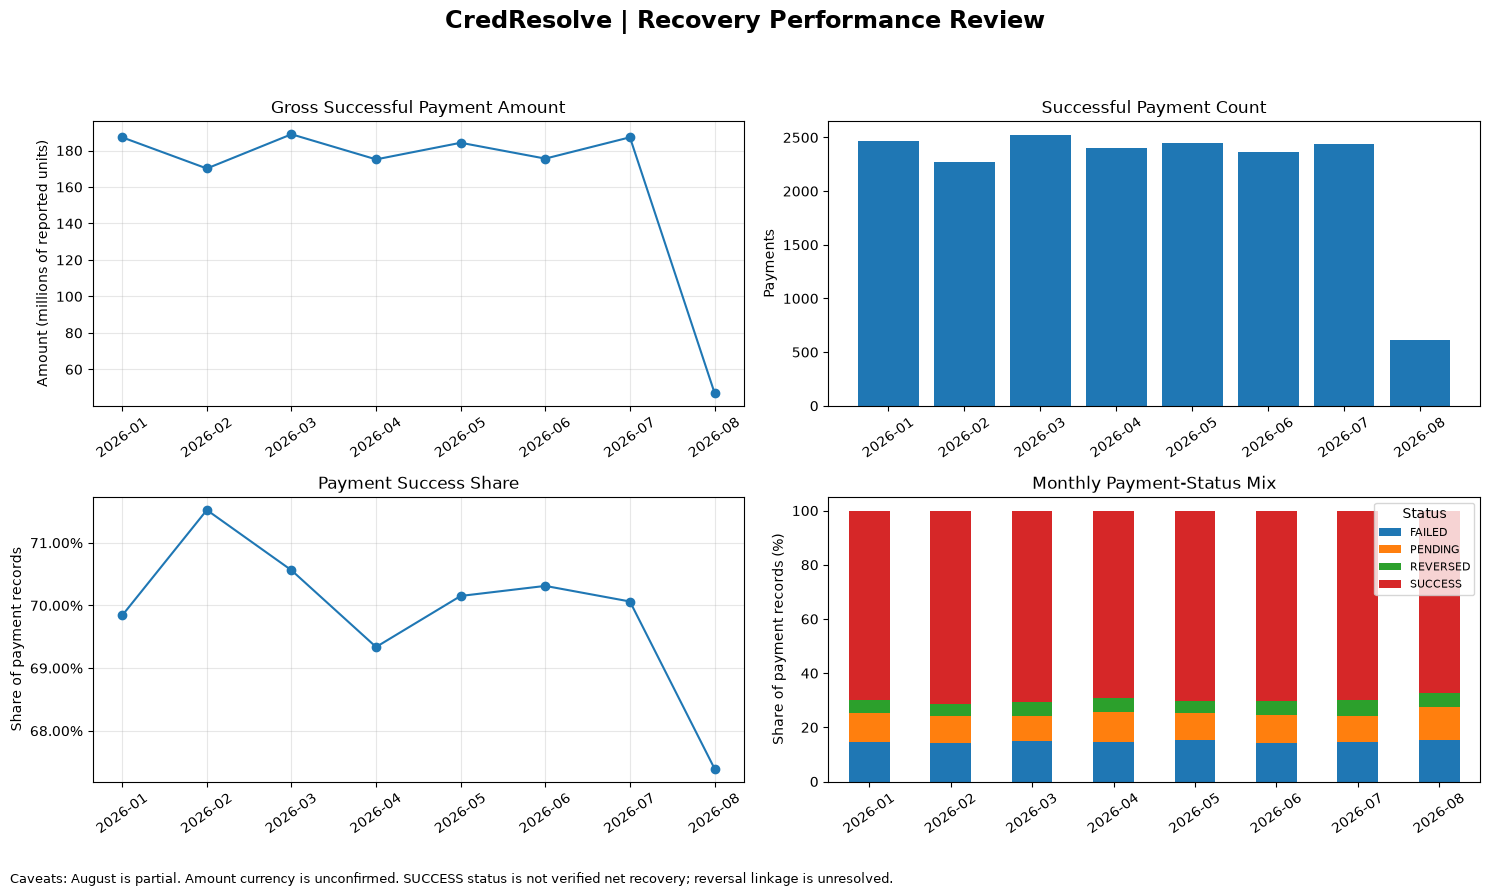

Dashboard saved: ..\reports\recovery_performance_dashboard.png
Monthly metrics saved: ..\reports\dashboard_monthly_metrics.csv
Status mix saved: ..\reports\dashboard_status_mix_pct.csv


In [ ]:

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

# Load the saved Golden payment candidate
golden_path = Path("../data/golden/payments_golden_candidate.csv")
reports_dir = Path("../reports")
reports_dir.mkdir(parents=True, exist_ok=True)

payments = pd.read_csv(golden_path)
payments["event_at"] = pd.to_datetime(payments["event_at"], errors="coerce")
payments["amount"] = pd.to_numeric(payments["amount"], errors="coerce")
payments["month"] = payments["event_at"].dt.to_period("M").astype(str)

# Exclude rows without a usable event timestamp from monthly analysis
payments = payments[payments["event_at"].notna()].copy()

monthly = (
    payments.groupby("month")
    .agg(
        payment_records=("payment_id", "size"),
        successful_payment_count=(
            "payment_status", lambda s: (s == "SUCCESS").sum()
        ),
        gross_successful_amount=(
            "amount",
            lambda s: s[
                payments.loc[s.index, "payment_status"] == "SUCCESS"
            ].sum()
        ),
    )
    .reset_index()
)

monthly["success_share"] = (
    monthly["successful_payment_count"] / monthly["payment_records"]
)

status_counts = pd.crosstab(
    payments["month"], payments["payment_status"], normalize="index"
) * 100

# Keep chronological month order
monthly = monthly.sort_values("month")
status_counts = status_counts.reindex(monthly["month"])

# Save dashboard source tables for reproducibility
monthly.to_csv(reports_dir / "dashboard_monthly_metrics.csv", index=False)
status_counts.to_csv(reports_dir / "dashboard_status_mix_pct.csv")

# Build a single-page dashboard
fig, axes = plt.subplots(2, 2, figsize=(15, 9))
fig.suptitle(
    "CredResolve | Recovery Performance Review",
    fontsize=17,
    fontweight="bold"
)

# 1. Gross successful payment amount
ax = axes[0, 0]
ax.plot(
    monthly["month"],
    monthly["gross_successful_amount"] / 1_000_000,
    marker="o"
)
ax.set_title("Gross Successful Payment Amount")
ax.set_ylabel("Amount (millions of reported units)")
ax.tick_params(axis="x", rotation=35)
ax.grid(True, alpha=0.3)

# 2. Successful payment count
ax = axes[0, 1]
ax.bar(monthly["month"], monthly["successful_payment_count"])
ax.set_title("Successful Payment Count")
ax.set_ylabel("Payments")
ax.tick_params(axis="x", rotation=35)

# 3. Payment success share
ax = axes[1, 0]
ax.plot(
    monthly["month"],
    monthly["success_share"] * 100,
    marker="o"
)
ax.set_title("Payment Success Share")
ax.set_ylabel("Share of payment records")
ax.yaxis.set_major_formatter(PercentFormatter(xmax=100))
ax.tick_params(axis="x", rotation=35)
ax.grid(True, alpha=0.3)

# 4. Payment-status mix
ax = axes[1, 1]
status_counts.plot(kind="bar", stacked=True, ax=ax)
ax.set_title("Monthly Payment-Status Mix")
ax.set_ylabel("Share of payment records (%)")
ax.set_xlabel("")
ax.tick_params(axis="x", rotation=35)
ax.legend(title="Status", fontsize=8)

fig.text(
    0.01, 0.01,
    "Caveats: August is partial. Amount currency is unconfirmed. "
    "SUCCESS status is not verified net recovery; reversal linkage is unresolved.",
    fontsize=9
)

fig.tight_layout(rect=[0, 0.045, 1, 0.94])

dashboard_path = reports_dir / "recovery_performance_dashboard.png"
fig.savefig(dashboard_path, dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)

print(f"Dashboard saved: {dashboard_path}")
print(f"Monthly metrics saved: {reports_dir / 'dashboard_monthly_metrics.csv'}")
print(f"Status mix saved: {reports_dir / 'dashboard_status_mix_pct.csv'}")
